# Proyecto MiBici — Data Wrangling y EDA

### Operaciones de aprendizaje automático (TC5044)

---

### Equipo 8

| Alumno | Matrícula |
|---|---|
| Mario Sánchez Valtierra | A01797169 |
| José Luis Cruz Valencia | A01204423 |
| José David Arreola Méndez | A01039723 |
| Bruno Alberto Guevara Pérez | A00965207 |

## Objetivo

Realizar un proceso de limpieza y análisis exploratorio de los registros de viajes de MiBici, utilizando los archivos mensuales de enero de 2020 a septiembre de 2026.

Se revisará la calidad de los datos, se identificarán posibles inconsistencias y se integrará la información de las estaciones para analizar los patrones de uso del sistema, la demanda por estación y los patrones de uso a lo largo del tiempo.

También se construirá una variable que represente la cantidad de viajes iniciados por estación y hora, con el fin de contar con una base para un futuro modelo de predicción de demanda.

## Contexto y definición del problema

MiBici es un sistema de bicicletas públicas que permite realizar viajes entre diferentes estaciones del Área Metropolitana de Guadalajara.

Los datos históricos contienen información de los viajes realizados, incluyendo las estaciones de origen y destino y los horarios de uso. Esta información permite estudiar cómo cambia la demanda a lo largo del tiempo y qué estaciones presentan mayor actividad.

El problema que buscamos abordar es conocer cuántos viajes podrían iniciarse en una estación durante una hora determinada. Esta información podría ayudar a identificar periodos de mayor demanda y apoyar la planeación de la disponibilidad de bicicletas.

Antes de realizar estos análisis, es necesario revisar la calidad de los registros, identificar posibles inconsistencias y verificar que la información de los viajes pueda relacionarse correctamente con la nomenclatura de las estaciones.

## Variable objetivo

La variable que buscamos predecir será **`Cantidad_viajes`**, definida como el número de viajes iniciados en una estación durante una hora.

Esta variable no se encuentra directamente en los archivos originales. La construiremos después de la limpieza, agrupando los registros por estación de origen (`Origen_Id`) y fecha y hora de inicio (`Inicio_del_viaje`).

También se considerarán las horas en las que una estación no registre viajes, para representar correctamente los periodos sin demanda.

En esta fase del proyecto construiremos y analizaremos la variable objetivo, pero no entrenaremos un modelo predictivo.

## Criterio de trabajo

Las decisiones de limpieza se tomarán a partir de los problemas identificados durante el diagnóstico y de las reglas establecidas en el Data Contract.

Se trabajará con dos estrategias de limpieza, A y B, para comparar cuántos registros conserva cada una y cómo afectan los resultados del análisis.

Los archivos originales se mantendrán sin modificaciones y los resultados se guardarán por separado.

## Estructura del notebook

| Parte | Descripción |
|---|---|
| **1. Setup** | Importación de librerías y configuración inicial |
| **2. Inventario de archivos** | Identificación de archivos, periodos y verificación de integridad |
| **3. Inspección inicial** | Revisión de la estructura de los viajes y la nomenclatura de estaciones |
| **4. Data Contract** | Definición de pruebas, esquemas, reglas de calidad y correcciones permitidas |
| **5. Carga y normalización** | Lectura de archivos y unificación de formatos |
| **6. Diagnóstico de calidad** | Ejecución de pruebas e identificación de inconsistencias |
| **7. Limpieza y validación** | Análisis de anomalías, implementación de las estrategias A y B, comparación de registros conservados y validación de resultados |
| **8. Construcción del target y EDA** | Cálculo de viajes iniciados por estación y hora, construcción de `Cantidad_viajes` y análisis de salidas por estación-hora |
| **9. Evaluación de rendimiento** | Medición de lectura, normalización, validación, limpieza, escritura y análisis horario |
| **10. Preparación para la refactorización** | Decisiones que debemos conservar y aspectos por mejorar |

## 1. Setup

Importamos las librerías necesarias para la lectura, procesamiento y análisis de los datos, así como para generar visualizaciones y registrar los resultados.

In [77]:
# Manejo de archivos y rutas
from pathlib import Path
from collections import Counter
import hashlib
import shutil

# Medición de tiempos
from time import perf_counter

# Manejo y análisis de datos
import numpy as np
import pandas as pd

# Lectura y escritura de archivos Parquet
import pyarrow as pa
import pyarrow.parquet as pq

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Seguimiento de experimentos
import mlflow

# Configuración de gráficas y tablas
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 2. Inventario de archivos

Revisamos los archivos disponibles para verificar que correspondan al periodo de enero de 2020 a septiembre de 2026.

También identificamos el tamaño de cada archivo y calculamos su hash SHA-256 para tener una referencia de los datos originales.

In [78]:
# Identificar el directorio de trabajo
CURRENT_DIR = Path.cwd()

# Buscar la raíz del proyecto
PROJECT_DIR = CURRENT_DIR

while not (PROJECT_DIR / "pyproject.toml").is_file():
    if PROJECT_DIR == PROJECT_DIR.parent:
        raise FileNotFoundError("No se encontró la raíz del proyecto.")

    PROJECT_DIR = PROJECT_DIR.parent

# Definir la carpeta de datos originales
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"

# Verificar que exista la carpeta
if not RAW_DATA_DIR.is_dir():
    raise FileNotFoundError("No se encontró la carpeta de datos originales.")

print("Directorio de trabajo:", CURRENT_DIR)
print("Raíz del proyecto:", PROJECT_DIR)
print("Datos originales:", RAW_DATA_DIR)
print("¿Existe la carpeta?", RAW_DATA_DIR.is_dir())


Directorio de trabajo: /home/josel/mlops/equipo-8-mibici-mlops/notebooks
Raíz del proyecto: /home/josel/mlops/equipo-8-mibici-mlops
Datos originales: /home/josel/mlops/equipo-8-mibici-mlops/data/raw
¿Existe la carpeta? True


### 2.1. Identificación de archivos CSV

Primero revisamos cuántos archivos CSV tenemos y mostramos sus nombres para verificar que estén disponibles antes de comenzar el análisis.

In [79]:
# Buscar los archivos CSV en todas las subcarpetas
csv_files = sorted(RAW_DATA_DIR.rglob("*.csv"))

# Mostrar la cantidad de archivos encontrados
print(f"Archivos CSV encontrados: {len(csv_files)}")

# Mostrar los primeros cinco archivos
for file_path in csv_files[:5]:
    print(file_path.relative_to(RAW_DATA_DIR))


Archivos CSV encontrados: 82
2020/datos_abiertos_2020_01.csv
2020/datos_abiertos_2020_02.csv
2020/datos_abiertos_2020_03.csv
2020/datos_abiertos_2020_04.csv
2020/datos_abiertos_2020_05.csv


### 2.2. Revisión de archivos por año

Revisamos la cantidad de archivos por año para identificar qué periodos están completos y cuáles tienen archivos faltantes.

In [80]:
# Crear el inventario de archivos
file_inventory = pd.DataFrame({
    "file_path": csv_files
})

# Identificar la carpeta de cada archivo
file_inventory["folder_name"] = [
    file_path.parent.name
    for file_path in csv_files
]

# Contar archivos por carpeta
files_per_folder = (
    file_inventory["folder_name"]
    .value_counts()
    .sort_index()
)

print(files_per_folder)


folder_name
2020            12
2021            12
2022            12
2023            12
2024            12
2025            12
2026             9
Manual_datos     1
Name: count, dtype: int64


### 2.3. Verificación de periodos

Verificamos que estén disponibles todos los archivos mensuales desde enero de 2020 hasta septiembre de 2026.

Comparamos los nombres encontrados con los esperados para identificar archivos faltantes o adicionales.


In [81]:
# Generar los nombres esperados de los archivos mensuales
expected_files = [
    f"datos_abiertos_{period.year}_{period.month:02d}.csv"
    for period in pd.period_range("2020-01", "2026-09", freq="M")
]

# Obtener los nombres de los archivos encontrados
actual_files = [
    file_path.name
    for file_path in csv_files
    if file_path.parent.name != "Manual_datos"
]

# Comparar los archivos esperados con los encontrados
missing_files = sorted(set(expected_files) - set(actual_files))
unexpected_files = sorted(set(actual_files) - set(expected_files))

# Mostrar resultados
print("Archivos mensuales esperados:", len(expected_files))
print("Archivos mensuales encontrados:", len(actual_files))
print("Archivos faltantes:", missing_files)
print("Archivos adicionales:", unexpected_files)


Archivos mensuales esperados: 81
Archivos mensuales encontrados: 81
Archivos faltantes: []
Archivos adicionales: []


### 2.4. Tamaño e integridad de los archivos

Registramos el tamaño de cada archivo y calculamos su hash SHA-256 para contar con una referencia de los datos originales.

También revisamos si existen archivos vacíos antes de comenzar la carga y el diagnóstico de los datos.

In [82]:
# Función para calcular el hash SHA-256
def calculate_sha256(file_path):
    with file_path.open("rb") as file:
        return hashlib.file_digest(file, "sha256").hexdigest()


# Obtener el tamaño de cada archivo en bytes
file_inventory["size_bytes"] = [
    file_path.stat().st_size
    for file_path in file_inventory["file_path"]
]

# Calcular el hash SHA-256 de cada archivo
file_inventory["sha256"] = [
    calculate_sha256(file_path)
    for file_path in file_inventory["file_path"]
]

# Identificar archivos vacíos
empty_files = file_inventory[
    file_inventory["size_bytes"] == 0
]

# Mostrar resultados
print("Archivos revisados:", len(file_inventory))
print("Archivos vacíos:", len(empty_files))

display(file_inventory)

Archivos revisados: 82
Archivos vacíos: 0


,file_path,folder_name,size_bytes,sha256
0,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2020,25868844,4a4b4af9616209382e04e33c82e99b3f81b12afe23ee42...
1,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2020,26421202,54c09bfaf6b76b6b709e7351248e16949c987ad27199dc...
2,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2020,21320439,e19bd0c75f439e752ac691afbefb115178f893e2ea5975...
3,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2020,9291472,dc2e43a609e14ad5e4ff0838b7fcb25bcf809af2ec7d5a...
4,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2020,11528686,4fbbfa62bfd793680bdf27e699aeab17b8d677406821c2...
...,...,...,...,...
77,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2026,30826027,a4d195786a3599b155829288a0432cd9e76c6780dc693c...
78,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2026,33696291,3f9db9fed985977b175001a984302eae7c61326a75ed93...
79,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2026,34158210,e34f39b9ad204ae0b66f3538894a5f86ed03f46d987011...
80,/home/josel/mlops/equipo-8-mibici-mlops/data/r...,2026,42566896,00b5cf64cc31a502d01044d905f6e033f9bc1db962e771...


## 3. Inspección inicial de los datos

En esta sección revisamos la estructura de los archivos mensuales de MiBici y la nomenclatura de estaciones antes de comenzar el procesamiento.

Primero inspeccionamos las columnas y los tipos de datos de un archivo mensual. Después comparamos los encabezados de los 81 archivos para identificar posibles diferencias.

Finalmente, revisamos la estructura del archivo de estaciones para conocer qué información contiene y cómo podremos relacionarla con los registros de viajes.

Esta inspección nos servirá como referencia para definir las reglas del Data Contract.

### 3.1. Inspección inicial

Revisamos las primeras filas de un archivo mensual para identificar sus columnas, tipos de datos y formato.

Seleccionamos el archivo a partir del inventario generado previamente, manteniendo un criterio de selección consistente.

In [83]:
# Seleccionar los archivos mensuales del inventario
monthly_files = sorted(
    file_path
    for file_path in csv_files
    if file_path.parent.name != "Manual_datos"
)

# Verificar que existan archivos mensuales
if not monthly_files:
    raise FileNotFoundError("No se encontraron archivos mensuales.")

# Seleccionar el primer archivo mensual
sample_file = monthly_files[0]

# Leer las primeras cinco filas
sample_data = pd.read_csv(sample_file, nrows=5)

# Mostrar la estructura inicial
print("Archivo:", sample_file.name)
print("Dimensiones:", sample_data.shape)
print("\nColumnas y tipos de datos:")
print(sample_data.dtypes)

display(sample_data)

Archivo: datos_abiertos_2020_01.csv
Dimensiones: (5, 8)

Columnas y tipos de datos:
Viaje_Id               int64
Usuario_Id             int64
Genero                   str
Año_de_nacimiento    float64
Inicio_del_viaje         str
Fin_del_viaje            str
Origen_Id              int64
Destino_Id             int64
dtype: object


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,14420217,451617,M,1992.0,2020-01-01 06:02:20,2020-01-01 06:05:38,52,268
1,14420218,324211,M,1985.0,2020-01-01 06:02:22,2020-01-01 06:07:32,254,180
2,14420219,611633,M,1981.0,2020-01-01 06:03:01,2020-01-01 06:21:43,258,278
3,14420220,521601,M,1989.0,2020-01-01 06:05:48,2020-01-01 06:15:11,200,201
4,14420221,631227,M,1979.0,2020-01-01 06:08:15,2020-01-01 06:29:33,151,248


### 3.2. Verificación de estructura

Revisamos las columnas de los 81 archivos mensuales para identificar posibles diferencias antes de integrarlos.

Esta revisión nos permitirá detectar columnas faltantes o adicionales sin cargar todos los registros en memoria.

In [84]:
# Obtener las columnas de referencia
expected_columns = sample_data.columns.tolist()

# Revisar las columnas de cada archivo mensual
schema_results = []

for file_path in monthly_files:
    try:
        current_columns = pd.read_csv(
            file_path, nrows=0, encoding="utf-8"
        ).columns.tolist()
        file_encoding = "utf-8"

    except UnicodeDecodeError:
        current_columns = pd.read_csv(
            file_path, nrows=0, encoding="cp1252"
        ).columns.tolist()
        file_encoding = "cp1252"

    schema_results.append({
        "file_name": file_path.name,
        "encoding": file_encoding,
        "column_count": len(current_columns),
        "schema_matches": current_columns == expected_columns,
        "missing_columns": sorted(set(expected_columns) - set(current_columns)),
        "extra_columns": sorted(set(current_columns) - set(expected_columns))
    })

# Crear una tabla con los resultados
schema_validation = pd.DataFrame(schema_results)

# Mostrar el resumen
print("Archivos revisados:", len(schema_validation))
print("Estructuras coincidentes:", schema_validation["schema_matches"].sum())
print("Estructuras diferentes:", (~schema_validation["schema_matches"]).sum())

print("\nCodificaciones utilizadas:")
print(schema_validation["encoding"].value_counts())

display(schema_validation)

Archivos revisados: 81
Estructuras coincidentes: 79
Estructuras diferentes: 2

Codificaciones utilizadas:
encoding
cp1252    43
utf-8     38
Name: count, dtype: int64


,file_name,encoding,column_count,schema_matches,missing_columns,extra_columns
0,datos_abiertos_2020_01.csv,utf-8,8,True,[],[]
1,datos_abiertos_2020_02.csv,utf-8,8,True,[],[]
2,datos_abiertos_2020_03.csv,utf-8,8,True,[],[]
3,datos_abiertos_2020_04.csv,utf-8,8,True,[],[]
4,datos_abiertos_2020_05.csv,utf-8,8,True,[],[]
...,...,...,...,...,...,...
76,datos_abiertos_2026_05.csv,utf-8,8,True,[],[]
77,datos_abiertos_2026_06.csv,utf-8,8,True,[],[]
78,datos_abiertos_2026_07.csv,utf-8,8,True,[],[]
79,datos_abiertos_2026_08.csv,utf-8,8,True,[],[]


#### Identificación de estructuras diferentes

Revisamos los archivos que presentan diferencias respecto a las columnas de referencia para determinar si tienen columnas faltantes, adicionales o un orden distinto.

In [85]:
# Seleccionar los archivos con estructuras diferentes
schema_differences = schema_validation[
    ~schema_validation["schema_matches"]
]

# Mostrar los archivos y sus diferencias
display(schema_differences)

,file_name,encoding,column_count,schema_matches,missing_columns,extra_columns
49,datos_abiertos_2024_02.csv,cp1252,8,False,[Año_de_nacimiento],[A}äe_nacimiento]
52,datos_abiertos_2024_05.csv,cp1252,8,False,[Año_de_nacimiento],[A}äe_nacimiento]


#### Revisión de encabezados inconsistentes

Revisamos los encabezados originales de los dos archivos que presentan diferencias para determinar si el problema está relacionado con la codificación o con los nombres almacenados en los CSV.

In [86]:
# Revisar los encabezados originales de los archivos inconsistentes
for file_path in monthly_files:
    if file_path.name in schema_differences["file_name"].values:
        with file_path.open("rb") as file:
            header = file.readline()

        print("Archivo:", file_path.name)
        print("Encabezado original:", header)
        print()

Archivo: datos_abiertos_2024_02.csv
Encabezado original: b'"Viaje_Id","Usuario_Id","Genero","A}\xe4e_nacimiento","Inicio_del_viaje","Fin_del_viaje","Origen_Id","Destino_Id"\n'

Archivo: datos_abiertos_2024_05.csv
Encabezado original: b'"Viaje_Id","Usuario_Id","Genero","A}\xe4e_nacimiento","Inicio_del_viaje","Fin_del_viaje","Origen_Id","Destino_Id"\n'



#### Resultados de la verificación de estructura

De los 81 archivos revisados, 79 tienen las mismas columnas. En los archivos de febrero y mayo de 2024 encontramos que la columna `Año_de_nacimiento` aparece como `A}äe_nacimiento`.

Al revisar los encabezados originales, confirmamos que el nombre ya viene así en ambos CSV. También encontramos diferencias en la codificación de los archivos: 38 se pudieron leer con UTF-8 y 43 necesitaron CP1252 para leer sus encabezados.

Tomaremos en cuenta estas diferencias durante la carga para que todos los archivos tengan la misma estructura, sin modificar los datos originales.

### 3.3. Inspección de nomenclatura de estaciones

Revisamos el archivo de nomenclatura para identificar sus columnas, tipos de datos y algunos registros de ejemplo. Esta información nos permitirá definir el Data Contract y conocer cómo relacionar las estaciones con los registros de viajes.

En esta etapa únicamente inspeccionamos el archivo, sin modificar los datos originales.

In [87]:
# Identificar el archivo de nomenclatura
station_files = [
    file_path
    for file_path in csv_files
    if file_path.parent.name == "Manual_datos"
]

# Verificar que exista un único archivo
if len(station_files) != 1:
    raise ValueError(
        f"Se esperaba un archivo de nomenclatura y se encontraron {len(station_files)}."
    )

# Seleccionar el archivo
station_file = station_files[0]

# Leer una muestra del archivo
try:
    station_sample = pd.read_csv(
        station_file,
        nrows=5,
        encoding="utf-8"
    )
    station_encoding = "utf-8"
except UnicodeDecodeError:
    station_sample = pd.read_csv(
        station_file,
        nrows=5,
        encoding="cp1252"
    )
    station_encoding = "cp1252"

# Mostrar los resultados
print("Archivo:", station_file.name)
print("Codificación:", station_encoding)
print("Dimensiones de la muestra:", station_sample.shape)
print("\nColumnas y tipos de datos:")
print(station_sample.dtypes)

display(station_sample)

Archivo: nomenclatura_2026_09.csv
Codificación: utf-8
Dimensiones de la muestra: (5, 5)

Columnas y tipos de datos:
id              int64
name              str
latitude      float64
longitude     float64
dpcapacity      int64
dtype: object


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


## 4. Data Contract

Antes de realizar la limpieza, definimos la estructura que deben tener los datos y las pruebas que utilizaremos para revisar su calidad.

Tomamos como referencia la inspección inicial de los archivos y el problema que buscamos resolver: analizar la demanda horaria de viajes por estación.

### Pruebas de calidad de los datos

Al igual que en la actividad anterior de Data Wrangling, organizamos las pruebas de calidad en una tabla que indica qué revisaremos, las variables involucradas y la acción que consideraremos si encontramos problemas.

| # | Prueba | Variables | Acción si se detecta un problema |
|---|---|---|---|
| P01 | **Esquema:** ¿Las columnas coinciden con el Data Contract? | Viajes y estaciones | Identificar columnas faltantes, adicionales o con nombres incorrectos |
| P02 | **Tipos:** ¿Los valores corresponden al tipo de dato esperado? | Todas las columnas | Convertir valores cuando sea posible e identificar conversiones fallidas |
| P03 | **Espacios:** ¿Existen espacios innecesarios al inicio o al final? | Columnas de texto | Eliminar espacios adicionales |
| P04 | **Tokens inválidos:** ¿Existen valores como `?`, `n/a`, `null` o `error`? | Columnas de texto | Identificar los tokens y tratarlos como faltantes cuando corresponda |
| P05 | **Valores faltantes:** ¿Cuántos valores faltantes existen por columna? | Todas las columnas | Evaluar su impacto según la importancia de cada variable |
| P06 | **Dominio:** ¿Los valores cumplen los rangos y categorías definidos? | Género, año de nacimiento, fechas, coordenadas y capacidad | Identificar valores fuera de los límites establecidos |
| P07 | **Consistencia:** ¿Se cumplen las relaciones entre variables? | Fechas, duración e identificadores de estaciones | Revisar registros inconsistentes |
| P08 | **Variable objetivo:** ¿La demanda horaria se calcula correctamente? | `demanda_horaria` | Comprobar que los conteos sean enteros no negativos y que se calculen con viajes válidos |
| P09 | **Duplicados:** ¿Existen registros repetidos? | `Viaje_Id` e `id` de estaciones | Revisar los duplicados antes de decidir su tratamiento |

Estas pruebas se ejecutarán durante el diagnóstico de calidad. La prueba P08 se realizará después de construir la variable objetivo.

### Clasificación de las reglas

Las reglas específicas del Data Contract se clasificarán según su importancia:

| Severidad | Descripción |
|---|---|
| `critical` | El archivo o registro no puede utilizarse para calcular la demanda sin corregir el problema. |
| `warning` | Se detecta una posible inconsistencia que debemos revisar, pero que no necesariamente impide utilizar el registro. |

Utilizaremos los identificadores F01–F04 para las reglas de archivo, T01–T14 para los registros de viajes y S01–S06 para la nomenclatura de estaciones.

In [88]:
# Definir las pruebas generales de calidad
QUALITY_TESTS = [
    ("P01", "Esquema", "Viajes y estaciones",
     "Identificar columnas faltantes, adicionales o incorrectas"),
    ("P02", "Tipos de datos", "Todas las columnas",
     "Convertir valores e identificar conversiones fallidas"),
    ("P03", "Espacios", "Columnas de texto",
     "Eliminar espacios adicionales"),
    ("P04", "Tokens inválidos", "Columnas de texto",
     "Identificar tokens y evaluar su tratamiento como faltantes"),
    ("P05", "Valores faltantes", "Todas las columnas",
     "Evaluar su impacto según la importancia de cada variable"),
    ("P06", "Dominio", "Variables con rangos o categorías definidos",
     "Identificar valores fuera de los límites establecidos"),
    ("P07", "Consistencia", "Fechas e identificadores de estaciones",
     "Revisar registros inconsistentes"),
    ("P08", "Variable objetivo", "Cantidad_viajes",
     "Verificar conteos enteros no negativos calculados con viajes válidos"),
    ("P09", "Duplicados", "Viaje_Id e id de estaciones",
     "Revisar duplicados antes de decidir su tratamiento")
]

### 4.1. Definición de la variable objetivo

Buscamos predecir cuántos viajes comenzarán en cada estación durante una hora determinada. Para ello, definimos la variable objetivo `Cantidad_viajes`, que representa el número de viajes iniciados por estación y hora.

Utilizaremos `Inicio_del_viaje` para identificar la hora y `Origen_Id` para conocer la estación. También revisaremos `Viaje_Id` para evitar contar registros duplicados.

Por ejemplo, si un viaje comienza a las 07:42, se contará dentro del intervalo de 07:00 a 08:00.

También consideraremos las horas en las que no se registraron viajes. Como los archivos no incluyen las fechas de apertura o cierre de las estaciones, durante el procesamiento revisaremos los periodos en los que aparecen registros de cada estación para definir cómo tratar las horas sin viajes.

La variable objetivo se calculará después de revisar y preparar los registros.

### 4.2. Esquema de los archivos de viajes

A partir de la inspección inicial, definimos las ocho columnas que deben contener los archivos mensuales, respetando sus nombres y el orden en que aparecen.

En `TRIP_SCHEMA` estableceremos el tipo de dato esperado para cada columna. Los identificadores utilizarán `Int64`, que permite trabajar con números enteros y valores faltantes. Para el año de nacimiento utilizaremos `Float64`, mientras que las fechas se leerán inicialmente como texto para revisar su formato antes de convertirlas.

También definiremos las codificaciones encontradas durante la exploración y la corrección del encabezado `A}äe_nacimiento`, identificado en dos archivos de 2024.

Por último, estableceremos las reglas que deben cumplir los archivos antes de procesar sus registros. Cada regla tendrá un identificador, una descripción y un nivel de severidad.

Durante la revisión encontramos dos formatos de fecha, por lo que ambos se considerarán durante la normalización.

In [89]:
TRIP_SCHEMA = {
    "Viaje_Id": "Int64",
    "Usuario_Id": "Int64",
    "Genero": "str",
    "Año_de_nacimiento": "Float64",
    "Inicio_del_viaje": "str",
    "Fin_del_viaje": "str",
    "Origen_Id": "Int64",
    "Destino_Id": "Int64"
}

# Definir los formatos de fecha identificados
DATETIME_FORMAT = "%Y-%m-%d %H:%M:%S"
ALTERNATIVE_DATETIME_FORMAT = "%d/%m/%Y %H:%M"

# Definir las codificaciones permitidas
ALLOWED_ENCODINGS = ["utf-8", "cp1252"]

# Corregir los nombres de columnas conocidos
COLUMN_MAPPING = {
    "A}äe_nacimiento": "Año_de_nacimiento"
}

# Definir las reglas de los archivos
FILE_RULES = [
    ("F01", "(archivo)", "Un archivo por mes de 2020-01 a 2026-09", "critical"),
    ("F02", "(archivo)", "Tamaño mayor que cero", "critical"),
    ("F03", "(archivo)", "Codificación incluida en ALLOWED_ENCODINGS", "critical"),
    ("F04", "(archivo)", "Columnas iguales a TRIP_SCHEMA después de COLUMN_MAPPING", "critical")
]

### 4.3. Reglas de calidad de los viajes

Definimos las reglas para revisar identificadores, género, edad, fechas, estaciones y duración de los viajes.

Para género aceptaremos únicamente `M` y `F`. La edad estimada se calculará con el año del viaje y deberá estar entre 10 y 100 años. Mantendremos el intervalo de duración de 1 minuto a 3 horas como criterio inicial.

Las reglas críticas corresponden principalmente a los datos necesarios para calcular la demanda horaria. Las demás inconsistencias se registrarán como advertencias para revisar su impacto antes de aplicar correcciones.

In [90]:
# Definir el periodo de estudio (fecha final excluida)
STUDY_START = pd.Timestamp("2020-01-01")
STUDY_END = pd.Timestamp("2026-10-01")

# Definir los valores permitidos de género
VALID_GENDERS = ["M", "F"]

# Definir los límites de edad estimada
MIN_AGE = 10
MAX_AGE = 100

# Definir el rango de duración de los viajes
MIN_TRIP_DURATION = pd.Timedelta(minutes=1)
MAX_TRIP_DURATION = pd.Timedelta(hours=3)

# Definir las reglas de calidad de los viajes
TRIP_RULES = [
    ("T01", "Viaje_Id",
     "Obligatorio y único en todo el periodo", "critical"),
    ("T02", "Usuario_Id",
     "Obligatorio", "warning"),
    ("T03", "Genero",
     "Valor incluido en VALID_GENDERS o faltante", "warning"),
    ("T04", "Año_de_nacimiento",
     "Edad estimada entre MIN_AGE y MAX_AGE en el año del viaje, o faltante", "warning"),
    ("T05", "Inicio_del_viaje",
     "Obligatorio y convertible con los formatos de fecha definidos", "critical"),
    ("T06", "Inicio_del_viaje",
     "Dentro del periodo de STUDY_START a STUDY_END", "critical"),
    ("T07", "Inicio_del_viaje",
     "Dentro del mes indicado en el nombre del archivo", "warning"),
    ("T08", "Fin_del_viaje",
     "Obligatorio y convertible con los formatos de fecha definidos", "warning"),
    ("T09", "Fin_del_viaje",
     "Igual o posterior a Inicio_del_viaje", "warning"),
    ("T10", "Fin_del_viaje",
     "Duración entre MIN_TRIP_DURATION y MAX_TRIP_DURATION", "warning"),
    ("T11", "Origen_Id",
     "Obligatorio", "critical"),
    ("T12", "Origen_Id",
     "Existe en la nomenclatura de estaciones", "warning"),
    ("T13", "Destino_Id",
     "Obligatorio", "warning"),
    ("T14", "Destino_Id",
     "Existe en la nomenclatura de estaciones", "warning")
]

### 4.4. Esquema y reglas de la nomenclatura de estaciones

En esta sección definimos la estructura y las reglas de calidad del archivo `nomenclatura_2026_09.csv`, que contiene la información de las estaciones de MiBici.

Revisaremos que los identificadores sean únicos, que las estaciones tengan nombre y que sus coordenadas y capacidades sean válidas.

Para validar las coordenadas utilizaremos como referencia los límites geográficos del estado de Jalisco publicados por el Instituto de Información Estadística y Geográfica de Jalisco (IIEG). Redondeamos estos valores hacia afuera para establecer rangos sencillos de latitud (18° a 23°) y longitud (-106° a -101°).

**Fuente:**
- Instituto de Información Estadística y Geográfica de Jalisco (IIEG). *Límite municipal de Jalisco*. https://seijal.jalisco.gob.mx/datos-abiertos/es/dataset/limite-municipal-jalisco-iieg

In [91]:
# Definir las columnas esperadas de la nomenclatura
STATION_SCHEMA = {
    "id": "Int64",
    "name": "str",
    "latitude": "float64",
    "longitude": "float64",
    "dpcapacity": "Int64"
}

# Límites geográficos aproximados de Jalisco
MIN_LATITUDE = 18
MAX_LATITUDE = 23
MIN_LONGITUDE = -106
MAX_LONGITUDE = -101

# Fuente de referencia para los límites geográficos
GEOGRAPHIC_SOURCE = (
    "https://seijal.jalisco.gob.mx/datos-abiertos/es/"
    "dataset/limite-municipal-jalisco-iieg"
)

# Definir las reglas de calidad de las estaciones
STATION_RULES = [
    ("S01", "(archivo)",
     "Columnas iguales a STATION_SCHEMA", "critical"),
    ("S02", "id",
     "Obligatorio y único", "critical"),
    ("S03", "name",
     "Obligatorio", "warning"),
    ("S04", "latitude",
     "Entre MIN_LATITUDE y MAX_LATITUDE", "warning"),
    ("S05", "longitude",
     "Entre MIN_LONGITUDE y MAX_LONGITUDE", "warning"),
    ("S06", "dpcapacity",
     "Obligatorio y mayor que cero", "warning")
]

### 4.5. Correcciones permitidas

En esta sección definimos qué correcciones podremos aplicar durante la limpieza de los datos, tomando como referencia las reglas del Data Contract y los resultados del diagnóstico.

Consideraremos correcciones de formato, como unificar nombres de columnas, convertir tipos de datos y eliminar espacios innecesarios.

También revisaremos los registros duplicados y los valores inválidos antes de decidir cómo tratarlos. No eliminaremos información automáticamente sin evaluar primero el problema y su impacto en el análisis.

Las correcciones se realizarán durante la etapa de limpieza, sin modificar los archivos CSV originales.

In [92]:
# Definir las correcciones permitidas
ALLOWED_CORRECTIONS = [
    ("C01", "Columnas",
     "Renombrar columnas conocidas mediante COLUMN_MAPPING"),
    ("C02", "Tipos de datos",
     "Convertir columnas a los tipos definidos en el contrato"),
    ("C03", "Texto",
     "Eliminar espacios al inicio y al final"),
    ("C04", "Fechas",
     "Convertir fechas utilizando DATETIME_FORMAT"),
    ("C05", "Duplicados",
     "Revisar registros con Viaje_Id repetido antes de decidir su tratamiento"),
    ("C06", "Registros inválidos",
     "Excluir del análisis de demanda los viajes sin inicio u origen válido")
]

### 4.6. Esquema de datos enriquecidos

Utilizaremos la nomenclatura de estaciones para agregar el nombre, las coordenadas y la capacidad de las estaciones de origen y destino.

Para relacionar los archivos, utilizaremos `Origen_Id` y `Destino_Id` de los viajes con la columna `id` de la nomenclatura. Mantendremos las ocho columnas originales y agregaremos ocho nuevas, para tener un total de 16 columnas.

La unión será de tipo `left` para conservar los viajes aunque alguna estación no aparezca en la nomenclatura. En esos casos, las columnas nuevas quedarán con valores faltantes.

In [93]:
# Definir los atributos que se agregarán desde la nomenclatura
STATION_ATTRIBUTES = {
    "name": "nombre",
    "latitude": "latitud",
    "longitude": "longitud",
    "dpcapacity": "capacidad"
}

# Definir las columnas adicionales para origen y destino
ORIGIN_COLUMNS = {
    column: f"{attribute}_origen"
    for column, attribute in STATION_ATTRIBUTES.items()
}

DESTINATION_COLUMNS = {
    column: f"{attribute}_destino"
    for column, attribute in STATION_ATTRIBUTES.items()
}

# Definir el esquema esperado después de la integración
ENRICHED_SCHEMA = {
    **TRIP_SCHEMA,
    "nombre_origen": "str",
    "latitud_origen": "float64",
    "longitud_origen": "float64",
    "capacidad_origen": "Int64",
    "nombre_destino": "str",
    "latitud_destino": "float64",
    "longitud_destino": "float64",
    "capacidad_destino": "Int64"
}

# Verificar la cantidad de columnas esperadas
assert len(ENRICHED_SCHEMA) == 16

print("Columnas originales:", len(TRIP_SCHEMA))
print("Columnas adicionales:", len(ENRICHED_SCHEMA) - len(TRIP_SCHEMA))
print("Total de columnas esperadas:", len(ENRICHED_SCHEMA))

Columnas originales: 8
Columnas adicionales: 8
Total de columnas esperadas: 16


### 4.7. Verificación del Data Contract

Comprobaremos que las reglas tengan identificadores únicos, que el esquema enriquecido conserve las columnas originales y que los límites definidos sean consistentes.

In [94]:
# Reunir las reglas del Data Contract
contract_rules = FILE_RULES + TRIP_RULES + STATION_RULES

# Obtener los identificadores de las reglas
rule_ids = [rule[0] for rule in contract_rules]

# Verificar que los identificadores no estén repetidos
assert len(rule_ids) == len(set(rule_ids)), (
    "Hay reglas con identificadores repetidos."
)

# Verificar que se conserven las columnas originales
assert set(TRIP_SCHEMA).issubset(ENRICHED_SCHEMA), (
    "Faltan columnas originales."
)

# Verificar el número de columnas esperado
assert len(ENRICHED_SCHEMA) == 16, (
    "El esquema debe tener 16 columnas."
)

# Verificar los criterios de calidad definidos
assert set(VALID_GENDERS) == {"M", "F"}, (
    "Las categorías de género no coinciden con el contrato."
)

assert 0 <= MIN_AGE < MAX_AGE, (
    "Los límites de edad no son válidos."
)

assert pd.Timedelta(0) < MIN_TRIP_DURATION < MAX_TRIP_DURATION, (
    "Los límites de duración no son válidos."
)

assert STUDY_START < STUDY_END, (
    "El periodo de estudio no es válido."
)

# Mostrar el resumen
print("Reglas definidas:", len(contract_rules))
print("Pruebas de calidad:", len(QUALITY_TESTS))
print("Columnas originales:", len(TRIP_SCHEMA))
print("Columnas enriquecidas:", len(ENRICHED_SCHEMA))
print("Verificación completada.")

Reglas definidas: 24
Pruebas de calidad: 9
Columnas originales: 8
Columnas enriquecidas: 16
Verificación completada.


### 4.8. Resumen del Data Contract

Definimos los esquemas, las reglas de calidad y los criterios de limpieza que utilizaremos durante el procesamiento de los datos.

También establecimos las columnas que agregaremos a partir de la nomenclatura de estaciones y verificamos que las definiciones principales fueran consistentes.

Con esto terminamos el Data Contract. Las pruebas de calidad y las correcciones se realizarán en las siguientes etapas.

## 5. Carga y normalización de datos

En esta sección cargaremos los archivos de viajes y unificaremos sus formatos para poder analizarlos.

Considerando el volumen de registros, realizaremos la lectura por bloques para reducir el uso de memoria. También corregiremos las diferencias conocidas en los nombres de las columnas y prepararemos los tipos de datos de acuerdo con el Data Contract.

Los archivos originales se conservarán sin modificaciones.

### 5.1. Conteo de registros por archivo

Primero revisaremos cuántos registros contiene cada archivo mensual y calcularemos el total del periodo.

Este conteo nos permitirá conocer el volumen de datos que vamos a procesar y detectar archivos con cantidades de registros inusuales.

In [95]:
# Contar los registros de cada archivo mensual
record_counts = []

for file_path in monthly_files:
    with open(file_path, "rb") as file:
        row_count = sum(1 for line in file) - 1

    record_counts.append({
        "file_name": file_path.name,
        "record_count": row_count
    })

# Organizar los resultados
record_counts_df = pd.DataFrame(record_counts)

# Calcular el total de registros
total_records = record_counts_df["record_count"].sum()

print("Archivos revisados:", len(record_counts_df))
print("Total de registros:", f"{total_records:,}")

display(record_counts_df)

Archivos revisados: 81
Total de registros: 27,086,557


,file_name,record_count
0,datos_abiertos_2020_01.csv,360276
1,datos_abiertos_2020_02.csv,367864
2,datos_abiertos_2020_03.csv,296759
3,datos_abiertos_2020_04.csv,129276
4,datos_abiertos_2020_05.csv,160437
...,...,...
76,datos_abiertos_2026_05.csv,315895
77,datos_abiertos_2026_06.csv,355303
78,datos_abiertos_2026_07.csv,388257
79,datos_abiertos_2026_08.csv,393524


### 5.2. Lectura por bloques y normalización de columnas

Leeremos los archivos por bloques de 10,000 registros para evitar cargar toda la información en memoria.

Primero probaremos la lectura con uno de los archivos que presenta diferencias en sus encabezados. Utilizaremos el mapeo definido en el Data Contract para corregir los nombres de las columnas y comprobar que coincidan con el esquema esperado.

In [96]:
# Definir la cantidad de registros por bloque
CHUNK_SIZE = 10000

# Seleccionar un archivo con diferencias en los encabezados
test_file = next(
    file_path for file_path in monthly_files
    if file_path.name == "datos_abiertos_2024_02.csv"
)

# Obtener la codificación identificada en la inspección inicial
test_encoding = schema_validation.loc[
    schema_validation["file_name"] == test_file.name,
    "encoding"
].iloc[0]

# Leer el archivo por bloques
reader = pd.read_csv(
    test_file,
    encoding=test_encoding,
    chunksize=CHUNK_SIZE
)

# Obtener el primer bloque
test_chunk = next(reader)

# Corregir los nombres de las columnas conocidas
test_chunk = test_chunk.rename(columns=COLUMN_MAPPING)

# Comprobar que las columnas coincidan con el contrato
assert list(test_chunk.columns) == list(TRIP_SCHEMA), (
    "Las columnas no coinciden con el Data Contract."
)

print("Archivo:", test_file.name)
print("Codificación:", test_encoding)
print("Registros del bloque:", len(test_chunk))
print("Columnas:", len(test_chunk.columns))
print("Esquema de columnas correcto.")

display(test_chunk.head())

Archivo: datos_abiertos_2024_02.csv
Codificación: cp1252
Registros del bloque: 10000
Columnas: 8
Esquema de columnas correcto.


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,32244898,133007,M,1994.0,2024-02-01 00:01:46,2024-02-01 00:13:00,62,195
1,32244900,2524051,F,1997.0,2024-02-01 00:02:26,2024-02-01 00:12:41,196,25
2,32244901,1431452,M,2001.0,2024-02-01 00:02:36,2024-02-01 00:02:39,383,383
3,32244902,1405511,F,1969.0,2024-02-01 00:02:52,2024-02-01 00:14:38,66,14
4,32244903,276725,M,1990.0,2024-02-01 00:02:57,2024-02-01 00:12:17,75,179


### 5.3. Comprobación de lectura de los archivos mensuales

Revisaremos la lectura de los 81 archivos utilizando las codificaciones identificadas anteriormente.

Para cada archivo leeremos un bloque de 10,000 registros, corregiremos los nombres de las columnas cuando sea necesario y comprobaremos que coincidan con el esquema definido en el Data Contract.

Guardaremos los resultados de esta revisión para identificar los archivos que presenten problemas. Los CSV originales no se modificarán.

In [97]:
# Guardar los resultados de la revisión
reading_results = []

# Recorrer los archivos mensuales
for file_path in monthly_files:

    # Obtener la codificación identificada anteriormente
    file_encoding = schema_validation.loc[
        schema_validation["file_name"] == file_path.name,
        "encoding"
    ].iloc[0]

    try:
        # Leer únicamente el primer bloque
        chunk = pd.read_csv(
            file_path,
            encoding=file_encoding,
            nrows=CHUNK_SIZE
        )

        # Corregir los nombres de las columnas
        chunk = chunk.rename(columns=COLUMN_MAPPING)

        # Comprobar el esquema
        schema_matches = list(chunk.columns) == list(TRIP_SCHEMA)

        reading_results.append({
            "file_name": file_path.name,
            "encoding": file_encoding,
            "rows_read": len(chunk),
            "schema_matches": schema_matches,
            "error": None
        })

    except (OSError, UnicodeError, pd.errors.ParserError) as error:
        reading_results.append({
            "file_name": file_path.name,
            "encoding": file_encoding,
            "rows_read": 0,
            "schema_matches": False,
            "error": str(error)
        })

# Organizar los resultados
reading_validation = pd.DataFrame(reading_results)

# Mostrar el resumen
print("Archivos revisados:", len(reading_validation))
print("Esquemas correctos:", reading_validation["schema_matches"].sum())
print("Archivos con problemas:", (~reading_validation["schema_matches"]).sum())

display(reading_validation)

Archivos revisados: 81
Esquemas correctos: 81
Archivos con problemas: 0


,file_name,encoding,rows_read,schema_matches,error
0,datos_abiertos_2020_01.csv,utf-8,10000,True,None
1,datos_abiertos_2020_02.csv,utf-8,10000,True,None
2,datos_abiertos_2020_03.csv,utf-8,10000,True,None
3,datos_abiertos_2020_04.csv,utf-8,10000,True,None
4,datos_abiertos_2020_05.csv,utf-8,10000,True,None
...,...,...,...,...,...
76,datos_abiertos_2026_05.csv,utf-8,10000,True,None
77,datos_abiertos_2026_06.csv,utf-8,10000,True,None
78,datos_abiertos_2026_07.csv,utf-8,10000,True,None
79,datos_abiertos_2026_08.csv,utf-8,10000,True,None


### 5.4. Normalización de tipos de datos

Revisaremos los tipos de datos de las columnas y realizaremos las conversiones necesarias de acuerdo con el Data Contract.

Utilizaremos un bloque de registros para comprobar que los identificadores y el año de nacimiento sean numéricos, que el género se maneje como texto y que las fechas puedan convertirse al formato establecido.

Por ahora solo probaremos las conversiones. Más adelante aplicaremos el procedimiento a todos los archivos y revisaremos los valores que presenten problemas.

In [98]:
# Crear una copia del bloque para conservar los datos de prueba
normalized_chunk = test_chunk.copy()

# Definir las columnas numéricas
numeric_columns = [
    "Viaje_Id",
    "Usuario_Id",
    "Año_de_nacimiento",
    "Origen_Id",
    "Destino_Id"
]

# Convertir las columnas numéricas
for column in numeric_columns:
    normalized_chunk[column] = pd.to_numeric(
        normalized_chunk[column],
        errors="coerce"
    )

# Convertir los identificadores a enteros que permiten valores faltantes
integer_columns = [
    "Viaje_Id",
    "Usuario_Id",
    "Origen_Id",
    "Destino_Id"
]

for column in integer_columns:
    normalized_chunk[column] = normalized_chunk[column].astype("Int64")

# Convertir el año de nacimiento
normalized_chunk["Año_de_nacimiento"] = (
    normalized_chunk["Año_de_nacimiento"].astype("Float64")
)

# Convertir el género a texto
normalized_chunk["Genero"] = normalized_chunk["Genero"].astype("string")

# Convertir las fechas
date_columns = ["Inicio_del_viaje", "Fin_del_viaje"]

for column in date_columns:
    normalized_chunk[column] = pd.to_datetime(
        normalized_chunk[column],
        format=DATETIME_FORMAT,
        errors="coerce"
    )

# Mostrar los tipos de datos obtenidos
print("Tipos de datos después de la normalización:")
print(normalized_chunk.dtypes)

# Mostrar los primeros registros
display(normalized_chunk.head())

Tipos de datos después de la normalización:
Viaje_Id                      Int64
Usuario_Id                    Int64
Genero                       string
Año_de_nacimiento           Float64
Inicio_del_viaje     datetime64[us]
Fin_del_viaje        datetime64[us]
Origen_Id                     Int64
Destino_Id                    Int64
dtype: object


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,32244898,133007,M,1994.0,2024-02-01 00:01:46,2024-02-01 00:13:00,62,195
1,32244900,2524051,F,1997.0,2024-02-01 00:02:26,2024-02-01 00:12:41,196,25
2,32244901,1431452,M,2001.0,2024-02-01 00:02:36,2024-02-01 00:02:39,383,383
3,32244902,1405511,F,1969.0,2024-02-01 00:02:52,2024-02-01 00:14:38,66,14
4,32244903,276725,M,1990.0,2024-02-01 00:02:57,2024-02-01 00:12:17,75,179


### 5.5. Revisión de conversiones fallidas

Revisaremos si la normalización de los tipos de datos generó valores faltantes adicionales.

Por ahora utilizaremos el bloque de prueba para comprobar las conversiones.

In [99]:
# Identificar valores que se volvieron faltantes durante la conversión
conversion_failures = (
    test_chunk.notna() & normalized_chunk.isna()
).sum()

# Mostrar únicamente las columnas con conversiones fallidas
failed_columns = conversion_failures[conversion_failures > 0]

print("Registros revisados:", len(test_chunk))
print("Conversiones fallidas:", conversion_failures.sum())

if failed_columns.empty:
    print("No se detectaron errores de conversión.")
else:
    display(failed_columns.to_frame(name="conversiones_fallidas"))

Registros revisados: 10000
Conversiones fallidas: 0
No se detectaron errores de conversión.


### 5.6. Procesamiento de archivos por bloques

Utilizaremos una función para normalizar los nombres de las columnas y los tipos de datos, considerando los dos formatos de fecha identificados durante la revisión.

Procesaremos los 81 archivos por bloques para evitar cargar todos los registros en memoria. También registraremos las conversiones fallidas por columna y comprobaremos que la cantidad de registros coincida con el conteo inicial.

In [100]:
def normalize_chunk(chunk):
    """Normalizar las columnas y los tipos de datos de un bloque."""

    # Crear una copia y corregir los encabezados conocidos
    normalized = chunk.rename(columns=COLUMN_MAPPING).copy()

    # Convertir los identificadores a enteros
    integer_columns = [
        "Viaje_Id",
        "Usuario_Id",
        "Origen_Id",
        "Destino_Id"
    ]

    for column in integer_columns:
        values = pd.to_numeric(normalized[column], errors="coerce")

        # Identificar valores enteros dentro del rango permitido
        valid_values = (
            values.isna()
            | (
                (values % 1 == 0)
                & (values >= np.iinfo(np.int64).min)
                & (values < np.iinfo(np.int64).max)
            )
        )

        normalized[column] = values.where(valid_values).astype("Int64")

    # Convertir el año de nacimiento
    normalized["Año_de_nacimiento"] = pd.to_numeric(
        normalized["Año_de_nacimiento"],
        errors="coerce"
    ).astype("Float64")

    # Convertir el género a texto
    normalized["Genero"] = normalized["Genero"].astype("string")

    # Convertir las fechas utilizando los formatos definidos
    for column in ["Inicio_del_viaje", "Fin_del_viaje"]:
        dates = pd.to_datetime(
            normalized[column],
            format=DATETIME_FORMAT,
            errors="coerce"
        )

        # Utilizar el formato alternativo solo cuando sea necesario
        failed_mask = dates.isna() & normalized[column].notna()

        if failed_mask.any():
            dates.loc[failed_mask] = pd.to_datetime(
                normalized.loc[failed_mask, column],
                format=ALTERNATIVE_DATETIME_FORMAT,
                errors="coerce"
            )

        normalized[column] = dates

    return normalized

#### Revisión de los archivos completos

Aplicaremos la función de normalización a todos los archivos, utilizando bloques de 50,000 registros para reducir la cantidad de iteraciones.

Guardaremos únicamente un resumen de los registros procesados y las conversiones fallidas por columna. Al terminar, compararemos el total con el conteo inicial.

In [101]:
# Definir el tamaño de bloque para el procesamiento completo
PROCESS_CHUNK_SIZE = 50000

# Preparar las codificaciones identificadas
file_encodings = dict(
    zip(schema_validation["file_name"], schema_validation["encoding"])
)

# Guardar los resultados por archivo
processing_results = []

for file_path in monthly_files:

    file_encoding = file_encodings[file_path.name]
    file_records = 0
    file_failures = pd.Series(0, index=list(TRIP_SCHEMA), dtype="int64")

    # Leer todos los registros del archivo por bloques
    reader = pd.read_csv(
        file_path,
        encoding=file_encoding,
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:

        # Conservar los valores originales para comparar
        original = chunk.rename(columns=COLUMN_MAPPING)

        # Normalizar los datos del bloque
        normalized = normalize_chunk(chunk)

        # Contar las conversiones fallidas por columna
        conversion_failures = (
            original.notna() & normalized.isna()
        ).sum()

        file_records += len(chunk)
        file_failures += conversion_failures

    # Guardar el resumen de cada archivo
    file_result = {
        "file_name": file_path.name,
        "record_count": file_records
    }

    for column in TRIP_SCHEMA:
        file_result[column] = int(file_failures[column])

    processing_results.append(file_result)

# Organizar los resultados
processing_validation = pd.DataFrame(processing_results)

# Calcular los totales
processed_records = int(processing_validation["record_count"].sum())
conversion_totals = processing_validation[list(TRIP_SCHEMA)].sum()

# Mostrar el resumen
print("Archivos procesados:", len(processing_validation))
print("Registros procesados:", f"{processed_records:,}")
print("Conversiones fallidas:", f"{int(conversion_totals.sum()):,}")

# Comprobar que se procesaron todos los archivos y registros
assert len(processing_validation) == len(monthly_files), (
    "No se procesaron todos los archivos."
)

assert processed_records == total_records, (
    "El total procesado no coincide con el conteo inicial."
)

# Mostrar únicamente las columnas con conversiones fallidas
failed_columns = conversion_totals[conversion_totals > 0]

if failed_columns.empty:
    print("No se detectaron errores de conversión.")
else:
    display(failed_columns.to_frame(name="conversiones_fallidas"))

Archivos procesados: 81
Registros procesados: 27,086,557
Conversiones fallidas: 0
No se detectaron errores de conversión.


## 6. Diagnóstico de calidad de los datos

Revisaremos la calidad de los datos mediante las nueve pruebas definidas en el Data Contract. Los resultados nos permitirán conocer los problemas presentes antes de aplicar las correcciones.

| Prueba | Descripción |
|---|---|
| P01. Esquema | Verificar las columnas y su estructura. |
| P02. Tipos de datos | Comprobar que los datos tengan los tipos esperados. |
| P03. Espacios | Detectar espacios adicionales o campos con solo espacios. |
| P04. Tokens inválidos | Identificar valores no reconocidos, incluyendo categorías diferentes de `M` y `F` en género. |
| P05. Valores faltantes | Contar los valores nulos por columna. |
| P06. Dominio | Revisar los límites de edad, fechas, duración e identificadores. |
| P07. Consistencia | Comprobar la relación entre las fechas de inicio y fin de los viajes. |
| P08. Variable objetivo | Verificar que los datos permitan calcular la demanda horaria. |
| P09. Duplicados | Identificar registros repetidos e identificadores duplicados. |

### 6.1. P01: Esquema

Utilizaremos los resultados de la revisión de encabezados para comprobar que las columnas coincidan con las definidas en el Data Contract, considerando las equivalencias identificadas.

In [102]:
# Verificar el esquema de cada archivo
schema_check = schema_validation.copy()

expected_columns = set(TRIP_SCHEMA)

# Reconstruir las columnas después de aplicar las equivalencias
schema_check["valid_schema"] = schema_check.apply(
    lambda row: (
        (
            (
                expected_columns - set(row["missing_columns"])
            )
            | {
                COLUMN_MAPPING.get(column, column)
                for column in row["extra_columns"]
            }
        ) == expected_columns
        and row["column_count"] == len(expected_columns)
    ),
    axis=1
)

# Resumir los resultados
valid_files = int(schema_check["valid_schema"].sum())
invalid_files = len(schema_check) - valid_files

print("Archivos revisados:", len(schema_check))
print("Esquemas válidos:", valid_files)
print("Esquemas inválidos:", invalid_files)

if invalid_files > 0:
    display(
        schema_check.loc[
            ~schema_check["valid_schema"],
            ["file_name", "missing_columns", "extra_columns"]
        ]
    )
else:
    print("Todos los archivos cumplen con el esquema esperado.")

Archivos revisados: 81
Esquemas válidos: 81
Esquemas inválidos: 0
Todos los archivos cumplen con el esquema esperado.


**Resultado de P01**

Se revisaron los 81 archivos y todos cumplen con el esquema definido en el Data Contract, considerando las equivalencias de nombres identificadas. No se encontraron archivos con columnas faltantes o adicionales, por lo que no será necesario realizar correcciones en la estructura.

### 6.2. P02: Tipos de datos

Comprobaremos que las columnas tengan los tipos establecidos después de la normalización, utilizando un bloque de datos como muestra.

In [103]:
# Normalizar un bloque para verificar sus tipos
type_check_chunk = normalize_chunk(test_chunk)

# Definir los tipos esperados después de la normalización
expected_types = {
    "Viaje_Id": "Int64",
    "Usuario_Id": "Int64",
    "Genero": "string",
    "Año_de_nacimiento": "Float64",
    "Inicio_del_viaje": "datetime64",
    "Fin_del_viaje": "datetime64",
    "Origen_Id": "Int64",
    "Destino_Id": "Int64"
}

# Comparar los tipos obtenidos con los esperados
type_results = pd.DataFrame([
    {
        "columna": column,
        "tipo_esperado": expected_type,
        "tipo_obtenido": str(type_check_chunk[column].dtype),
        "cumple": (
            pd.api.types.is_datetime64_any_dtype(type_check_chunk[column])
            if expected_type == "datetime64"
            else str(type_check_chunk[column].dtype) == expected_type
        )
    }
    for column, expected_type in expected_types.items()
])

display(type_results)

print("Columnas correctas:", int(type_results["cumple"].sum()))
print("Columnas incorrectas:", int((~type_results["cumple"]).sum()))

,columna,tipo_esperado,tipo_obtenido,cumple
0,Viaje_Id,Int64,Int64,True
1,Usuario_Id,Int64,Int64,True
2,Genero,string,string,True
3,Año_de_nacimiento,Float64,Float64,True
4,Inicio_del_viaje,datetime64,datetime64[us],True
5,Fin_del_viaje,datetime64,datetime64[us],True
6,Origen_Id,Int64,Int64,True
7,Destino_Id,Int64,Int64,True


Columnas correctas: 8
Columnas incorrectas: 0


**Resultado de P02**

Las columnas revisadas presentan los tipos de datos esperados después de la normalización. No se encontraron diferencias en el bloque utilizado para esta prueba, por lo que no será necesario realizar ajustes en los tipos definidos.

### 6.3. P03: Espacios en blanco

Revisaremos las ocho columnas originales para identificar valores con espacios innecesarios o campos formados únicamente por espacios.

Los resultados mostrarán la cantidad de registros afectados por columna.

In [104]:
def count_whitespace_issues(chunk):
    """Contar valores con problemas de espacios por columna."""
    results = {}

    for column in chunk.columns:
        values = chunk[column].astype("string")
        results[column] = int(
            values.ne(values.str.strip()).sum()
        )

    return results


# Revisar los archivos por bloques
whitespace_results = []

for file_path in monthly_files:
    column_counts = dict.fromkeys(TRIP_SCHEMA, 0)

    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        dtype="string",
        keep_default_na=False,
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        chunk = chunk.rename(columns=COLUMN_MAPPING)
        counts = count_whitespace_issues(chunk)

        for column, count in counts.items():
            column_counts[column] += count

    whitespace_results.append({
        "archivo": file_path.name,
        **column_counts
    })

# Guardar los resultados por archivo
whitespace_validation = pd.DataFrame(whitespace_results)

# Resumir los resultados por columna
whitespace_summary = (
    whitespace_validation
    .drop(columns="archivo")
    .sum()
    .rename_axis("columna")
    .reset_index(name="valores_con_espacios")
)

display(whitespace_summary)

print(
    "Total de valores con espacios:",
    int(whitespace_summary["valores_con_espacios"].sum())
)

,columna,valores_con_espacios
0,Viaje_Id,0
1,Usuario_Id,0
2,Genero,0
3,Año_de_nacimiento,0
4,Inicio_del_viaje,0
5,Fin_del_viaje,0
6,Origen_Id,0
7,Destino_Id,0


Total de valores con espacios: 0


**Resultado de P03**

Se revisaron las ocho columnas de todos los archivos y no se encontraron valores con problemas de espacios.

### 6.4. P04: Tokens inválidos

Revisaremos las columnas para identificar valores que no correspondan con los tipos o categorías definidos en el Data Contract.

Utilizaremos los resultados de normalización para detectar valores que no pudieron convertirse y verificaremos las categorías permitidas en `Genero`. Los resultados se organizarán por columna.

In [105]:
# Mostrar la estructura de los resultados
print(processing_validation.columns.tolist())

# Mostrar los primeros y últimos cinco archivos
display(processing_validation.head())
display(processing_validation.tail())

# Comprobar la cantidad de archivos procesados
print("Archivos procesados:", len(processing_validation))

['file_name', 'record_count', 'Viaje_Id', 'Usuario_Id', 'Genero', 'Año_de_nacimiento', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']


,file_name,record_count,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,datos_abiertos_2020_01.csv,360276,0,0,0,0,0,0,0,0
1,datos_abiertos_2020_02.csv,367864,0,0,0,0,0,0,0,0
2,datos_abiertos_2020_03.csv,296759,0,0,0,0,0,0,0,0
3,datos_abiertos_2020_04.csv,129276,0,0,0,0,0,0,0,0
4,datos_abiertos_2020_05.csv,160437,0,0,0,0,0,0,0,0


,file_name,record_count,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
76,datos_abiertos_2026_05.csv,315895,0,0,0,0,0,0,0,0
77,datos_abiertos_2026_06.csv,355303,0,0,0,0,0,0,0,0
78,datos_abiertos_2026_07.csv,388257,0,0,0,0,0,0,0,0
79,datos_abiertos_2026_08.csv,393524,0,0,0,0,0,0,0,0
80,datos_abiertos_2026_09.csv,490056,0,0,0,0,0,0,0,0


Archivos procesados: 81


In [106]:
# Obtener los errores de conversión ya registrados
conversion_columns = [
    column for column in TRIP_SCHEMA
    if column != "Genero"
]

invalid_tokens = (
    processing_validation[conversion_columns]
    .sum()
    .astype("int64")
    .to_dict()
)

# Revisar las categorías de género
invalid_gender_count = 0

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        usecols=["Genero"],
        dtype={"Genero": "string"},
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        values = chunk["Genero"]

        invalid_mask = (
            values.notna()
            & values.ne("")
            & ~values.isin(VALID_GENDERS)
        )

        invalid_gender_count += int(invalid_mask.sum())

invalid_tokens["Genero"] = invalid_gender_count

# Presentar los resultados por columna
token_validation = pd.DataFrame({
    "columna": list(TRIP_SCHEMA),
    "valores_invalidos": [
        invalid_tokens[column]
        for column in TRIP_SCHEMA
    ]
})

display(token_validation)

print(
    "Total de valores inválidos:",
    int(token_validation["valores_invalidos"].sum())
)

,columna,valores_invalidos
0,Viaje_Id,0
1,Usuario_Id,0
2,Genero,0
3,Año_de_nacimiento,0
4,Inicio_del_viaje,0
5,Fin_del_viaje,0
6,Origen_Id,0
7,Destino_Id,0


Total de valores inválidos: 0


**Resultado de P04**

Se revisaron las ocho columnas de todos los archivos y no se encontraron valores inválidos según los criterios evaluados. Los identificadores, el año de nacimiento y las fechas no presentaron errores de conversión, mientras que los valores de género correspondieron a las categorías permitidas.

### 6.5. P05: Valores faltantes

Calcularemos la cantidad y el porcentaje de valores faltantes en las ocho columnas originales.

Los resultados se organizarán por columna para identificar cuáles presentan mayores problemas de completitud.

In [107]:
def count_missing_values(chunk):
    """Contar valores faltantes en cada columna de un bloque."""
    return chunk.isna().sum()


# Acumular los valores faltantes
missing_counts = pd.Series(
    0,
    index=list(TRIP_SCHEMA),
    dtype="int64"
)

total_records = 0

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        dtype="string",
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        chunk = chunk.rename(columns=COLUMN_MAPPING)

        # Contar valores faltantes y registros
        missing_counts += count_missing_values(chunk)
        total_records += len(chunk)

# Calcular los porcentajes
missing_validation = pd.DataFrame({
    "columna": missing_counts.index,
    "valores_faltantes": missing_counts.values,
    "porcentaje": (
        missing_counts.values / total_records * 100
    ).round(2)
})

display(missing_validation)

print("Registros revisados:", total_records)
print(
    "Total de valores faltantes:",
    int(missing_validation["valores_faltantes"].sum())
)

,columna,valores_faltantes,porcentaje
0,Viaje_Id,0,0.00
1,Usuario_Id,0,0.00
2,Genero,137645,0.51
3,Año_de_nacimiento,34621,0.13
4,Inicio_del_viaje,0,0.00
5,Fin_del_viaje,0,0.00
6,Origen_Id,0,0.00
7,Destino_Id,0,0.00


Registros revisados: 27086557
Total de valores faltantes: 172266


**Resultado de P05**

Se encontraron 172,266 valores faltantes, concentrados en dos columnas: `Genero`, con 137,645 (0.51 %), y `Año_de_nacimiento`, con 34,621 (0.13 %).

Las otras seis columnas no presentaron valores faltantes. Aunque los porcentajes son bajos, será necesario considerar estos casos al definir las estrategias de limpieza.

### 6.6. P06: Dominio

Revisaremos los valores de las columnas que tienen restricciones definidas en el Data Contract, considerando los límites de edad, las fechas, la duración de los viajes y los identificadores.

Los resultados permitirán cuantificar los registros que se encuentran fuera de los criterios establecidos.

In [108]:
def validate_domain(chunk):
    """Contar valores fuera de los límites del Data Contract."""
    start = chunk["Inicio_del_viaje"]
    end = chunk["Fin_del_viaje"]
    birth_year = chunk["Año_de_nacimiento"]
    duration = end - start

    # Calcular la edad estimada en el año del viaje
    estimated_age = start.dt.year - birth_year

    # Considerar únicamente valores disponibles
    valid_age_data = start.notna() & birth_year.notna()
    valid_duration_data = start.notna() & end.notna()

    return {
        "Edad fuera de rango": int((
            valid_age_data
            & (
                estimated_age.lt(MIN_AGE)
                | estimated_age.gt(MAX_AGE)
                | birth_year.mod(1).ne(0)
            )
        ).sum()),
        "Inicio fuera del periodo": int((
            start.notna()
            & (
                start.lt(STUDY_START)
                | start.ge(STUDY_END)
            )
        ).sum()),
        "Duración fuera de rango": int((
            valid_duration_data
            & (
                duration.lt(MIN_TRIP_DURATION)
                | duration.gt(MAX_TRIP_DURATION)
            )
        ).sum()),
        "Viaje_Id no positivo": int(
            chunk["Viaje_Id"].le(0).sum()
        ),
        "Usuario_Id no positivo": int(
            chunk["Usuario_Id"].le(0).sum()
        ),
        "Origen_Id no positivo": int(
            chunk["Origen_Id"].le(0).sum()
        ),
        "Destino_Id no positivo": int(
            chunk["Destino_Id"].le(0).sum()
        )
    }


# Acumular los resultados de todos los archivos
domain_counts = None

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        counts = pd.Series(validate_domain(normalized), dtype="int64")

        if domain_counts is None:
            domain_counts = counts
        else:
            domain_counts = domain_counts.add(counts, fill_value=0)

# Organizar los resultados
domain_validation = (
    domain_counts.astype("int64")
    .rename_axis("criterio")
    .reset_index(name="incumplimientos")
)

display(domain_validation)

print(
    "Total de incumplimientos:",
    int(domain_validation["incumplimientos"].sum())
)

,criterio,incumplimientos
0,Edad fuera de rango,6107
1,Inicio fuera del periodo,0
2,Duración fuera de rango,956111
3,Viaje_Id no positivo,0
4,Usuario_Id no positivo,0
5,Origen_Id no positivo,0
6,Destino_Id no positivo,0


Total de incumplimientos: 962218


#### Análisis de las duraciones fuera de rango

Analizaremos los viajes con duraciones menores a 1 minuto y mayores a 3 horas. También revisaremos la distribución de las duraciones para evaluar los límites establecidos en el Data Contract.

In [109]:
def analyze_trip_duration(chunk):
    """Contar viajes por duración y obtener sus valores extremos."""
    duration = chunk["Fin_del_viaje"] - chunk["Inicio_del_viaje"]
    duration = duration.dropna()

    return {
        "Menos de 1 minuto": int(
            duration.lt(MIN_TRIP_DURATION).sum()
        ),
        "Entre 1 minuto y 3 horas": int(
            duration.between(
                MIN_TRIP_DURATION,
                MAX_TRIP_DURATION
            ).sum()
        ),
        "Más de 3 horas": int(
            duration.gt(MAX_TRIP_DURATION).sum()
        ),
        "min_duration": duration.min(),
        "max_duration": duration.max()
    }


# Inicializar los contadores
duration_counts = {
    "Menos de 1 minuto": 0,
    "Entre 1 minuto y 3 horas": 0,
    "Más de 3 horas": 0
}

min_duration = pd.NaT
max_duration = pd.NaT

# Procesar los archivos por bloques
for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        results = analyze_trip_duration(normalized)

        for category in duration_counts:
            duration_counts[category] += results[category]

        if pd.notna(results["min_duration"]):
            if pd.isna(min_duration):
                min_duration = results["min_duration"]
                max_duration = results["max_duration"]
            else:
                min_duration = min(min_duration, results["min_duration"])
                max_duration = max(max_duration, results["max_duration"])

# Organizar los resultados
duration_summary = pd.DataFrame({
    "rango": list(duration_counts),
    "viajes": list(duration_counts.values())
})

display(duration_summary)

print("Duración mínima:", min_duration)
print("Duración máxima:", max_duration)

# Comparar los resultados con P06
out_of_range = (
    duration_counts["Menos de 1 minuto"]
    + duration_counts["Más de 3 horas"]
)

domain_duration_count = int(
    domain_validation.loc[
        domain_validation["criterio"] == "Duración fuera de rango",
        "incumplimientos"
    ].iloc[0]
)

assert out_of_range == domain_duration_count, (
    "Los resultados no coinciden con P06."
)

print("Validación con P06: correcta")

,rango,viajes
0,Menos de 1 minuto,952136
1,Entre 1 minuto y 3 horas,26130446
2,Más de 3 horas,3975


Duración mínima: 0 days 00:00:00
Duración máxima: 19 days 13:10:46
Validación con P06: correcta


#### Análisis de edades fuera de rango

Se analizarán los 6,107 registros identificados para determinar cuántos corresponden a edades menores de 10 años, mayores de 100 años o años de nacimiento no enteros. También se revisarán las edades mínima y máxima registradas.

In [110]:
def analyze_age(chunk):
    """Analizar las edades fuera del rango establecido."""
    start = chunk["Inicio_del_viaje"]
    birth_year = chunk["Año_de_nacimiento"]

    valid_data = start.notna() & birth_year.notna()
    age = (start.dt.year - birth_year)[valid_data]
    birth_year = birth_year[valid_data]

    below_min = age.lt(MIN_AGE)
    above_max = age.gt(MAX_AGE)
    non_integer_year = birth_year.mod(1).ne(0)

    return {
        "Edad menor a 10 años": int(below_min.sum()),
        "Edad mayor a 100 años": int(above_max.sum()),
        "Año de nacimiento no entero": int(non_integer_year.sum()),
        "Total de registros fuera de rango": int(
            (below_min | above_max | non_integer_year).sum()
        ),
        "min_age": age.min(),
        "max_age": age.max()
    }


# Inicializar resultados
age_counts = {
    "Edad menor a 10 años": 0,
    "Edad mayor a 100 años": 0,
    "Año de nacimiento no entero": 0,
    "Total de registros fuera de rango": 0
}

min_age = None
max_age = None

# Analizar todos los archivos
for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        results = analyze_age(normalized)

        for criterion in age_counts:
            age_counts[criterion] += results[criterion]

        if pd.notna(results["min_age"]):
            min_age = (
                results["min_age"]
                if min_age is None
                else min(min_age, results["min_age"])
            )
            max_age = (
                results["max_age"]
                if max_age is None
                else max(max_age, results["max_age"])
            )

# Mostrar resultados
age_summary = pd.DataFrame({
    "criterio": list(age_counts),
    "registros": list(age_counts.values())
})

display(age_summary)

print("Edad mínima:", min_age)
print("Edad máxima:", max_age)

# Comprobar concordancia con P06
expected_age_count = domain_validation.loc[
    domain_validation["criterio"] == "Edad fuera de rango",
    "incumplimientos"
].iloc[0]

assert (
    age_counts["Total de registros fuera de rango"]
    == expected_age_count
), "El resultado no coincide con P06."

print("Validación con P06: correcta")

,criterio,registros
0,Edad menor a 10 años,2101
1,Edad mayor a 100 años,4006
2,Año de nacimiento no entero,0
3,Total de registros fuera de rango,6107


Edad mínima: 0.0
Edad máxima: 2021.0
Validación con P06: correcta


**Resultado de P06**

El 99.58 % de los viajes fuera del rango de duración corresponde a trayectos menores a un minuto. Solo 3,975 viajes superaron las tres horas, con una duración máxima de 19 días, lo que sugiere posibles anomalías. Por ahora, estos límites se mantendrán como criterios de detección, sin descartar registros automáticamente.

Respecto a las edades, se identificaron 6,107 registros fuera del rango establecido: 2,101 menores de 10 años y 4,006 mayores de 100 años. La edad mínima calculada fue de 0 años y la máxima de 2,021 años, lo que indica posibles errores en los años de nacimiento registrados. No se encontraron años de nacimiento con valores decimales.

### 6.7. P07 — Validación de consistencia

Se revisará que las fechas de inicio y fin de los viajes sean coherentes, que la fecha de inicio corresponda al mes del archivo y que los identificadores de origen y destino existan en la nomenclatura de estaciones.

In [111]:
def validate_consistency(chunk, file_period, station_ids):
    """Revisar la consistencia de fechas y estaciones."""
    start = chunk["Inicio_del_viaje"]
    end = chunk["Fin_del_viaje"]
    origin = chunk["Origen_Id"]
    destination = chunk["Destino_Id"]

    return {
        "Fin anterior al inicio": int(
            (start.notna() & end.notna() & end.lt(start)).sum()
        ),
        "Inicio fuera del mes del archivo": int(
            (start.notna() & start.dt.to_period("M").ne(file_period)).sum()
        ),
        "Origen no encontrado en nomenclatura": int(
            (origin.notna() & ~origin.isin(station_ids)).sum()
        ),
        "Destino no encontrado en nomenclatura": int(
            (destination.notna() & ~destination.isin(station_ids)).sum()
        )
    }


# Cargar los identificadores de estaciones una sola vez
station_data = pd.read_csv(
    station_file,
    encoding=station_encoding,
    usecols=["id"]
)

station_ids = set(
    pd.to_numeric(station_data["id"], errors="coerce")
    .dropna()
    .astype("int64")
)

# Inicializar los contadores
consistency_counts = {
    "Fin anterior al inicio": 0,
    "Inicio fuera del mes del archivo": 0,
    "Origen no encontrado en nomenclatura": 0,
    "Destino no encontrado en nomenclatura": 0
}

# Procesar los archivos mensuales por bloques
for file_path in monthly_files:
    file_period = pd.Period(
        file_path.stem[-7:].replace("_", "-"),
        freq="M"
    )

    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        results = validate_consistency(
            normalized,
            file_period,
            station_ids
        )

        for criterion, count in results.items():
            consistency_counts[criterion] += count

# Mostrar los resultados
consistency_validation = pd.DataFrame({
    "criterio": list(consistency_counts),
    "incumplimientos": list(consistency_counts.values())
})

display(consistency_validation)

,criterio,incumplimientos
0,Fin anterior al inicio,0
1,Inicio fuera del mes del archivo,0
2,Origen no encontrado en nomenclatura,1966
3,Destino no encontrado en nomenclatura,2127


**Resultado de P07**

No se encontraron inconsistencias en las fechas de los viajes.

Se identificaron 1,966 registros con estaciones de origen y 2,127 con estaciones de destino ausentes de la nomenclatura utilizada. Será necesario revisar sus identificadores y coordenadas antes de determinar su tratamiento durante la limpieza.

### 6.8. P08 — Validación de la variable objetivo

Se calculará la demanda horaria por estación de origen a partir de la fecha de inicio de cada viaje. Se comprobará que los conteos sean enteros no negativos y que su suma coincida con el total de viajes considerados.

In [112]:
def count_hourly_demand(chunk):
    """Contar viajes por estación de origen y hora."""
    valid_rows = (
        chunk["Viaje_Id"].gt(0)
        & chunk["Origen_Id"].gt(0)
        & chunk["Inicio_del_viaje"].ge(STUDY_START)
        & chunk["Inicio_del_viaje"].lt(STUDY_END)
    ).fillna(False)

    trips = chunk.loc[
        valid_rows,
        ["Origen_Id", "Inicio_del_viaje"]
    ].copy()

    trips["hora"] = trips["Inicio_del_viaje"].dt.floor("h")

    return trips.groupby(["Origen_Id", "hora"]).size()


# Acumular los conteos por estación y hora
hourly_counts = {}

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        counts = count_hourly_demand(normalized)

        for key, count in counts.items():
            hourly_counts[key] = hourly_counts.get(key, 0) + int(count)

# Organizar la demanda horaria
hourly_demand = pd.Series(
    hourly_counts,
    name="demanda_horaria",
    dtype="int64"
).rename_axis(["Origen_Id", "hora"]).reset_index()

# Validar la variable objetivo
p08_validation = pd.DataFrame({
    "criterio": [
        "Conteos negativos",
        "Conteos no enteros",
        "Estaciones y horas con viajes",
        "Viajes contabilizados"
    ],
    "resultado": [
        int(hourly_demand["demanda_horaria"].lt(0).sum()),
        int(hourly_demand["demanda_horaria"].mod(1).ne(0).sum()),
        len(hourly_demand),
        int(hourly_demand["demanda_horaria"].sum())
    ]
})

display(p08_validation)

assert hourly_demand["demanda_horaria"].ge(0).all()
assert hourly_demand["demanda_horaria"].mod(1).eq(0).all()

print("Validación de P08: correcta")

,criterio,resultado
0,Conteos negativos,0
1,Conteos no enteros,0
2,Estaciones y horas con viajes,9029869
3,Viajes contabilizados,27086557


Validación de P08: correcta


**Resultado de P08**

La demanda horaria se agrupó en 9,029,869 combinaciones de estación y hora. Sin embargo, todavía es necesario revisar los viajes duplicados y las horas sin actividad para evitar posibles sesgos en la variable objetivo.

### 6.9. P09 — Validación de duplicados

Se revisarán los identificadores de viaje repetidos entre los archivos CSV y los identificadores duplicados en la nomenclatura de estaciones.

Los resultados permitirán identificar posibles duplicados antes de decidir su tratamiento durante la limpieza.

In [113]:
def count_duplicate_ids(id_arrays):
    """Contar apariciones repetidas de identificadores."""
    if not id_arrays:
        return 0

    ids = np.concatenate(id_arrays)
    ids.sort()

    return int(np.count_nonzero(ids[1:] == ids[:-1]))


# Revisar identificadores de viaje en los 81 archivos
trip_id_arrays = []

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        usecols=["Viaje_Id"],
        dtype={"Viaje_Id": "Int64"},
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        trip_id_arrays.append(
            chunk["Viaje_Id"].dropna().to_numpy(dtype="int64")
        )

duplicate_trip_ids = count_duplicate_ids(trip_id_arrays)

# Liberar memoria
del trip_id_arrays

# Revisar identificadores duplicados de estaciones
station_ids = pd.to_numeric(
    station_data["id"],
    errors="coerce"
).dropna()

duplicate_station_ids = int(station_ids.duplicated().sum())

# Presentar resultados
duplicate_validation = pd.DataFrame({
    "criterio": [
        "Viaje_Id repetidos",
        "Identificadores de estaciones repetidos"
    ],
    "registros": [
        duplicate_trip_ids,
        duplicate_station_ids
    ]
})

display(duplicate_validation)

,criterio,registros
0,Viaje_Id repetidos,758
1,Identificadores de estaciones repetidos,0


**Resultado de P09**

Se identificaron 758 apariciones adicionales de identificadores de viaje repetidos, que deberán revisarse durante la limpieza para evitar duplicaciones en el cálculo de la demanda horaria. La nomenclatura de estaciones no presentó duplicados.

## 7. Estrategias de limpieza y comparación

### 7.1. Estrategias de limpieza

Se implementarán dos estrategias para comparar su impacto en la cantidad de registros conservados y en la demanda horaria, considerando las reglas `critical` y `warning` del Data Contract.

**Estrategia A — Eliminación de registros**

Se excluirán los viajes que presenten valores faltantes, edades o duraciones fuera de los rangos establecidos, identificadores de estaciones no encontrados o duplicados confirmados.

Esta estrategia prioriza el cumplimiento estricto de los criterios de calidad, aunque puede reducir la cantidad de información disponible.

**Estrategia B — Tratamiento según la variable**

Se conservarán los viajes siempre que la información necesaria para calcular la demanda horaria sea válida. Los problemas detectados en otras variables se tratarán según los resultados de los análisis realizados.

| Problema | Tratamiento definido |
|---|---|
| Género faltante | Crear la categoría "No especificado". |
| Año de nacimiento faltante | Conservar como `NaN`, sin imputar valores. |
| Edad fuera de rango | Conservar el viaje y reemplazar el año de nacimiento por `NaN`. |
| Duración menor de 1 minuto | Conservar el viaje e identificar si comienza y termina en la misma estación mediante `tipo_recorrido`. |
| Duración mayor de 3 horas | Conservar la duración original y clasificarla mediante `categoria_duracion`. Los intervalos se definirán después de revisar la distribución. |
| Estaciones no encontradas | Excluir los viajes asociados a identificadores que no aparecen en la nomenclatura disponible. |
| Identificadores repetidos | Eliminar las copias exactas y conservar un registro por `Viaje_Id`. |

En ambas estrategias se excluirán los registros que incumplan las reglas críticas del Data Contract.

**Comparación de estrategias**

Se evaluará el porcentaje de registros conservados y la diferencia en la demanda horaria por estación entre ambas estrategias.

La selección final se basará en los resultados del análisis y en la utilidad de los datos para el objetivo del proyecto.

### 7.2. Análisis de identificadores repetidos

Se revisarán los registros asociados a los `Viaje_Id` repetidos para identificar si corresponden a copias exactas o a viajes con información diferente.

También se comprobará si las repeticiones ocurren dentro de un mismo archivo o entre archivos distintos. Los resultados servirán para definir su tratamiento durante la limpieza.

In [114]:
def find_duplicate_trip_ids(file_paths, encodings, chunk_size):
    """Identificar los Viaje_Id que aparecen más de una vez."""
    id_arrays = []

    for file_path in file_paths:
        reader = pd.read_csv(
            file_path,
            encoding=encodings[file_path.name],
            usecols=["Viaje_Id"],
            dtype={"Viaje_Id": "Int64"},
            chunksize=chunk_size
        )

        for chunk in reader:
            ids = chunk["Viaje_Id"].dropna().to_numpy(dtype="int64")
            id_arrays.append(ids)

    all_ids = np.concatenate(id_arrays)
    all_ids.sort()

    repeated_ids = all_ids[1:][all_ids[1:] == all_ids[:-1]]

    return set(np.unique(repeated_ids).tolist())


def collect_duplicate_rows(file_paths, encodings, duplicate_ids, chunk_size):
    """Recuperar únicamente los registros con identificadores repetidos."""
    selected_rows = []

    for file_path in file_paths:
        reader = pd.read_csv(
            file_path,
            encoding=encodings[file_path.name],
            chunksize=chunk_size
        )

        for chunk in reader:
            ids = pd.to_numeric(chunk["Viaje_Id"], errors="coerce")
            selected = chunk.loc[ids.isin(duplicate_ids)]

            if not selected.empty:
                normalized = normalize_chunk(selected)
                normalized["archivo"] = file_path.name
                selected_rows.append(normalized)

    if not selected_rows:
        return pd.DataFrame(columns=[*TRIP_SCHEMA, "archivo"])

    return pd.concat(selected_rows, ignore_index=True)


# Identificar los IDs repetidos
duplicate_ids = find_duplicate_trip_ids(
    monthly_files,
    file_encodings,
    PROCESS_CHUNK_SIZE
)

# Recuperar los registros asociados
duplicate_rows = collect_duplicate_rows(
    monthly_files,
    file_encodings,
    duplicate_ids,
    PROCESS_CHUNK_SIZE
)

# Contar apariciones y archivos por identificador
duplicate_summary = duplicate_rows.groupby("Viaje_Id").agg(
    apariciones=("archivo", "size"),
    archivos=("archivo", "nunique")
)

# Comparar las ocho columnas originales
duplicate_summary["versiones"] = (
    duplicate_rows
    .drop_duplicates(subset=list(TRIP_SCHEMA))
    .groupby("Viaje_Id")
    .size()
)

# Clasificar los registros
duplicate_summary["tipo"] = np.where(
    duplicate_summary["versiones"] == 1,
    "Copia exacta",
    "Contenido distinto"
)

duplicate_summary["ubicacion"] = np.where(
    duplicate_summary["archivos"] == 1,
    "Mismo archivo",
    "Archivos diferentes"
)

duplicate_summary["apariciones_adicionales"] = (
    duplicate_summary["apariciones"] - 1
)

# Verificar consistencia con P09
extra_appearances = int(
    duplicate_summary["apariciones_adicionales"].sum()
)

assert extra_appearances == duplicate_trip_ids, (
    "El resultado no coincide con P09."
)

# Resumen de resultados
duplicate_types = (
    duplicate_summary
    .groupby(["tipo", "ubicacion"])
    .agg(
        identificadores=("apariciones", "size"),
        apariciones_adicionales=("apariciones_adicionales", "sum")
    )
    .reset_index()
)

print("Identificadores repetidos:", len(duplicate_summary))
print("Apariciones adicionales:", extra_appearances)

display(duplicate_types)

# Mostrar ejemplos de registros con contenido distinto
different_ids = duplicate_summary.index[
    duplicate_summary["tipo"] == "Contenido distinto"
]

display(
    duplicate_rows[
        duplicate_rows["Viaje_Id"].isin(different_ids[:5])
    ]
)

Identificadores repetidos: 758
Apariciones adicionales: 758


,tipo,ubicacion,identificadores,apariciones_adicionales
0,Copia exacta,Mismo archivo,758,758


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,archivo


**Resultado**

Los 758 identificadores repetidos corresponden a copias exactas dentro de sus respectivos archivos. Por lo tanto, se eliminarán las apariciones adicionales en ambas estrategias de limpieza para evitar duplicaciones en el cálculo de la demanda horaria.

### 7.3. Análisis de duración de viajes

En P06 encontramos una cantidad considerable de viajes menores de un minuto. Para entender mejor estos casos, compararemos su duración con la de los viajes que terminan en otra estación.

Calcularemos la media y la mediana de ambos grupos, considerando duraciones de hasta tres horas. Los viajes que superen este límite se contabilizarán por separado.

In [115]:
def update_duration_stats(chunk, statistics):
    """Acumular duraciones por tipo de recorrido."""
    duration = (
        chunk["Fin_del_viaje"] - chunk["Inicio_del_viaje"]
    ).dt.total_seconds()

    valid = (
        duration.ge(0)
        & duration.le(MAX_TRIP_DURATION.total_seconds())
        & chunk["Inicio_del_viaje"].ge(STUDY_START)
        & chunk["Inicio_del_viaje"].lt(STUDY_END)
        & chunk["Origen_Id"].gt(0)
        & chunk["Destino_Id"].gt(0)
    ).fillna(False)

    same_station = chunk["Origen_Id"].eq(chunk["Destino_Id"]).fillna(False)

    for group_name, mask in {
        "Misma estación": valid & same_station,
        "Estaciones diferentes": valid & ~same_station
    }.items():
        seconds = duration.loc[mask].to_numpy(dtype="int64")

        statistics[group_name]["count"] += len(seconds)
        statistics[group_name]["total_seconds"] += int(seconds.sum())

        statistics[group_name]["histogram"] += np.bincount(
            seconds,
            minlength=MAX_DURATION_SECONDS + 1
        )

    return int((~valid).sum())


# Inicializar estadísticas
MAX_DURATION_SECONDS = int(MAX_TRIP_DURATION.total_seconds())

duration_stats = {
    group: {
        "count": 0,
        "total_seconds": 0,
        "histogram": np.zeros(MAX_DURATION_SECONDS + 1, dtype="int64")
    }
    for group in ["Misma estación", "Estaciones diferentes"]
}

excluded_durations = 0
seen_duplicate_ids = set()

# Procesar los archivos por bloques
for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)

        # Conservar una sola aparición de cada ID duplicado
        repeated = normalized["Viaje_Id"].isin(duplicate_ids)

        if repeated.any():
            repeated_ids = normalized.loc[repeated, "Viaje_Id"]

            remove_mask = repeated & (
                normalized["Viaje_Id"].isin(seen_duplicate_ids)
                | normalized["Viaje_Id"].duplicated()
            )

            seen_duplicate_ids.update(repeated_ids.dropna().tolist())
            normalized = normalized.loc[~remove_mask]

        excluded_durations += update_duration_stats(
            normalized,
            duration_stats
        )


# Calcular media y mediana a partir de las frecuencias
duration_results = []

for group_name, stats in duration_stats.items():
    count = stats["count"]
    histogram = stats["histogram"]
    cumulative = np.cumsum(histogram)

    if count:
        middle_left = np.searchsorted(cumulative, (count + 1) // 2)
        middle_right = np.searchsorted(cumulative, (count + 2) // 2)

        mean_minutes = stats["total_seconds"] / count / 60
        median_minutes = (middle_left + middle_right) / 120
    else:
        mean_minutes = np.nan
        median_minutes = np.nan

    duration_results.append({
        "Tipo de viaje": group_name,
        "Viajes": count,
        "Media (min)": round(mean_minutes, 2),
        "Mediana (min)": round(median_minutes, 2),
        "Menores de 1 min": int(histogram[:60].sum())
    })

duration_comparison = pd.DataFrame(duration_results)

display(duration_comparison)
print("Registros fuera del análisis:", excluded_durations)

,Tipo de viaje,Viajes,Media (min),Mediana (min),Menores de 1 min
0,Misma estación,1921850,7.36,1.32,894611
1,Estaciones diferentes,25159974,11.19,9.67,57508


Registros fuera del análisis: 3975


**Resultado de 7.3**

Los viajes entre estaciones diferentes tienen una duración promedio de 11.19 minutos, frente a 7.36 minutos de los que regresan a la misma estación. La diferencia es mayor en las medianas: 9.67 y 1.32 minutos, respectivamente.

De los 952,119 viajes menores de un minuto, 894,611 (93.96 %) regresaron a la misma estación. Aunque podrían ser devoluciones inmediatas, no podemos asegurar que sean registros incorrectos.

Para la estrategia B proponemos conservar estos viajes y agregar una columna `tipo_recorrido` que distinga entre "Misma estación" y "Estaciones diferentes". Esto permitirá estudiar su comportamiento posteriormente y evaluar si conviene incluirlos en el cálculo de la demanda.

### 7.4. Análisis de estaciones no encontradas

En P07 identificamos viajes asociados a estaciones que no aparecen en la nomenclatura de septiembre de 2026.

Revisaremos cuántos identificadores diferentes están involucrados y en qué años aparecen, para determinar si podrían corresponder a estaciones que dejaron de operar o cambiaron de identificador.

Con estos resultados evaluaremos si es posible recuperar su información o si debemos conservar los registros sin asociarlos a la nomenclatura actual.

In [116]:
def count_unknown_stations(chunk, known_station_ids):
    """Contar estaciones no encontradas por año y tipo."""
    start = chunk["Inicio_del_viaje"]
    valid_date = start.ge(STUDY_START) & start.lt(STUDY_END)

    results = []

    for column, station_type in [
        ("Origen_Id", "Origen"),
        ("Destino_Id", "Destino")
    ]:
        station_id = chunk[column]

        unknown = (
            station_id.notna()
            & ~station_id.isin(known_station_ids)
            & valid_date
        ).fillna(False)

        if unknown.any():
            selected = pd.DataFrame({
                "estacion_id": station_id.loc[unknown].astype("int64"),
                "anio": start.loc[unknown].dt.year.astype("int64"),
                "tipo": station_type
            })

            results.append(
                selected.groupby(
                    ["estacion_id", "anio", "tipo"]
                ).size()
            )

    return results


# Acumular los registros de estaciones no encontradas
unknown_station_counts = []

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)

        unknown_station_counts.extend(
            count_unknown_stations(normalized, station_ids)
        )


# Consolidar los resultados
unknown_stations = (
    pd.concat(unknown_station_counts)
    .groupby(level=[0, 1, 2])
    .sum()
    .rename("viajes")
    .reset_index()
)

# Resumen por tipo de estación
unknown_station_summary = (
    unknown_stations.groupby("tipo")
    .agg(
        estaciones=("estacion_id", "nunique"),
        registros=("viajes", "sum")
    )
    .reset_index()
)

# Distribución por año
unknown_station_years = (
    unknown_stations.groupby(["anio", "tipo"])["viajes"]
    .sum()
    .unstack(fill_value=0)
)

display(unknown_station_summary)
display(unknown_station_years)

# Identificadores con más registros
display(
    unknown_stations.groupby("estacion_id")["viajes"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .rename("registros")
    .reset_index()
)

,tipo,estaciones,registros
0,Destino,3,2127
1,Origen,3,1966


tipo,Destino,Origen
anio,,
2020,4,6
2026,2123,1960


,estacion_id,registros
0,407,4077
1,124,10
2,405,6


**Resultado de 7.4**

Encontramos tres identificadores que no aparecen en la nomenclatura de septiembre de 2026: 407, 124 y 405. En total, aparecen en 4,093 registros de origen o destino, principalmente durante 2026. La estación 407 concentra 4,077 de estos casos.

Como no contamos con información para validar estos identificadores con la nomenclatura disponible, decidimos excluir los viajes asociados a estas estaciones del conjunto de datos que utilizaremos para el análisis.

Esto no significa que los registros sean incorrectos, sino que no podemos confirmar la información de sus estaciones.

### 7.5. Análisis de valores faltantes

En P05 encontramos registros sin información de género y año de nacimiento.

Revisaremos cómo se distribuyen estos casos por año para identificar si se concentran en determinados periodos. Con los resultados decidiremos qué tratamiento aplicar en cada estrategia de limpieza.

In [117]:
def summarize_missing_by_year(chunk):
    """Contar registros y valores faltantes por año."""
    year = chunk["Inicio_del_viaje"].dt.year

    valid_period = (
        chunk["Inicio_del_viaje"].ge(STUDY_START)
        & chunk["Inicio_del_viaje"].lt(STUDY_END)
    ).fillna(False)

    data = pd.DataFrame({
        "anio": year.loc[valid_period].astype("int64"),
        "genero_faltante": (
            chunk.loc[valid_period, "Genero"].isna().astype("int64")
        ),
        "nacimiento_faltante": (
            chunk.loc[valid_period, "Año_de_nacimiento"].isna().astype("int64")
        )
    })

    return (
        data.groupby("anio")
        .agg(
            registros=("anio", "size"),
            genero_faltante=("genero_faltante", "sum"),
            nacimiento_faltante=("nacimiento_faltante", "sum")
        )
    )


# Acumular los resultados de cada archivo.
missing_year_parts = []

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        missing_year_parts.append(
            summarize_missing_by_year(normalized)
        )


# Consolidar los conteos anuales.
missing_by_year = (
    pd.concat(missing_year_parts)
    .groupby(level="anio")
    .sum()
    .sort_index()
)

# Calcular el porcentaje respecto a los registros de cada año.
missing_by_year["genero_pct"] = (
    100 * missing_by_year["genero_faltante"]
    / missing_by_year["registros"]
)

missing_by_year["nacimiento_pct"] = (
    100 * missing_by_year["nacimiento_faltante"]
    / missing_by_year["registros"]
)

display(missing_by_year.round(3))

print(
    "Total sin género:",
    int(missing_by_year["genero_faltante"].sum())
)
print(
    "Total sin año de nacimiento:",
    int(missing_by_year["nacimiento_faltante"].sum())
)

,registros,genero_faltante,nacimiento_faltante,genero_pct,nacimiento_pct
anio,,,,,
2020,2866072,3349,3447,0.117,0.120
2021,3184410,4832,4332,0.152,0.136
2022,4202942,18154,15862,0.432,0.377
2023,4293115,19621,6877,0.457,0.160
2024,4645921,28946,2667,0.623,0.057
2025,4532032,40789,1105,0.900,0.024
2026,3362065,21954,331,0.653,0.010


Total sin género: 137645
Total sin año de nacimiento: 34621


**Resultado de 7.5**

Los valores faltantes de género se presentan en mayor proporción durante 2025 (0.90 %), mientras que los del año de nacimiento se concentran principalmente en 2022 (0.377 %). En ambos casos representan menos del 1 % de los registros de cada año.

Para la estrategia A se excluirán los registros incompletos. En la estrategia B, los valores faltantes de género se clasificarán como "No especificado" y los del año de nacimiento se mantendrán como `NaN`, para evitar introducir información estimada que pueda afectar futuros análisis.

### 7.6. Análisis de edades fuera de rango

En P06 identificamos edades menores de 10 años y mayores de 100 años. Revisaremos los años de nacimiento asociados a estos casos y su frecuencia para determinar cómo tratarlos sin perder viajes que puedan ser válidos.

In [118]:
def summarize_invalid_ages(chunk):
    """Contar edades fuera de rango por año del viaje y nacimiento."""
    start = chunk["Inicio_del_viaje"]
    birth_year = chunk["Año_de_nacimiento"]
    age = start.dt.year - birth_year

    # Aplicar los mismos criterios utilizados en P06.
    invalid_age = (
        start.notna()
        & birth_year.notna()
        & (
            age.lt(MIN_AGE)
            | age.gt(MAX_AGE)
            | birth_year.mod(1).ne(0)
        )
    ).fillna(False)

    if not invalid_age.any():
        return None

    selected = pd.DataFrame({
        "anio_viaje": start.loc[invalid_age].dt.year,
        "anio_nacimiento": birth_year.loc[invalid_age],
        "edad_estimada": age.loc[invalid_age]
    })

    return (
        selected.groupby(
            ["anio_viaje", "anio_nacimiento", "edad_estimada"]
        )
        .size()
        .rename("registros")
    )


# Acumular únicamente los casos fuera de rango.
invalid_age_parts = []

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        result = summarize_invalid_ages(normalized)

        if result is not None:
            invalid_age_parts.append(result)


# Consolidar los resultados.
invalid_age_details = (
    pd.concat(invalid_age_parts)
    .groupby(level=[0, 1, 2])
    .sum()
    .reset_index()
)

# Verificar que el resultado coincida con P06.
total_invalid_ages = int(invalid_age_details["registros"].sum())

assert total_invalid_ages == age_counts[
    "Total de registros fuera de rango"
], "El resultado no coincide con P06."


# Identificar los años de nacimiento más frecuentes.
invalid_birth_years = (
    invalid_age_details
    .groupby("anio_nacimiento")["registros"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

# Revisar la distribución por año del viaje.
invalid_age_by_year = (
    invalid_age_details
    .groupby("anio_viaje")["registros"]
    .sum()
    .reset_index()
)

display(invalid_birth_years)
display(invalid_age_by_year)

print("Total de edades fuera de rango:", total_invalid_ages)
print("Validación con P06: correcta")

,anio_nacimiento,registros
0,1920.0,2119
1,2023.0,1151
2,1.0,747
3,1918.0,589
4,2021.0,571
5,2022.0,379
6,199.0,316
7,200.0,189
8,1917.0,43
9,1420.0,3


,anio_viaje,registros
0,2020,483
1,2021,1450
2,2022,1723
3,2023,571
4,2024,1133
5,2025,541
6,2026,206


Total de edades fuera de rango: 6107
Validación con P06: correcta


**Resultado de 7.6**

Encontramos 6,107 registros con edades estimadas fuera del rango de 10 a 100 años. Para calcularlas usamos el año en que se realizó cada viaje, ya que un mismo año de nacimiento puede ser válido en un año y quedar fuera del rango en otro.

Entre los datos encontramos años de nacimiento como 1, 199, 200 y 1420, además de algunos años recientes que dan como resultado edades menores de 10 años.

Para la estrategia A eliminaremos estos registros. En la estrategia B conservaremos los viajes, pero cambiaremos a `NaN` los años de nacimiento que generen edades fuera del rango. Preferimos no imputarlos con la moda o la mediana porque no tenemos información para saber cuál sería el año correcto y no queremos alterar la distribución de edades.

### 7.7. Análisis de viajes con duración superior a tres horas

En P06 identificamos 3,975 viajes con duraciones superiores a tres horas. Revisaremos cómo se distribuyen, cuáles son los valores más extremos y si los viajes comienzan y terminan en la misma estación.

Con estos resultados definiremos qué tratamiento aplicar en la estrategia B.

In [119]:
def select_long_trips(chunk):
    """Seleccionar viajes que superan las tres horas."""
    duration = chunk["Fin_del_viaje"] - chunk["Inicio_del_viaje"]
    mask = duration.gt(MAX_TRIP_DURATION).fillna(False)

    selected = chunk.loc[
        mask,
        [
            "Viaje_Id",
            "Inicio_del_viaje",
            "Fin_del_viaje",
            "Origen_Id",
            "Destino_Id"
        ]
    ].copy()

    selected["duracion_horas"] = (
        duration.loc[mask].dt.total_seconds() / 3600
    )

    selected["tipo_recorrido"] = np.where(
        selected["Origen_Id"].eq(selected["Destino_Id"]).fillna(False),
        "Misma estación",
        "Estaciones diferentes"
    )

    return selected


# Contar todos los casos para compararlos con P06.
long_trip_count_raw = 0
long_trip_parts = []
seen_long_duplicate_ids = set()

for file_path in monthly_files:
    reader = pd.read_csv(
        file_path,
        encoding=file_encodings[file_path.name],
        chunksize=PROCESS_CHUNK_SIZE
    )

    for chunk in reader:
        normalized = normalize_chunk(chunk)
        long_trips_chunk = select_long_trips(normalized)

        long_trip_count_raw += len(long_trips_chunk)

        # Evitar contar nuevamente los IDs duplicados.
        repeated = long_trips_chunk["Viaje_Id"].isin(duplicate_ids)

        if repeated.any():
            remove_mask = repeated & (
                long_trips_chunk["Viaje_Id"].isin(seen_long_duplicate_ids)
                | long_trips_chunk["Viaje_Id"].duplicated()
            )

            seen_long_duplicate_ids.update(
                long_trips_chunk.loc[
                    repeated, "Viaje_Id"
                ].dropna().tolist()
            )

            long_trips_chunk = long_trips_chunk.loc[~remove_mask]

        if not long_trips_chunk.empty:
            long_trip_parts.append(long_trips_chunk)


# Consolidar únicamente los viajes de duración prolongada.
long_trips = pd.concat(long_trip_parts, ignore_index=True)

# Verificar el conteo original contra P06.
assert long_trip_count_raw == duration_counts["Más de 3 horas"], (
    "El total original no coincide con P06."
)

# Agrupar los viajes por intervalos de duración.
duration_bins = [3, 6, 12, 24, np.inf]
duration_labels = [
    "Más de 3 a 6 horas",
    "Más de 6 a 12 horas",
    "Más de 12 a 24 horas",
    "Más de 24 horas"
]

long_trips["rango_duracion"] = pd.cut(
    long_trips["duracion_horas"],
    bins=duration_bins,
    labels=duration_labels,
    include_lowest=False
)

long_duration_distribution = (
    long_trips["rango_duracion"]
    .value_counts(sort=False)
    .rename_axis("Rango de duración")
    .reset_index(name="Viajes")
)

# Comparar los viajes por tipo de recorrido.
long_trip_types = (
    long_trips.groupby("tipo_recorrido")
    .agg(
        viajes=("Viaje_Id", "size"),
        mediana_horas=("duracion_horas", "median"),
        maxima_horas=("duracion_horas", "max")
    )
    .round(2)
    .reset_index()
)

# Mostrar los diez viajes con mayor duración.
long_trip_extremes = (
    long_trips.nlargest(10, "duracion_horas")
    .drop(columns=["rango_duracion"])
    .reset_index(drop=True)
)

display(long_duration_distribution)
display(long_trip_types)
display(long_trip_extremes)

print("Viajes originales mayores de 3 horas:", long_trip_count_raw)
print("Viajes después de eliminar duplicados:", len(long_trips))
print("Validación con P06: correcta")

,Rango de duración,Viajes
0,Más de 3 a 6 horas,2172
1,Más de 6 a 12 horas,1105
2,Más de 12 a 24 horas,539
3,Más de 24 horas,159


,tipo_recorrido,viajes,mediana_horas,maxima_horas
0,Estaciones diferentes,3338,5.47,469.18
1,Misma estación,637,5.04,118.33


,Viaje_Id,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,duracion_horas,tipo_recorrido
0,18537759,2021-03-03 20:57:57,2021-03-23 10:08:43,180,75,469.179444,Estaciones diferentes
1,14551302,2020-01-13 07:06:24,2020-01-30 12:09:45,230,227,413.055833,Estaciones diferentes
2,19426506,2021-06-02 17:30:39,2021-06-19 14:13:45,51,18,404.718333,Estaciones diferentes
3,19259300,2021-05-18 10:34:57,2021-05-30 11:19:45,11,16,288.746667,Estaciones diferentes
4,17416951,2020-10-25 12:41:03,2020-11-04 06:14:07,20,9,233.551111,Estaciones diferentes
5,40028076,2025-07-20 08:35:05,2025-07-28 08:15:51,48,72,191.679444,Estaciones diferentes
6,16896826,2020-09-01 19:27:33,2020-09-09 09:28:51,266,5,182.021667,Estaciones diferentes
7,16911174,2020-09-03 13:29:03,2020-09-09 18:48:36,199,207,149.325833,Estaciones diferentes
8,19345340,2021-05-26 09:55:36,2021-05-31 19:00:09,70,31,129.075833,Estaciones diferentes
9,16911517,2020-09-03 14:04:56,2020-09-08 12:24:28,74,74,118.325556,Misma estación


Viajes originales mayores de 3 horas: 3975
Viajes después de eliminar duplicados: 3975
Validación con P06: correcta


**Resultado de 7.7**

Encontramos 3,975 viajes con duraciones superiores a tres horas. De estos, 2,172 duran entre 3 y 6 horas y 159 superan las 24 horas. El caso más extremo alcanza aproximadamente 19.5 días.

Aunque algunas duraciones parecen poco habituales, no tenemos información suficiente para confirmar que sean errores. Por eso, en la estrategia A eliminaremos estos viajes, mientras que en la estrategia B los conservaremos.

Para la estrategia B también queremos clasificar los viajes según su duración. Antes de definir los intervalos, revisaremos la distribución general y sus percentiles.

### 7.8. Distribución de la duración de los viajes

Antes de definir las categorías de duración para la estrategia B, revisaremos la distribución de los viajes y sus percentiles.

Utilizaremos los resultados de las secciones 7.3 y 7.7 para evitar procesar nuevamente los archivos originales. También analizaremos los primeros 40 minutos, donde se concentra la mayor parte de los viajes.

Percentiles de duración (viajes de hasta 3 horas):


,Percentil,Duración (min)
0,25,5.70
1,50,9.45
2,75,14.75
3,90,20.50
4,95,24.13
5,99,32.70


Distribución general de las duraciones:


,Intervalo,Viajes,Porcentaje
0,Menos de 1 min,952119,3.515
1,1 a <5 min,4435649,16.376
2,5 a <10 min,8980568,33.156
3,10 a <15 min,6163892,22.757
4,15 a <30 min,6135228,22.651
5,30 a <60 min,392664,1.450
6,60 a <120 min,18594,0.069
7,120 a 180 min,3110,0.011
8,Más de 3 horas,3975,0.015


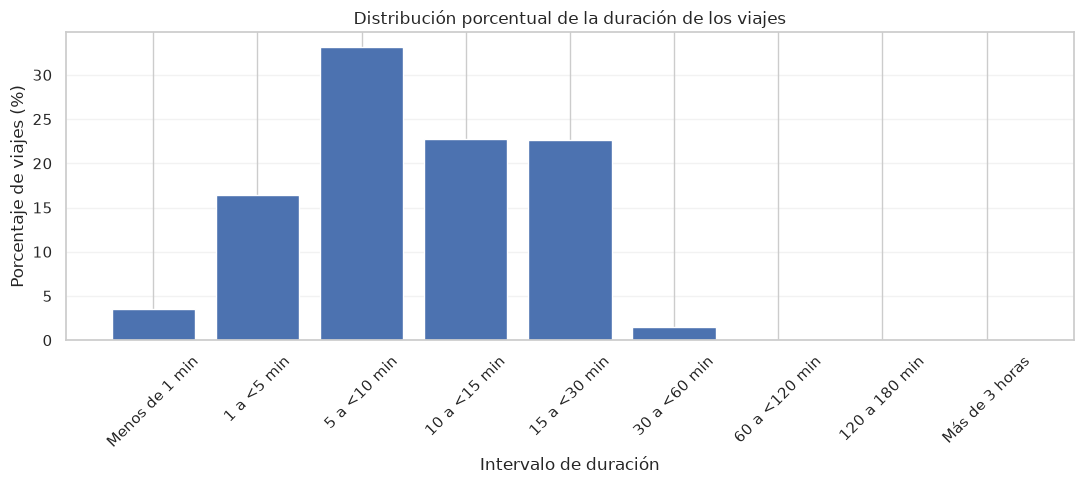

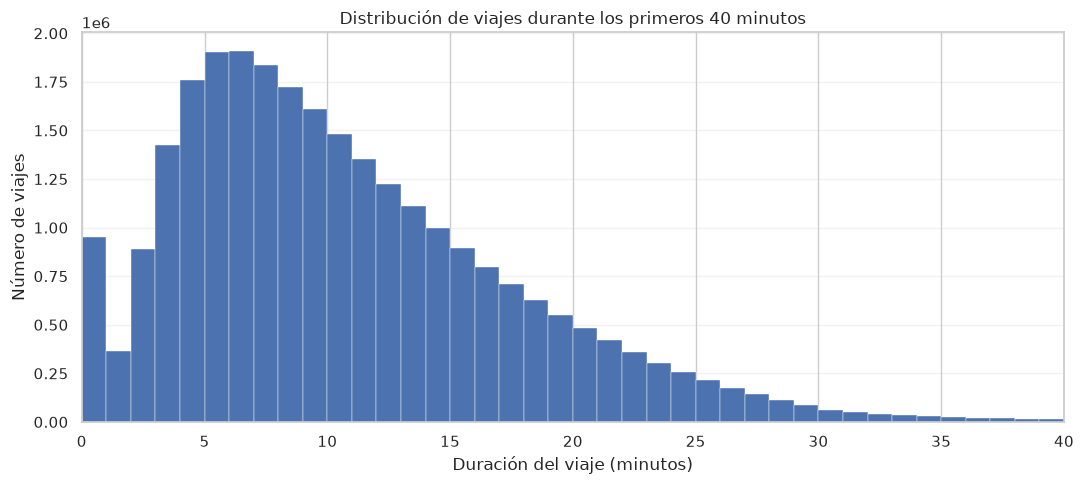

In [120]:
# Reutilizar los histogramas calculados en 7.3.
duration_histogram = (
    duration_stats["Misma estación"]["histogram"]
    + duration_stats["Estaciones diferentes"]["histogram"]
)

total_regular_trips = int(duration_histogram.sum())

# Verificar que coincidan con los conteos de 7.3.
assert total_regular_trips == sum(
    stats["count"] for stats in duration_stats.values()
), "El histograma no coincide con los conteos de 7.3."


# Calcular percentiles para viajes de hasta tres horas.
cumulative_duration = np.cumsum(duration_histogram)
percentiles = [25, 50, 75, 90, 95, 99]

duration_percentiles = pd.DataFrame({
    "Percentil": percentiles,
    "Duración (min)": [
        round(
            np.searchsorted(
                cumulative_duration,
                np.ceil(total_regular_trips * p / 100)
            ) / 60,
            2
        )
        for p in percentiles
    ]
})

print("Percentiles de duración (viajes de hasta 3 horas):")
display(duration_percentiles)


# Agrupar las duraciones en intervalos exploratorios.
# Los límites están expresados en segundos.
duration_edges = [
    0, 60, 300, 600, 900,
    1800, 3600, 7200, 10801
]

duration_labels = [
    "Menos de 1 min",
    "1 a <5 min",
    "5 a <10 min",
    "10 a <15 min",
    "15 a <30 min",
    "30 a <60 min",
    "60 a <120 min",
    "120 a 180 min"
]

duration_intervals = np.array([
    duration_histogram[start:end].sum()
    for start, end in zip(
        duration_edges[:-1],
        duration_edges[1:]
    )
], dtype="int64")

# Incorporar los viajes superiores a tres horas de 7.7.
duration_distribution = pd.DataFrame({
    "Intervalo": duration_labels + ["Más de 3 horas"],
    "Viajes": duration_intervals.tolist() + [len(long_trips)]
})

duration_distribution["Porcentaje"] = (
    duration_distribution["Viajes"]
    / duration_distribution["Viajes"].sum()
    * 100
).round(3)

# Verificar que todos los viajes estén incluidos.
assert int(duration_distribution["Viajes"].sum()) == (
    total_regular_trips + len(long_trips)
), "Los conteos de duración no coinciden."

print("Distribución general de las duraciones:")
display(duration_distribution)


# Gráfica 1: porcentaje de viajes por intervalo.
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    duration_distribution["Intervalo"],
    duration_distribution["Porcentaje"]
)

ax.set(
    title="Distribución porcentual de la duración de los viajes",
    xlabel="Intervalo de duración",
    ylabel="Porcentaje de viajes (%)"
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# Gráfica 2: distribución de los primeros 40 minutos.
# El histograma de 7.3 contiene frecuencias por segundo.
SECONDS_PER_MINUTE = 60
PLOT_MAX_MINUTES = 40

minute_edges = np.arange(
    0,
    (PLOT_MAX_MINUTES + 1) * SECONDS_PER_MINUTE,
    SECONDS_PER_MINUTE
)

minute_counts = np.array([
    duration_histogram[start:end].sum()
    for start, end in zip(
        minute_edges[:-1],
        minute_edges[1:]
    )
], dtype="int64")

# Comprobar los conteos del intervalo mostrado.
assert int(minute_counts.sum()) == int(
    duration_histogram[:PLOT_MAX_MINUTES * SECONDS_PER_MINUTE].sum()
), "Los conteos de los primeros 40 minutos no coinciden."

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    np.arange(PLOT_MAX_MINUTES),
    minute_counts,
    width=1,
    align="edge",
    edgecolor="white",
    linewidth=0.3
)

ax.set(
    title="Distribución de viajes durante los primeros 40 minutos",
    xlabel="Duración del viaje (minutos)",
    ylabel="Número de viajes"
)

ax.set_xlim(0, PLOT_MAX_MINUTES)
ax.set_xticks(np.arange(0, PLOT_MAX_MINUTES + 1, 5))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

**Clasificación de la duración de los viajes**

Con base en la distribución y los percentiles obtenidos, definimos los siguientes rangos para la variable `categoria_duracion` de la estrategia B.

| Categoría | Duración |
|---|---|
| Muy corto | Menos de 1 minuto |
| Corto | De 1 a menos de 5 minutos |
| Habitual | De 5 a menos de 15 minutos |
| Largo | De 15 a menos de 30 minutos |
| Muy largo | De 30 minutos a 3 horas |
| Prolongado | Más de 3 horas y hasta 24 horas |
| Extremo | Más de 24 horas |

Estos rangos nos permitirán identificar los viajes según su duración sin modificar los valores originales.

**Resultado de 7.8**

La mediana de duración fue de 9.45 minutos y el 75 % de los viajes duró como máximo 14.75 minutos. El intervalo más frecuente fue de 5 a 10 minutos, con el 33.16 % de los registros.

Con estos resultados definimos siete categorías de duración: muy corto, corto, habitual, largo, muy largo, prolongado y extremo. Decidimos separar los viajes de más de 24 horas para poder identificarlos y analizarlos por separado.

En la estrategia B mantendremos las duraciones originales y agregaremos una columna llamada `categoria_duracion` para clasificar los viajes sin perder información.

### 7.9. Implementación de las estrategias de limpieza

Una vez revisados los problemas de calidad y definidos los tratamientos, aplicaremos las estrategias A y B a los datos de MiBici.

Primero estableceremos las validaciones comunes para evitar diferencias en los criterios utilizados. Después aplicaremos cada estrategia por separado y guardaremos sus resultados para compararlos.

El procesamiento se realizará por bloques para evitar cargar todos los registros en memoria y sin modificar los archivos originales.

#### 7.9.1. Preparación de las transformaciones

Antes de aplicar las estrategias de limpieza, definimos las funciones que vamos a utilizar para clasificar los viajes según su duración y las estaciones de inicio y fin.

Agregaremos las columnas `categoria_duracion` y `tipo_recorrido`, conservando los datos originales para poder utilizarlos en los análisis posteriores.

Primero probaremos las funciones con algunos ejemplos para verificar que los rangos y las categorías se asignen correctamente.

In [121]:
def classify_duration(duration_minutes):
    """Clasificar la duración según los rangos definidos en 7.8."""
    categories = [
        "Muy corto", "Corto", "Habitual", "Largo",
        "Muy largo", "Prolongado", "Extremo"
    ]
    boundaries = [-np.inf, 1, 5, 15, 30, 180, 1440, np.inf]
    adjusted_duration = duration_minutes.astype("float64").copy()
    adjusted_duration = adjusted_duration.mask(
        adjusted_duration == 180, np.nextafter(180.0, -np.inf)
    )
    adjusted_duration = adjusted_duration.mask(
        adjusted_duration == 1440, np.nextafter(1440.0, -np.inf)
    )
    adjusted_duration = adjusted_duration.mask(adjusted_duration < 0)
    return pd.cut(
        adjusted_duration, bins=boundaries, labels=categories, right=False
    )


def add_trip_features(data):
    """Agregar duración, categoría y tipo de recorrido sin modificar la entrada."""
    result = data.copy()
    start_time = pd.to_datetime(
        result["Inicio_del_viaje"], format=DATETIME_FORMAT, errors="coerce"
    )
    end_time = pd.to_datetime(
        result["Fin_del_viaje"], format=DATETIME_FORMAT, errors="coerce"
    )
    duration = (end_time - start_time).dt.total_seconds() / 60
    duration = duration.mask(duration < 0)
    result["duracion_minutos"] = duration
    result["categoria_duracion"] = classify_duration(duration)

    origin_id = pd.to_numeric(result["Origen_Id"], errors="coerce").astype("Int64")
    destination_id = pd.to_numeric(result["Destino_Id"], errors="coerce").astype("Int64")
    valid_stations = origin_id.notna() & destination_id.notna()
    same_station = origin_id.eq(destination_id).fillna(False) & valid_stations
    different_stations = origin_id.ne(destination_id).fillna(False) & valid_stations

    result["tipo_recorrido"] = pd.Series(pd.NA, index=result.index, dtype="string")
    result.loc[same_station, "tipo_recorrido"] = "Misma estación"
    result.loc[different_stations, "tipo_recorrido"] = "Estaciones diferentes"
    return result


In [122]:
# Probar los límites de las siete categorías.
test_durations = pd.Series([
    0, 0.5, 1, 4.99, 5, 14.99, 15,
    29.99, 30, 179.99, 180, 180.01,
    1439.99, 1440, 1440.01
])

test_table = pd.DataFrame({
    "duracion_minutos": test_durations,
    "categoria": classify_duration(test_durations)
})

# Comprobar los límites que corregimos.
assert test_table.loc[10, "categoria"] == "Muy largo"
assert test_table.loc[13, "categoria"] == "Prolongado"
assert test_table.loc[14, "categoria"] == "Extremo"

print("Validación de límites correcta.")
display(test_table)

Validación de límites correcta.


,duracion_minutos,categoria
0,0.00,Muy corto
1,0.50,Muy corto
2,1.00,Corto
3,4.99,Corto
4,5.00,Habitual
5,14.99,Habitual
6,15.00,Largo
7,29.99,Largo
8,30.00,Muy largo
9,179.99,Muy largo


**Resultado de 7.9.1**

Definimos las funciones para clasificar la duración de los viajes y distinguir los recorridos entre estaciones. Las pruebas permitieron comprobar los límites de las categorías, incluyendo los viajes de exactamente 3 y 24 horas.

Estas funciones se utilizarán en la estrategia B para agregar información sin reemplazar los valores originales.

#### 7.9.2. Pruebas de las transformaciones

Antes de aplicar la limpieza a todos los archivos, probaremos las funciones con algunos viajes de ejemplo.

Revisaremos que se calculen correctamente las duraciones, que se identifiquen los recorridos entre estaciones y que los registros con información incompleta no reciban categorías incorrectas.

In [123]:
# --------------------------------------------------
# Prueba de las transformaciones
# --------------------------------------------------

# Crear viajes de ejemplo.
test_trips = pd.DataFrame({
    "Inicio_del_viaje": [
        "2026-09-01 08:00:00",
        "2026-09-01 09:00:00",
        "2026-09-01 10:00:00",
        "2026-09-01 11:00:00",
        "2026-09-01 12:00:00"
    ],
    "Fin_del_viaje": [
        "2026-09-01 08:00:30",
        "2026-09-01 09:10:00",
        "2026-09-01 13:00:00",
        None,
        "2026-09-01 11:50:00"
    ],
    "Origen_Id": [
        10, 10, 20, 30, 40
    ],
    "Destino_Id": [
        10, 15, 25, pd.NA, 45
    ]
})

# Aplicar las transformaciones.
test_result = add_trip_features(
    test_trips
)

# --------------------------------------------------
# Validaciones
# --------------------------------------------------

# Caso 1: viaje menor de un minuto y misma estación.
assert test_result.loc[0, "duracion_minutos"] == 0.5
assert test_result.loc[0, "categoria_duracion"] == "Muy corto"
assert test_result.loc[0, "tipo_recorrido"] == "Misma estación"

# Caso 2: viaje habitual entre estaciones diferentes.
assert test_result.loc[1, "duracion_minutos"] == 10
assert test_result.loc[1, "categoria_duracion"] == "Habitual"
assert test_result.loc[1, "tipo_recorrido"] == "Estaciones diferentes"

# Caso 3: viaje de exactamente tres horas.
assert test_result.loc[2, "duracion_minutos"] == 180
assert test_result.loc[2, "categoria_duracion"] == "Muy largo"
assert test_result.loc[2, "tipo_recorrido"] == "Estaciones diferentes"

# Caso 4: fecha final y estación de destino faltantes.
assert pd.isna(test_result.loc[3, "duracion_minutos"])
assert pd.isna(test_result.loc[3, "categoria_duracion"])
assert pd.isna(test_result.loc[3, "tipo_recorrido"])

# Caso 5: duración negativa, pero estaciones conocidas.
assert pd.isna(test_result.loc[4, "duracion_minutos"])
assert pd.isna(test_result.loc[4, "categoria_duracion"])
assert test_result.loc[4, "tipo_recorrido"] == "Estaciones diferentes"

# Verificar que las columnas originales no cambiaron.
pd.testing.assert_frame_equal(
    test_trips,
    test_result[test_trips.columns]
)

# --------------------------------------------------
# Resultados
# --------------------------------------------------

print("Validación de transformaciones correcta.")
print(f"Registros evaluados: {len(test_result)}")

result_columns = [
    "Inicio_del_viaje",
    "Fin_del_viaje",
    "Origen_Id",
    "Destino_Id",
    "duracion_minutos",
    "categoria_duracion",
    "tipo_recorrido"
]

display(test_result[result_columns])

Validación de transformaciones correcta.
Registros evaluados: 5


,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,duracion_minutos,categoria_duracion,tipo_recorrido
0,2026-09-01 08:00:00,2026-09-01 08:00:30,10,10,0.5,Muy corto,Misma estación
1,2026-09-01 09:00:00,2026-09-01 09:10:00,10,15,10.0,Habitual,Estaciones diferentes
2,2026-09-01 10:00:00,2026-09-01 13:00:00,20,25,180.0,Muy largo,Estaciones diferentes
3,2026-09-01 11:00:00,NaN,30,<NA>,NaN,NaN,<NA>
4,2026-09-01 12:00:00,2026-09-01 11:50:00,40,45,NaN,NaN,Estaciones diferentes


#### 7.9.3. Estrategia B: implementación y validación

##### 7.9.3.1. Implementación de la estrategia B

En esta parte definimos la función que utilizaremos para limpiar los datos por bloques, siguiendo los criterios de la estrategia B.

Eliminaremos los viajes duplicados y aquellos que no tengan información válida de inicio o estación de origen. En cambio, conservaremos los registros con datos demográficos incompletos, siempre que sean útiles para calcular la demanda horaria.

También agregaremos las variables de duración y tipo de recorrido. Al final, la función nos dará los datos limpios y un resumen de los registros conservados y eliminados para revisar los resultados de cada bloque.

In [124]:
# Estaciones excluidas según la decisión tomada en el diagnóstico.
EXCLUDED_STATIONS = {407, 124, 405}


def clean_strategy_b(data, seen_ids=None):
    """Aplicar la estrategia B y registrar los resultados de limpieza."""

    # Trabajar sobre una copia para no modificar los datos recibidos.
    result = data.copy()

    # Conservar los identificadores vistos entre bloques.
    if seen_ids is None:
        seen_ids = set()

    # Verificar que estén presentes las columnas esperadas.
    missing_columns = set(TRIP_SCHEMA) - set(result.columns)

    if missing_columns:
        raise ValueError(
            f"Faltan columnas: {sorted(missing_columns)}"
        )

    # Convertir las columnas necesarias para validar registros.
    trip_id = pd.to_numeric(
        result["Viaje_Id"],
        errors="coerce"
    )

    origin_id = pd.to_numeric(
        result["Origen_Id"],
        errors="coerce"
    )

    destination_id = pd.to_numeric(
        result["Destino_Id"],
        errors="coerce"
    )

    start_time = pd.to_datetime(
        result["Inicio_del_viaje"],
        format=DATETIME_FORMAT,
        errors="coerce"
    )

    # Registrar un único motivo de exclusión por registro.
    exclusion_reason = pd.Series(
        pd.NA,
        index=result.index,
        dtype="string"
    )

    # 1. Identificadores de viaje inválidos.
    invalid_id = (
        trip_id.isna()
        | (trip_id <= 0)
        | (trip_id % 1 != 0)
    ).fillna(True)

    exclusion_reason.loc[invalid_id] = "Viaje_Id inválido"

    # 2. Duplicados dentro del bloque o en bloques anteriores.
    duplicate_ids_in_chunk = (
        trip_id.duplicated(keep="first")
        | trip_id.isin(seen_ids)
    ).fillna(False)

    exclusion_reason.loc[
        exclusion_reason.isna() & duplicate_ids_in_chunk
    ] = "Viaje_Id duplicado"

    # 3. Fechas de inicio inválidas.
    exclusion_reason.loc[
        exclusion_reason.isna() & start_time.isna()
    ] = "Inicio inválido"

    # 4. Fechas fuera del periodo de estudio.
    outside_study_period = (
        (start_time < STUDY_START)
        | (start_time >= STUDY_END)
    ).fillna(False)

    exclusion_reason.loc[
        exclusion_reason.isna() & outside_study_period
    ] = "Fuera del periodo"

    # 5. Estaciones de origen inválidas.
    invalid_origin = (
        origin_id.isna()
        | (origin_id <= 0)
        | (origin_id % 1 != 0)
    ).fillna(True)

    exclusion_reason.loc[
        exclusion_reason.isna() & invalid_origin
    ] = "Origen inválido"

    # 6. Viajes relacionados con estaciones excluidas.
    excluded_station = (
        origin_id.isin(EXCLUDED_STATIONS)
        | destination_id.isin(EXCLUDED_STATIONS)
    ).fillna(False)

    exclusion_reason.loc[
        exclusion_reason.isna() & excluded_station
    ] = "Estación excluida"

    # Registrar los IDs válidos encontrados en este bloque.
    # Se incluyen también los viajes excluidos por otras reglas.
    new_ids = trip_id.loc[
        ~invalid_id & ~duplicate_ids_in_chunk
    ].astype("int64")

    seen_ids.update(new_ids.tolist())

    # Conservar los registros sin motivo de exclusión.
    cleaned_data = result.loc[
        exclusion_reason.isna()
    ].copy()

    # 7. Normalizar el género.
    gender = (
        cleaned_data["Genero"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    valid_gender = gender.isin(VALID_GENDERS)

    cleaned_data["Genero"] = gender.where(
        valid_gender,
        "No especificado"
    )

    # 8. Validar el año de nacimiento.
    birth_year = pd.to_numeric(
        cleaned_data["Año_de_nacimiento"],
        errors="coerce"
    )

    cleaned_start_time = pd.to_datetime(
        cleaned_data["Inicio_del_viaje"],
        format=DATETIME_FORMAT,
        errors="coerce"
    )

    age = cleaned_start_time.dt.year - birth_year

    invalid_birth_year = (
        birth_year.notna()
        & (
            (birth_year % 1 != 0)
            | (age < MIN_AGE)
            | (age > MAX_AGE)
        )
    ).fillna(False)

    cleaned_data["Año_de_nacimiento"] = (
        birth_year
        .mask(invalid_birth_year)
        .astype("Int64")
    )

    # 9. Agregar duración, categoría y tipo de recorrido.
    cleaned_data = add_trip_features(
        cleaned_data
    )

    # 10. Construir el resumen de limpieza.
    summary = {
        "original_rows": len(result),
        "kept_rows": len(cleaned_data),
        "excluded_rows": int(exclusion_reason.notna().sum()),
        "Viaje_Id inválido": int(
            (exclusion_reason == "Viaje_Id inválido").sum()
        ),
        "Viaje_Id duplicado": int(
            (exclusion_reason == "Viaje_Id duplicado").sum()
        ),
        "Inicio inválido": int(
            (exclusion_reason == "Inicio inválido").sum()
        ),
        "Fuera del periodo": int(
            (exclusion_reason == "Fuera del periodo").sum()
        ),
        "Origen inválido": int(
            (exclusion_reason == "Origen inválido").sum()
        ),
        "Estación excluida": int(
            (exclusion_reason == "Estación excluida").sum()
        ),
        "corrected_genders": int(
            (~valid_gender).sum()
        ),
        "corrected_birth_years": int(
            invalid_birth_year.sum()
        )
    }

    # Comprobar la conciliación de registros.
    assert (
        summary["original_rows"]
        == summary["kept_rows"] + summary["excluded_rows"]
    )

    return cleaned_data, summary, seen_ids


print("Función limpiar_estrategia_b definida correctamente.")


Función limpiar_estrategia_b definida correctamente.


##### 7.9.3.2. Verificación de la limpieza entre bloques

Antes de procesar los archivos mensuales, comprobaremos que la función identifique los viajes duplicados aunque aparezcan en bloques diferentes.

Esta prueba es importante porque los CSV se leerán por partes. Si cada bloque se revisara de manera independiente, podríamos conservar más de una aparición del mismo viaje y alterar el cálculo de la demanda.

También verificaremos que los conteos de ambos bloques sean consistentes y que se conserven los viajes con información demográfica incompleta.

In [125]:

# Crear datos de prueba para verificar la limpieza entre bloques.
block_test_data = pd.DataFrame({
    "Viaje_Id": [1, 2, 2, 3, 4, 5, 6, 7],
    "Usuario_Id": [101, 102, 102, 103, 104, 105, 106, 107],
    "Genero": ["M", None, None, "F", "M", "F", "M", "F"],
    "Año_de_nacimiento": [
        1995, None, None, 1990, 2000, 1985, 1900, 2000
    ],
    "Inicio_del_viaje": [
        "2026-09-01 08:00:00",
        "2026-09-01 09:00:00",
        "2026-09-01 09:00:00",
        "2026-09-01 10:00:00",
        "2026-09-01 11:00:00",
        "2026-09-01 12:00:00",
        "2026-09-01 13:00:00",
        "2026-09-01 14:00:00"
    ],
    "Fin_del_viaje": [
        "2026-09-01 08:00:30",
        "2026-09-01 09:10:00",
        "2026-09-01 09:10:00",
        "2026-09-01 10:20:00",
        "2026-09-01 11:30:00",
        "2026-09-01 12:20:00",
        "2026-09-01 13:20:00",
        "2026-09-01 14:20:00"
    ],
    "Origen_Id": [10, 10, 10, 407, 20, None, 30, 40],
    "Destino_Id": [10, 15, 15, 25, 30, 40, 35, 45]
})

# Dividir los registros en dos bloques.
# El Viaje_Id 2 aparece en ambos bloques.
block_1 = block_test_data.iloc[[0, 1, 3]].copy()
block_2 = block_test_data.iloc[[2, 4, 5, 6, 7]].copy()

# Crear un conjunto compartido de identificadores.
test_seen_ids = set()

# Aplicar la estrategia B al primer bloque.
cleaned_1, summary_1, test_seen_ids = clean_strategy_b(
    block_1,
    seen_ids=test_seen_ids
)

# Aplicar la estrategia B al segundo bloque.
cleaned_2, summary_2, test_seen_ids = clean_strategy_b(
    block_2,
    seen_ids=test_seen_ids
)

# Unir los registros conservados.
combined_results = pd.concat(
    [cleaned_1, cleaned_2],
    ignore_index=True
)

# Construir el resumen de limpieza.
block_summary = pd.DataFrame(
    [summary_1, summary_2],
    index=["Bloque 1", "Bloque 2"]
)

# Calcular los totales.
block_totals = block_summary.sum(numeric_only=True)

# Verificar que no existan identificadores duplicados.
assert combined_results["Viaje_Id"].is_unique

# Verificar que el segundo bloque detecte el duplicado.
assert summary_2["Viaje_Id duplicado"] == 1

# Verificar los identificadores conservados.
assert set(combined_results["Viaje_Id"]) == {1, 2, 4, 6, 7}

# Verificar los conteos generales.
assert block_totals["original_rows"] == 8
assert block_totals["kept_rows"] == 5
assert block_totals["excluded_rows"] == 3

# Verificar la conciliación de registros.
assert (
    block_totals["original_rows"]
    == block_totals["kept_rows"]
    + block_totals["excluded_rows"]
)

print("Validación entre bloques correcta.")

print("\nResumen por bloque:")
display(
    block_summary[
        [
            "original_rows",
            "kept_rows",
            "excluded_rows",
            "Viaje_Id duplicado",
            "Estación excluida",
            "Origen inválido"
        ]
    ]
)

print("\nTotales:")
display(
    block_totals[
        ["original_rows", "kept_rows", "excluded_rows"]
    ].to_frame(name="Cantidad")
)


Validación entre bloques correcta.

Resumen por bloque:


,original_rows,kept_rows,excluded_rows,Viaje_Id duplicado,Estación excluida,Origen inválido
Bloque 1,3,2,1,0,1,0
Bloque 2,5,3,2,1,0,1



Totales:


,Cantidad
original_rows,8
kept_rows,5
excluded_rows,3


#### 7.9.4. Estrategia A: eliminación de registros

##### 7.9.4.1. Implementación de la estrategia A

En esta estrategia eliminaremos los viajes que no cumplan con los criterios de calidad definidos anteriormente. A diferencia de la estrategia B, también descartaremos los registros con datos demográficos faltantes, edades fuera de rango o duraciones menores a un minuto o mayores a tres horas.

Utilizaremos una función para aplicar estas reglas por bloques y llevar un conteo de los registros conservados y eliminados.

In [126]:

def clean_strategy_a(data, seen_ids=None):
    """Aplicar la limpieza estricta y resumir las exclusiones."""

    result = data.copy()

    if seen_ids is None:
        seen_ids = set()

    # Comprobar las columnas originales del Data Contract.
    missing_columns = set(TRIP_SCHEMA) - set(result.columns)

    if missing_columns:
        raise ValueError(
            f"Faltan columnas: {sorted(missing_columns)}"
        )

    # Preparar las variables para aplicar las reglas.
    trip_id = pd.to_numeric(
        result["Viaje_Id"], errors="coerce"
    )

    user_id = pd.to_numeric(
        result["Usuario_Id"], errors="coerce"
    )

    origin_id = pd.to_numeric(
        result["Origen_Id"], errors="coerce"
    )

    destination_id = pd.to_numeric(
        result["Destino_Id"], errors="coerce"
    )

    start_time = pd.to_datetime(
        result["Inicio_del_viaje"],
        format=DATETIME_FORMAT,
        errors="coerce"
    )

    end_time = pd.to_datetime(
        result["Fin_del_viaje"],
        format=DATETIME_FORMAT,
        errors="coerce"
    )

    gender = (
        result["Genero"]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    birth_year = pd.to_numeric(
        result["Año_de_nacimiento"],
        errors="coerce"
    )

    duration = end_time - start_time
    age = start_time.dt.year - birth_year

    # Registrar un motivo principal por registro.
    exclusion_reason = pd.Series(
        pd.NA,
        index=result.index,
        dtype="string"
    )

    # Definir las reglas en el orden de aplicación.
    rules = [
        (
            "Viaje_Id inválido",
            trip_id.isna()
            | (trip_id <= 0)
            | (trip_id % 1 != 0)
        ),
        (
            "Viaje_Id duplicado",
            trip_id.duplicated(keep="first")
            | trip_id.isin(seen_ids)
        ),
        (
            "Inicio inválido",
            start_time.isna()
        ),
        (
            "Fuera del periodo",
            (start_time < STUDY_START)
            | (start_time >= STUDY_END)
        ),
        (
            "Origen inválido",
            origin_id.isna()
            | (origin_id <= 0)
            | (origin_id % 1 != 0)
        ),
        (
            "Estación excluida",
            origin_id.isin(EXCLUDED_STATIONS)
            | destination_id.isin(EXCLUDED_STATIONS)
        ),
        (
            "Usuario_Id inválido",
            user_id.isna()
            | (user_id <= 0)
            | (user_id % 1 != 0)
        ),
        (
            "Género inválido o faltante",
            ~gender.isin(VALID_GENDERS)
        ),
        (
            "Nacimiento inválido o faltante",
            birth_year.isna()
            | (birth_year % 1 != 0)
            | (age < MIN_AGE)
            | (age > MAX_AGE)
        ),
        (
            "Fin inválido",
            end_time.isna()
        ),
        (
            "Duración fuera de rango",
            (duration < MIN_TRIP_DURATION)
            | (duration > MAX_TRIP_DURATION)
        ),
        (
            "Destino inválido",
            destination_id.isna()
            | (destination_id <= 0)
            | (destination_id % 1 != 0)
        )
    ]

    # Asignar el primer motivo aplicable.
    for rule_name, condition in rules:
        condition = condition.fillna(False)

        exclusion_reason.loc[
            exclusion_reason.isna() & condition
        ] = rule_name

    # Registrar IDs válidos para detectar repeticiones
    # en los bloques siguientes.
    invalid_id = (
        trip_id.isna()
        | (trip_id <= 0)
        | (trip_id % 1 != 0)
    ).fillna(True)

    duplicate_id = (
        trip_id.duplicated(keep="first")
        | trip_id.isin(seen_ids)
    ).fillna(False)

    new_ids = trip_id.loc[
        ~invalid_id & ~duplicate_id
    ].astype("int64")

    seen_ids.update(new_ids.tolist())

    # Conservar únicamente los viajes sin exclusiones.
    cleaned_data = result.loc[
        exclusion_reason.isna()
    ].copy()

    # Normalizar los campos conservados.
    cleaned_data["Genero"] = gender.loc[
        cleaned_data.index
    ]

    cleaned_data["Año_de_nacimiento"] = (
        birth_year.loc[cleaned_data.index]
        .astype("Int64")
    )

    # Calcular las variables de recorrido.
    cleaned_data = add_trip_features(
        cleaned_data
    )

    # Crear el resumen de resultados.
    summary = {
        "original_rows": len(result),
        "kept_rows": len(cleaned_data),
        "excluded_rows": int(exclusion_reason.notna().sum())
    }

    for rule_name, _ in rules:
        summary[rule_name] = int(
            (exclusion_reason == rule_name).sum()
        )

    # Validar que todos los registros estén contabilizados.
    assert (
        summary["original_rows"]
        == summary["kept_rows"] + summary["excluded_rows"]
    )

    assert (
        summary["excluded_rows"]
        == sum(
            summary[rule_name]
            for rule_name, _ in rules
        )
    )

    return cleaned_data, summary, seen_ids


print("Función limpiar_estrategia_a definida correctamente.")


Función limpiar_estrategia_a definida correctamente.


##### 7.9.4.2. Pruebas de la estrategia A

Antes de aplicar la estrategia A, probaremos la función con algunos registros de ejemplo. Revisaremos que conserve los viajes válidos y elimine los que tengan datos incompletos, duraciones fuera de rango o estaciones excluidas.

También comprobaremos que detecte los identificadores repetidos entre bloques y que los conteos de limpieza sean consistentes.

In [127]:

# Crear datos de prueba para la estrategia A.
test_data_a = pd.DataFrame({
    "Viaje_Id": [1, 2, 3, 4, 5, 6, 7, 1],
    "Usuario_Id": [101, 102, 103, 104, 105, 106, 107, 101],
    "Genero": ["M", "F", None, "M", "F", "M", "F", "M"],
    "Año_de_nacimiento": [
        1995, 1990, 1985, 2000, 1995, 1900, 1992, 1995
    ],
    "Inicio_del_viaje": [
        "2026-09-01 08:00:00",
        "2026-09-01 09:00:00",
        "2026-09-01 10:00:00",
        "2026-09-01 11:00:00",
        "2026-09-01 12:00:00",
        "2026-09-01 13:00:00",
        "2026-09-01 14:00:00",
        "2026-09-01 08:00:00"
    ],
    "Fin_del_viaje": [
        "2026-09-01 08:10:00",
        "2026-09-01 09:00:30",
        "2026-09-01 10:10:00",
        "2026-09-01 11:10:00",
        "2026-09-01 16:00:00",
        "2026-09-01 13:10:00",
        "2026-09-01 14:10:00",
        "2026-09-01 08:10:00"
    ],
    "Origen_Id": [10, 10, 10, 407, 20, 30, 40, 10],
    "Destino_Id": [15, 15, 15, 25, 30, 35, 45, 15]
})

# Dividir los datos para comprobar duplicados entre bloques.
test_block_1 = test_data_a.iloc[:4].copy()
test_block_2 = test_data_a.iloc[4:].copy()

# Compartir los identificadores entre bloques.
test_seen_ids_a = set()

cleaned_a_1, summary_a_1, test_seen_ids_a = clean_strategy_a(
    test_block_1,
    seen_ids=test_seen_ids_a
)

cleaned_a_2, summary_a_2, test_seen_ids_a = clean_strategy_a(
    test_block_2,
    seen_ids=test_seen_ids_a
)

# Integrar los resultados.
cleaned_test_a = pd.concat(
    [cleaned_a_1, cleaned_a_2],
    ignore_index=True
)

summary_test_a = pd.DataFrame(
    [summary_a_1, summary_a_2],
    index=["Bloque 1", "Bloque 2"]
)

total_summary_a = summary_test_a.sum(numeric_only=True)

# Comprobar los registros conservados y excluidos.
assert total_summary_a["original_rows"] == 8
assert total_summary_a["kept_rows"] == 2
assert total_summary_a["excluded_rows"] == 6

# Solo deben conservarse los viajes 1 y 7.
assert set(cleaned_test_a["Viaje_Id"]) == {1, 7}

# Comprobar las principales reglas.
assert total_summary_a["Viaje_Id duplicado"] == 1
assert total_summary_a["Género inválido o faltante"] == 1
assert total_summary_a["Estación excluida"] == 1
assert total_summary_a["Nacimiento inválido o faltante"] == 1
assert total_summary_a["Duración fuera de rango"] == 2

# Comprobar que no queden IDs repetidos.
assert cleaned_test_a["Viaje_Id"].is_unique

# Verificar la conciliación de registros.
assert (
    total_summary_a["original_rows"]
    == total_summary_a["kept_rows"]
    + total_summary_a["excluded_rows"]
)

print("Validación de la estrategia A correcta.")

print("\nResumen por bloque:")
display(summary_test_a)

print("\nTotales:")
display(
    total_summary_a.to_frame(name="Cantidad")
)

print("\nViajes conservados:")
display(
    cleaned_test_a[
        [
            "Viaje_Id",
            "Inicio_del_viaje",
            "Origen_Id",
            "Destino_Id",
            "duracion_minutos",
            "categoria_duracion"
        ]
    ]
)


Validación de la estrategia A correcta.

Resumen por bloque:


,original_rows,kept_rows,excluded_rows,Viaje_Id inválido,Viaje_Id duplicado,Inicio inválido,Fuera del periodo,Origen inválido,Estación excluida,Usuario_Id inválido,Género inválido o faltante,Nacimiento inválido o faltante,Fin inválido,Duración fuera de rango,Destino inválido
Bloque 1,4,1,3,0,0,0,0,0,1,0,1,0,0,1,0
Bloque 2,4,1,3,0,1,0,0,0,0,0,0,1,0,1,0



Totales:


,Cantidad
original_rows,8
kept_rows,2
excluded_rows,6
Viaje_Id inválido,0
Viaje_Id duplicado,1
Inicio inválido,0
Fuera del periodo,0
Origen inválido,0
Estación excluida,1
Usuario_Id inválido,0



Viajes conservados:


,Viaje_Id,Inicio_del_viaje,Origen_Id,Destino_Id,duracion_minutos,categoria_duracion
0,1,2026-09-01 08:00:00,10,15,10.0,Habitual
1,7,2026-09-01 14:00:00,40,45,10.0,Habitual


#### 7.9.5. Ejecución de las estrategias de limpieza por bloques

Una vez definidas y probadas las estrategias A y B, vamos a aplicarlas a los archivos CSV.

Para no cargar todos los registros en memoria, leeremos los archivos en bloques de 50,000 viajes. Cada bloque se normalizará y después se procesará con ambas estrategias.

Los resultados se guardarán por separado en CSV y Parquet, sin modificar los archivos originales. También llevaremos un registro de los viajes que conserva y descarta cada estrategia para poder compararlas después.

Para detectar duplicados entre bloques del mismo archivo, se conservarán los identificadores mientras se procesa cada mes.

In [128]:
# Esquema común para los archivos Parquet.
CLEAN_PARQUET_SCHEMA = pa.schema([
    pa.field("Viaje_Id", pa.int64()),
    pa.field("Usuario_Id", pa.int64()),
    pa.field("Genero", pa.string()),
    pa.field("Año_de_nacimiento", pa.int64()),
    pa.field("Inicio_del_viaje", pa.timestamp("ns")),
    pa.field("Fin_del_viaje", pa.timestamp("ns")),
    pa.field("Origen_Id", pa.int64()),
    pa.field("Destino_Id", pa.int64()),
    pa.field("duracion_minutos", pa.float64()),
    pa.field("categoria_duracion", pa.string()),
    pa.field("tipo_recorrido", pa.string())
])


def process_cleaning_strategies(
    file_paths,
    encodings,
    chunk_size,
    output_dir
):
    """Procesar los archivos mensuales con las estrategias A y B."""

    # Verificar los parámetros antes de comenzar.
    if chunk_size <= 0:
        raise ValueError("chunk_size debe ser mayor que cero.")

    file_paths = sorted(
        [Path(file_path) for file_path in file_paths]
    )

    if not file_paths:
        raise ValueError("No se recibieron archivos para procesar.")

    missing_encodings = [
        file_path.name
        for file_path in file_paths
        if file_path.name not in encodings
    ]

    if missing_encodings:
        raise ValueError(
            f"Faltan codificaciones: {missing_encodings}"
        )

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # Definir las rutas finales.
    output_paths = {
        strategy: {
            "csv": output_dir / f"mibici_clean_{strategy}.csv",
            "parquet": output_dir / f"mibici_clean_{strategy}.parquet"
        }
        for strategy in ("A", "B")
    }

    # Evitar sobrescribir resultados anteriores.
    existing_outputs = [
        str(path)
        for strategy_paths in output_paths.values()
        for path in strategy_paths.values()
        if path.exists()
    ]

    if existing_outputs:
        raise FileExistsError(
            f"Ya existen archivos de salida: {existing_outputs}"
        )

    # Preparar una carpeta temporal.
    temporary_dir = output_dir / "_cleaning_in_progress"

    if temporary_dir.exists():
        raise FileExistsError(
            f"Ya existe la carpeta temporal: {temporary_dir}. "
            "Revisa su contenido antes de repetir el proceso."
        )

    temporary_dir.mkdir()

    temporary_paths = {
        strategy: {
            "csv": temporary_dir / f"mibici_clean_{strategy}.csv",
            "parquet": temporary_dir / f"mibici_clean_{strategy}.parquet"
        }
        for strategy in ("A", "B")
    }

    # Acumular los resultados de limpieza.
    summaries = {
        "A": Counter(),
        "B": Counter()
    }

    # Preparar los escritores Parquet.
    parquet_writers = {
        "A": None,
        "B": None
    }

    csv_initialized = {
        "A": False,
        "B": False
    }

    processed_rows = 0

    try:
        # Procesar los archivos en orden cronológico.
        for file_number, file_path in enumerate(
            file_paths, start=1
        ):

            # Reiniciar los IDs al comenzar cada archivo mensual.
            # Se mantiene el seguimiento entre bloques del mismo archivo.
            seen_ids = {
                "A": set(),
                "B": set()
            }

            reader = pd.read_csv(
                file_path,
                encoding=encodings[file_path.name],
                dtype="string",
                chunksize=chunk_size
            )

            for raw_chunk in reader:

                # Normalizar el bloque una sola vez.
                normalized_chunk = normalize_chunk(raw_chunk)

                processed_rows += len(normalized_chunk)

                # Aplicar la estrategia A.
                cleaned_a, summary_a, seen_ids["A"] = (
                    clean_strategy_a(
                        normalized_chunk,
                        seen_ids["A"]
                    )
                )

                # Aplicar la estrategia B.
                cleaned_b, summary_b, seen_ids["B"] = (
                    clean_strategy_b(
                        normalized_chunk,
                        seen_ids["B"]
                    )
                )

                cleaned_chunks = {
                    "A": cleaned_a,
                    "B": cleaned_b
                }

                chunk_summaries = {
                    "A": summary_a,
                    "B": summary_b
                }

                # Guardar los resultados de ambas estrategias.
                for strategy in ("A", "B"):

                    cleaned_data = cleaned_chunks[strategy]

                    # Acumular los conteos.
                    summaries[strategy].update(
                        chunk_summaries[strategy]
                    )

                    # Mantener el orden de las columnas.
                    cleaned_data = cleaned_data[
                        CLEAN_PARQUET_SCHEMA.names
                    ].copy()

                    # Asegurar los tipos de datos enteros.
                    for column in (
                        "Viaje_Id",
                        "Usuario_Id",
                        "Año_de_nacimiento",
                        "Origen_Id",
                        "Destino_Id"
                    ):
                        cleaned_data[column] = pd.to_numeric(
                            cleaned_data[column],
                            errors="coerce"
                        ).astype("Int64")

                    # Asegurar los tipos de fecha.
                    for column in (
                        "Inicio_del_viaje",
                        "Fin_del_viaje"
                    ):
                        cleaned_data[column] = pd.to_datetime(
                            cleaned_data[column],
                            errors="coerce"
                        )

                    # Asegurar los tipos de texto.
                    for column in (
                        "Genero",
                        "categoria_duracion",
                        "tipo_recorrido"
                    ):
                        cleaned_data[column] = (
                            cleaned_data[column].astype("string")
                        )

                    # Asegurar el tipo de duración.
                    cleaned_data["duracion_minutos"] = (
                        pd.to_numeric(
                            cleaned_data["duracion_minutos"],
                            errors="coerce"
                        ).astype("float64")
                    )

                    # Escribir los registros en CSV.
                    cleaned_data.to_csv(
                        temporary_paths[strategy]["csv"],
                        mode="a",
                        header=not csv_initialized[strategy],
                        index=False,
                        encoding="utf-8"
                    )

                    csv_initialized[strategy] = True

                    # Convertir los registros a Arrow.
                    arrow_table = pa.Table.from_pandas(
                        cleaned_data,
                        schema=CLEAN_PARQUET_SCHEMA,
                        preserve_index=False,
                        safe=True
                    )

                    # Crear el escritor Parquet cuando sea necesario.
                    if parquet_writers[strategy] is None:

                        parquet_writers[strategy] = pq.ParquetWriter(
                            temporary_paths[strategy]["parquet"],
                            CLEAN_PARQUET_SCHEMA,
                            compression="snappy"
                        )

                    parquet_writers[strategy].write_table(
                        arrow_table
                    )

            print(
                f"Archivo {file_number}/{len(file_paths)}: "
                f"{file_path.name}"
            )

        # Verificar los conteos finales.
        for strategy in ("A", "B"):

            original_rows = summaries[strategy]["original_rows"]
            kept_rows = summaries[strategy]["kept_rows"]
            excluded_rows = summaries[strategy]["excluded_rows"]

            if original_rows != processed_rows:
                raise ValueError(
                    f"Conteo de entrada incorrecto en {strategy}."
                )

            if original_rows != kept_rows + excluded_rows:
                raise ValueError(
                    f"Error de conciliación en {strategy}."
                )

    finally:
        # Cerrar los escritores Parquet.
        for writer in parquet_writers.values():
            if writer is not None:
                writer.close()

    # Publicar los resultados después de completar la limpieza.
    for strategy in ("A", "B"):
        for file_format in ("csv", "parquet"):

            temporary_paths[strategy][file_format].replace(
                output_paths[strategy][file_format]
            )

    # Eliminar la carpeta temporal.
    shutil.rmtree(temporary_dir)

    # Preparar la tabla de resultados.
    summary_table = pd.DataFrame(
        summaries
    ).fillna(0).astype("int64")

    return summary_table, output_paths


print("Función process_cleaning_strategies definida correctamente.")

Función process_cleaning_strategies definida correctamente.


#### 7.9.6. Prueba del procesamiento

Antes de procesar todos los archivos, haremos una prueba con un archivo mensual para revisar que las estrategias A y B se ejecuten correctamente y que los resultados se guarden en CSV y Parquet.

También verificaremos que la cantidad de registros conservados y descartados coincida con el total procesado.

In [129]:
# Seleccionar un archivo para la prueba.
test_files = monthly_files[:1]

# Mantener los resultados de prueba separados de los definitivos.
TEST_OUTPUT_DIR = PROJECT_DIR / "data" / "processed" / "test"

# Comprobar si la prueba ya se realizó.
test_output_paths = {
    strategy: {
        "csv": TEST_OUTPUT_DIR / f"mibici_clean_{strategy}.csv",
        "parquet": TEST_OUTPUT_DIR / f"mibici_clean_{strategy}.parquet"
    }
    for strategy in ("A", "B")
}

existing_test_files = [
    path
    for paths in test_output_paths.values()
    for path in paths.values()
    if path.exists()
]

# Cuatro archivos indican una prueba terminada; un subconjunto requiere revisión.
if existing_test_files and len(existing_test_files) != 4:
    raise FileExistsError(
        "La carpeta de prueba contiene resultados incompletos. "
        "Revisa los archivos antes de continuar."
    )

print("Archivo seleccionado:", test_files[0].name)
print("Tamaño de bloque:", PROCESS_CHUNK_SIZE)
print("Carpeta de salida:", TEST_OUTPUT_DIR)
print("Estado:", "Resultados existentes" if existing_test_files else "Prueba pendiente")


Archivo seleccionado: datos_abiertos_2020_01.csv
Tamaño de bloque: 50000
Carpeta de salida: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/test
Estado: Resultados existentes


In [130]:
# Ejecutar la prueba solo si todavía no existen sus cuatro archivos.
summary_path = TEST_OUTPUT_DIR / "test_summary.csv"

if not existing_test_files:
    test_summary, test_output_paths = process_cleaning_strategies(
        file_paths=test_files,
        encodings=file_encodings,
        chunk_size=PROCESS_CHUNK_SIZE,
        output_dir=TEST_OUTPUT_DIR
    )

    # Conservar el resumen para futuras ejecuciones del notebook.
    test_summary.to_csv(summary_path, encoding="utf-8")
    print("Prueba ejecutada y resumen guardado.")

elif summary_path.exists():
    # Recuperar el resumen sin repetir la limpieza.
    test_summary = pd.read_csv(summary_path, index_col=0)
    print("Resultados y resumen recuperados de la prueba anterior.")

else:
    # Compatibilidad con la prueba original, cuyos resultados ya existen,
    # pero cuyo resumen todavía no se guardaba en un archivo.
    original_rows = int(
        processing_validation.loc[
            processing_validation["file_name"] == test_files[0].name,
            "record_count"
        ].iloc[0]
    )
    test_summary = pd.DataFrame({
        strategy: {
            "original_rows": original_rows,
            "kept_rows": pq.ParquetFile(
                test_output_paths[strategy]["parquet"]
            ).metadata.num_rows
        }
        for strategy in ("A", "B")
    })
    test_summary.loc["excluded_rows"] = (
        test_summary.loc["original_rows"]
        - test_summary.loc["kept_rows"]
    )
    test_summary = test_summary.astype("int64")
    test_summary.to_csv(summary_path, encoding="utf-8")
    print("Resultados existentes recuperados; resumen básico reconstruido.")

print("Resumen de la prueba:")
display(test_summary)

for strategy, paths in test_output_paths.items():
    print(f"\nEstrategia {strategy}:")
    print("CSV:", paths["csv"])
    print("Parquet:", paths["parquet"])


Resultados y resumen recuperados de la prueba anterior.
Resumen de la prueba:


,A,B
original_rows,360276,360276
kept_rows,349555,360276
excluded_rows,10721,0



Estrategia A:
CSV: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/test/mibici_clean_A.csv
Parquet: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/test/mibici_clean_A.parquet

Estrategia B:
CSV: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/test/mibici_clean_B.csv
Parquet: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/test/mibici_clean_B.parquet


#### 7.9.7. Validación de los archivos generados

La prueba con enero de 2020 terminó sin errores. Ahora revisaremos que los archivos CSV y Parquet tengan la misma cantidad de registros y que coincidan con los resultados de cada estrategia de limpieza.

In [131]:
# Comparar los registros guardados en CSV y Parquet.
validation_results = []

for strategy in ("A", "B"):

    paths = test_output_paths[strategy]

    # Contar los registros del CSV sin cargarlo completo.
    with paths["csv"].open("r", encoding="utf-8") as file:
        csv_rows = sum(1 for _ in file) - 1

    # Obtener el número de registros desde los metadatos Parquet.
    parquet_rows = pq.ParquetFile(
        paths["parquet"]
    ).metadata.num_rows

    expected_rows = int(
        test_summary.loc["kept_rows", strategy]
    )

    # Verificar que los tres conteos coincidan.
    valid = (
        csv_rows == parquet_rows == expected_rows
    )

    validation_results.append({
        "strategy": strategy,
        "expected_rows": expected_rows,
        "csv_rows": csv_rows,
        "parquet_rows": parquet_rows,
        "valid": valid
    })

validation_table = pd.DataFrame(validation_results)

display(validation_table)

assert validation_table["valid"].all(), (
    "Se encontraron diferencias entre los archivos generados."
)

print("Los conteos de los archivos son correctos.")

,strategy,expected_rows,csv_rows,parquet_rows,valid
0,A,349555,349555,349555,True
1,B,360276,360276,360276,True


Los conteos de los archivos son correctos.


#### 7.9.8. Validación del contenido de los archivos

Después de comprobar que los archivos tienen la cantidad esperada de registros, revisaremos que los valores almacenados en CSV y Parquet coincidan.

Para evitar diferencias debidas al formato de almacenamiento, compararemos las fechas como fechas, los valores numéricos como números y los campos de texto como cadenas. La revisión se realizará por bloques.

In [132]:
# Comparar el contenido de CSV y Parquet respetando los tipos de datos.
content_validation = []

integer_columns = [
    "Viaje_Id",
    "Usuario_Id",
    "Año_de_nacimiento",
    "Origen_Id",
    "Destino_Id"
]

datetime_columns = [
    "Inicio_del_viaje",
    "Fin_del_viaje"
]

float_columns = ["duracion_minutos"]

text_columns = [
    "Genero",
    "categoria_duracion",
    "tipo_recorrido"
]

for strategy in ("A", "B"):

    csv_path = test_output_paths[strategy]["csv"]
    parquet_path = test_output_paths[strategy]["parquet"]

    csv_reader = pd.read_csv(
        csv_path,
        chunksize=PROCESS_CHUNK_SIZE,
        dtype="string"
    )

    parquet_file = pq.ParquetFile(parquet_path)

    compared_rows = 0
    different_rows = 0

    for parquet_batch in parquet_file.iter_batches(
        batch_size=PROCESS_CHUNK_SIZE
    ):

        parquet_chunk = parquet_batch.to_pandas()

        try:
            csv_chunk = next(csv_reader)
        except StopIteration:
            raise ValueError(
                f"El CSV de la estrategia {strategy} tiene menos registros."
            )

        assert list(csv_chunk.columns) == list(parquet_chunk.columns), (
            f"Las columnas no coinciden en la estrategia {strategy}."
        )

        assert len(csv_chunk) == len(parquet_chunk), (
            f"Los tamaños de bloque no coinciden en {strategy}."
        )

        csv_chunk = csv_chunk.reset_index(drop=True)
        parquet_chunk = parquet_chunk.reset_index(drop=True)

        # Comparar columnas numéricas enteras.
        for column in integer_columns:
            csv_chunk[column] = pd.to_numeric(
                csv_chunk[column], errors="raise"
            ).astype("Int64")

            parquet_chunk[column] = pd.to_numeric(
                parquet_chunk[column], errors="raise"
            ).astype("Int64")

        # Comparar fechas.
        for column in datetime_columns:
            csv_chunk[column] = pd.to_datetime(
                csv_chunk[column], errors="raise"
            )

            parquet_chunk[column] = pd.to_datetime(
                parquet_chunk[column], errors="raise"
            )

        # Comparar valores decimales.
        for column in float_columns:
            csv_chunk[column] = pd.to_numeric(
                csv_chunk[column], errors="raise"
            )

            parquet_chunk[column] = pd.to_numeric(
                parquet_chunk[column], errors="raise"
            )

        # Comparar texto y valores faltantes.
        for column in text_columns:
            csv_chunk[column] = csv_chunk[column].astype("string")
            parquet_chunk[column] = parquet_chunk[column].astype("string")

        # Comparar todos los campos.
        equal_rows = pd.Series(True, index=csv_chunk.index)

        for column in csv_chunk.columns:

            if column in float_columns:
                equal_values = pd.Series(
                    np.isclose(
                        csv_chunk[column].to_numpy(dtype="float64"),
                        parquet_chunk[column].to_numpy(dtype="float64"),
                        rtol=1e-9,
                        atol=1e-9,
                        equal_nan=True
                    ),
                    index=csv_chunk.index
                )
            else:
                equal_values = (
                    csv_chunk[column].eq(parquet_chunk[column])
                    | (
                        csv_chunk[column].isna()
                        & parquet_chunk[column].isna()
                    )
                ).fillna(False)

            equal_rows &= equal_values

        different_rows += int((~equal_rows).sum())
        compared_rows += len(csv_chunk)

    # Verificar que el CSV no tenga registros adicionales.
    try:
        next(csv_reader)
        raise ValueError(
            f"El CSV de la estrategia {strategy} tiene registros adicionales."
        )
    except StopIteration:
        pass

    content_validation.append({
        "strategy": strategy,
        "compared_rows": compared_rows,
        "different_rows": different_rows,
        "valid": different_rows == 0
    })

content_validation_table = pd.DataFrame(content_validation)

display(content_validation_table)

assert content_validation_table["valid"].all(), (
    "Se encontraron diferencias reales entre CSV y Parquet."
)

print("La validación del contenido terminó correctamente.")

,strategy,compared_rows,different_rows,valid
0,A,349555,0,True
1,B,360276,0,True


La validación del contenido terminó correctamente.


#### 7.9.9. Verificación de duplicados entre archivos

Antes de procesar todos los meses, revisaremos los resultados del diagnóstico para confirmar si los identificadores duplicados aparecen dentro de un mismo archivo o entre archivos diferentes.

Esto nos permitirá decidir si podemos reiniciar el seguimiento de identificadores al comenzar cada archivo mensual, sin dejar de detectar duplicados entre bloques.

In [133]:
# Revisar dónde se encontraron los identificadores duplicados.
print("Resumen de duplicados:")
display(duplicate_summary)

# Verificar que el diagnóstico incluya la ubicación.
assert "ubicacion" in duplicate_summary.columns, (
    "No se encontró la columna 'ubicacion' en duplicate_summary."
)

# Identificar las ubicaciones registradas.
duplicate_locations = set(
    duplicate_summary["ubicacion"].dropna().unique()
)

# Comprobar que no se hayan detectado duplicados entre archivos.
assert duplicate_locations <= {"Mismo archivo"}, (
    "Se encontraron duplicados entre archivos diferentes."
)

print(
    "El diagnóstico indica que los duplicados "
    "se encuentran dentro del mismo archivo mensual."
)

Resumen de duplicados:


,apariciones,archivos,versiones,tipo,ubicacion,apariciones_adicionales
Viaje_Id,,,,,,
45705948,2,1,1,Copia exacta,Mismo archivo,1
45706846,2,1,1,Copia exacta,Mismo archivo,1
45707318,2,1,1,Copia exacta,Mismo archivo,1
45707337,2,1,1,Copia exacta,Mismo archivo,1
45707670,2,1,1,Copia exacta,Mismo archivo,1
...,...,...,...,...,...,...
46248053,2,1,1,Copia exacta,Mismo archivo,1
46248919,2,1,1,Copia exacta,Mismo archivo,1
46249175,2,1,1,Copia exacta,Mismo archivo,1


El diagnóstico indica que los duplicados se encuentran dentro del mismo archivo mensual.


### 7.10. Procesamiento completo de los archivos MiBici

Después de validar las estrategias A y B con enero de 2020, aplicaremos ambas al conjunto de archivos mensuales.

El procesamiento se realizará en bloques de 50,000 registros para controlar el uso de memoria. Los resultados se almacenarán en archivos CSV y Parquet independientes para cada estrategia, conservando los datos originales sin modificaciones.

Al finalizar, compararemos los registros conservados y descartados por cada estrategia.

In [134]:
# Definir la carpeta de resultados definitivos.
FINAL_OUTPUT_DIR = PROJECT_DIR / "data" / "processed"

# Definir los archivos esperados.
final_output_paths = {
    strategy: {
        "csv": FINAL_OUTPUT_DIR / f"mibici_clean_{strategy}.csv",
        "parquet": FINAL_OUTPUT_DIR / f"mibici_clean_{strategy}.parquet"
    }
    for strategy in ("A", "B")
}

# Identificar los resultados existentes.
existing_final_files = [
    path
    for paths in final_output_paths.values()
    for path in paths.values()
    if path.exists()
]

final_summary_path = FINAL_OUTPUT_DIR / "cleaning_summary.csv"

if len(existing_final_files) == 4:
    # Recuperar los resultados de una ejecución anterior.
    if not final_summary_path.exists():
        raise FileNotFoundError(
            "Existen los cuatro archivos procesados, "
            "pero falta cleaning_summary.csv."
        )

    final_summary = pd.read_csv(
        final_summary_path,
        index_col=0
    )

    print("Resultados definitivos recuperados.")

elif existing_final_files:
    raise FileExistsError(
        "Existen archivos definitivos incompletos. "
        "Revisa la carpeta antes de continuar."
    )

else:
    # Evitar una ejecución nueva si quedó una carpeta temporal.
    temporary_dir = FINAL_OUTPUT_DIR / "_cleaning_in_progress"

    if temporary_dir.exists():
        raise FileExistsError(
            "Existe una carpeta de procesamiento incompleto. "
            "Revisa su contenido antes de continuar."
        )

    # Aplicar ambas estrategias a los archivos mensuales.
    final_summary, final_output_paths = process_cleaning_strategies(
        file_paths=monthly_files,
        encodings=file_encodings,
        chunk_size=PROCESS_CHUNK_SIZE,
        output_dir=FINAL_OUTPUT_DIR
    )

    # Guardar el resumen para futuras ejecuciones.
    final_summary.to_csv(
        final_summary_path,
        encoding="utf-8"
    )

    print("Procesamiento completo finalizado.")

# Mostrar los resultados.
display(final_summary)

for strategy, paths in final_output_paths.items():
    print(f"\nEstrategia {strategy}:")
    print("CSV:", paths["csv"])
    print("Parquet:", paths["parquet"])

Resultados definitivos recuperados.


,A,B
original_rows,27086557,27086557
kept_rows,25959541,27081838
excluded_rows,1127016,4719
Viaje_Id inválido,0,0
Viaje_Id duplicado,758,758
Inicio inválido,0,0
Fuera del periodo,0,0
Origen inválido,0,0
Estación excluida,3961,3961
Usuario_Id inválido,0,0



Estrategia A:
CSV: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/mibici_clean_A.csv
Parquet: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/mibici_clean_A.parquet

Estrategia B:
CSV: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/mibici_clean_B.csv
Parquet: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/mibici_clean_B.parquet


### 7.11. Comparación de las estrategias de limpieza

Comparamos los registros conservados y descartados por las estrategias A y B para determinar cuál resulta más adecuada para nuestro objetivo: estimar la cantidad de viajes iniciados por estación y hora (`Cantidad_viajes`).

La comparación utiliza los resultados del procesamiento completo, sin volver a cargar los archivos originales.

In [135]:
# Comparar los resultados de las estrategias A y B.
comparison = pd.DataFrame({
    "Estrategia": ["A", "B"],
    "Registros originales": [
        final_summary.loc["original_rows", "A"],
        final_summary.loc["original_rows", "B"]
    ],
    "Registros conservados": [
        final_summary.loc["kept_rows", "A"],
        final_summary.loc["kept_rows", "B"]
    ],
    "Registros descartados": [
        final_summary.loc["excluded_rows", "A"],
        final_summary.loc["excluded_rows", "B"]
    ]
})

# Calcular el porcentaje de registros conservados.
comparison["Conservados (%)"] = (
    comparison["Registros conservados"]
    / comparison["Registros originales"]
    * 100
).round(2)

display(comparison)

# Cuantificar la diferencia entre ambas estrategias.
additional_trips = (
    final_summary.loc["kept_rows", "B"]
    - final_summary.loc["kept_rows", "A"]
)

print(f"La estrategia B conserva {additional_trips:,} registros adicionales.")


,Estrategia,Registros originales,Registros conservados,Registros descartados,Conservados (%)
0,A,27086557,25959541,1127016,95.84
1,B,27086557,27081838,4719,99.98


La estrategia B conserva 1,122,297 registros adicionales.


#### 7.11.1. Comparación de la distribución mensual

Además de comparar la cantidad de registros conservados, revisaremos cómo se distribuyen los viajes de ambas estrategias a lo largo del tiempo.

Queremos identificar si los registros adicionales que conserva la estrategia B se distribuyen entre los distintos meses o si las diferencias se concentran en periodos específicos.

Para ello utilizaremos los archivos Parquet que ya generamos, sin repetir el proceso de limpieza.

Estrategia,A,B,Diferencia_B_A
Mes,,,
2020-01,349555,360276,10721
2020-02,356146,367863,11717
2020-03,287540,296756,9216
2020-04,124705,129276,4571
2020-05,154638,160437,5799


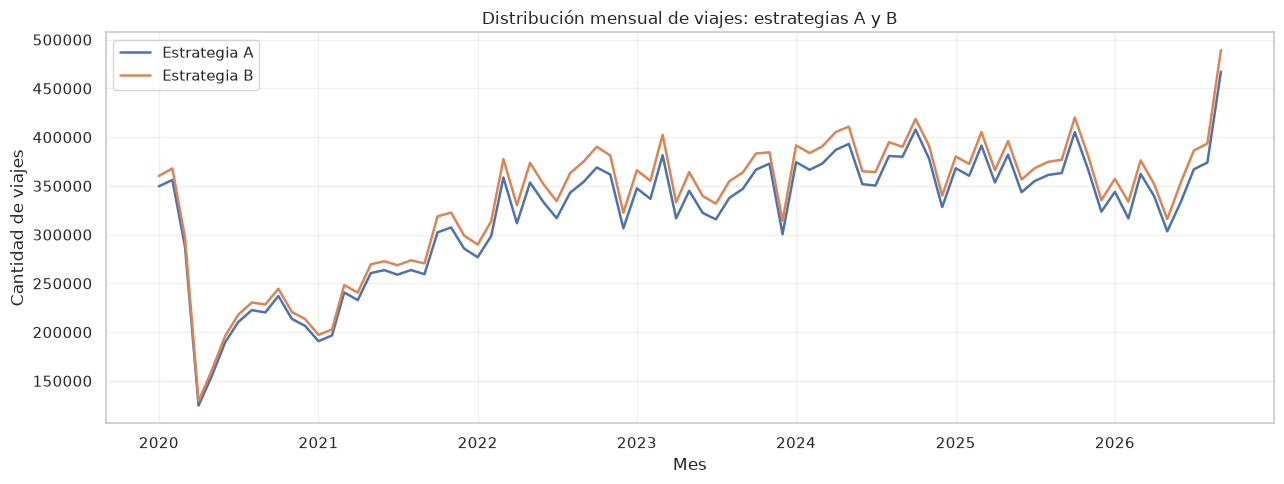

In [136]:
# Obtener las rutas de los archivos procesados.
strategy_paths = {
    "A": final_output_paths["A"]["parquet"],
    "B": final_output_paths["B"]["parquet"]
}

# Calcular los viajes mensuales de cada estrategia.
monthly_comparison_parts = []

for strategy, parquet_path in strategy_paths.items():
    parquet_file = pq.ParquetFile(parquet_path)
    monthly_counts = Counter()

    for batch in parquet_file.iter_batches(
        batch_size=250_000,
        columns=["Inicio_del_viaje"]
    ):
        chunk = batch.to_pandas()

        months = (
            chunk["Inicio_del_viaje"]
            .dt.to_period("M")
            .value_counts()
        )

        monthly_counts.update(months.to_dict())

    strategy_monthly = pd.DataFrame({
        "Mes": list(monthly_counts.keys()),
        "Cantidad_viajes": list(monthly_counts.values())
    })

    strategy_monthly["Estrategia"] = strategy
    monthly_comparison_parts.append(strategy_monthly)

# Unir los resultados y ordenar cronológicamente.
monthly_comparison = (
    pd.concat(monthly_comparison_parts, ignore_index=True)
    .sort_values(["Mes", "Estrategia"])
    .reset_index(drop=True)
)

# Organizar los resultados para comparar ambas estrategias.
monthly_comparison_table = (
    monthly_comparison
    .pivot(
        index="Mes",
        columns="Estrategia",
        values="Cantidad_viajes"
    )
    .fillna(0)
    .astype("int64")
)

monthly_comparison_table["Diferencia_B_A"] = (
    monthly_comparison_table["B"]
    - monthly_comparison_table["A"]
)

# Verificar que los totales coincidan con la limpieza.
for strategy in ["A", "B"]:
    assert (
        monthly_comparison_table[strategy].sum()
        == final_summary.loc["kept_rows", strategy]
    ), f"El total mensual no coincide para la estrategia {strategy}."

display(monthly_comparison_table.head())

# Graficar la distribución mensual.
fig, ax = plt.subplots(figsize=(13, 5))

for strategy in ["A", "B"]:
    ax.plot(
        monthly_comparison_table.index.to_timestamp(),
        monthly_comparison_table[strategy],
        label=f"Estrategia {strategy}",
        linewidth=1.8
    )

ax.set_title("Distribución mensual de viajes: estrategias A y B")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de viajes")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### 7.11.2. Comparación de viajes por estación

Compararemos la cantidad de viajes iniciados en cada estación para las estrategias A y B.

Primero revisaremos la distribución mediante un boxplot y después identificaremos las estaciones donde existe una mayor diferencia entre ambas estrategias.

Esto nos permitirá comprobar si los registros adicionales conservados por la estrategia B se distribuyen entre las estaciones o se concentran en algunas de ellas.

,A,B,Diferencia_B_A,Diferencia_pct
Origen_Id,,,,
51,541358,567819,26461,4.660112
50,339405,356558,17153,4.810718
11,387003,403820,16817,4.164479
75,224045,239807,15762,6.572786
54,320362,335543,15181,4.524308
271,400359,415479,15120,3.639173
52,350912,364921,14009,3.838913
194,248392,262388,13996,5.334085
35,394275,407999,13724,3.363734


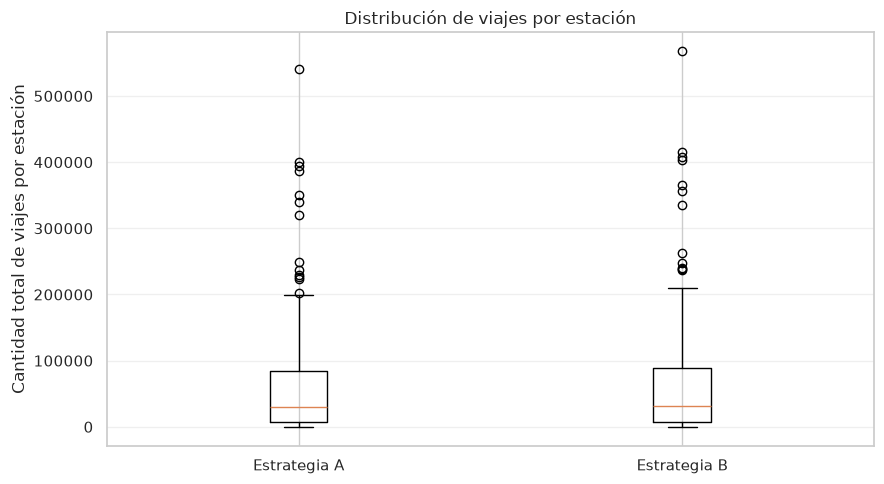

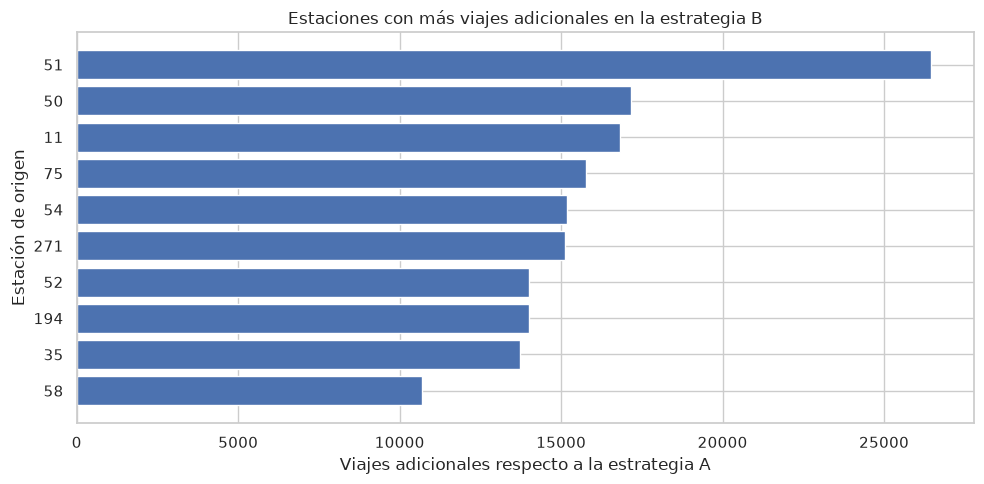

In [137]:
# Contabilizar los viajes por estación para cada estrategia.
station_counts = {}

for strategy, parquet_path in strategy_paths.items():
    parquet_file = pq.ParquetFile(parquet_path)
    station_counter = Counter()

    for batch in parquet_file.iter_batches(
        batch_size=250_000,
        columns=["Origen_Id"]
    ):
        chunk = batch.to_pandas()

        station_counter.update(
            chunk["Origen_Id"].value_counts().to_dict()
        )

    station_counts[strategy] = pd.Series(
        station_counter,
        dtype="int64"
    )

# Organizar los conteos de ambas estrategias.
station_comparison = pd.DataFrame(station_counts).fillna(0).astype("int64")
station_comparison.index.name = "Origen_Id"

station_comparison["Diferencia_B_A"] = (
    station_comparison["B"] - station_comparison["A"]
)

station_comparison["Diferencia_pct"] = np.where(
    station_comparison["B"] > 0,
    station_comparison["Diferencia_B_A"] / station_comparison["B"] * 100,
    0
)

# Comprobar los totales.
for strategy in ["A", "B"]:
    assert (
        station_comparison[strategy].sum()
        == final_summary.loc["kept_rows", strategy]
    ), f"El total por estación no coincide para {strategy}."

# Mostrar las estaciones con mayor diferencia absoluta.
display(
    station_comparison
    .sort_values("Diferencia_B_A", ascending=False)
    .head(10)
)

# Comparar la distribución de viajes por estación.
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [
        station_comparison["A"],
        station_comparison["B"]
    ],
    tick_labels=["Estrategia A", "Estrategia B"],
    showfliers=True
)

ax.set_title("Distribución de viajes por estación")
ax.set_ylabel("Cantidad total de viajes por estación")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Mostrar las 10 estaciones con mayores diferencias.
top_stations = (
    station_comparison
    .nlargest(10, "Diferencia_B_A")
    .sort_values("Diferencia_B_A")
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    top_stations.index.astype(str),
    top_stations["Diferencia_B_A"]
)

ax.set_title("Estaciones con más viajes adicionales en la estrategia B")
ax.set_xlabel("Viajes adicionales respecto a la estrategia A")
ax.set_ylabel("Estación de origen")

plt.tight_layout()
plt.show()

### Justificación de la estrategia seleccionada

Decidimos utilizar la **estrategia B**, ya que conserva el 99.98 % de los registros, frente al 95.84 % de la estrategia A. Esto representa 1,122,297 viajes adicionales.

La estrategia A descarta viajes por duraciones fuera de rango o por datos demográficos faltantes o inválidos. Como nuestro objetivo es calcular `Cantidad_viajes` por estación y hora, estas variables no son necesarias.

Además, al comparar ambas estrategias, observamos que mantienen tendencias mensuales y distribuciones por estación similares, aunque existen diferencias en la cantidad de viajes conservados.

Por estas razones, elegimos la estrategia B, que permite aprovechar más registros sin dejar de eliminar duplicados y aplicar los criterios de validación de estaciones.

## 8. Construcción de la variable objetivo y análisis exploratorio (EDA)

En esta sección utilizaremos los datos limpios de la estrategia B para construir la variable objetivo `Cantidad_viajes`, que representa el número de viajes iniciados en cada estación por hora.

Después analizaremos cómo cambia la demanda según el horario, el día y la estación.

### 8.1. Construcción de la variable objetivo (`Cantidad_viajes`)

Agrupamos los viajes de la estrategia B por estación de origen y hora. El resultado se guarda en Parquet para reutilizarlo sin volver a recorrer los viajes originales. Si el archivo ya existe, se carga únicamente cuando es necesario completar las horas sin viajes.

**Ejemplo sencillo.** Si de la estación 10 salieron tres bicicletas entre las 8:00 y las 8:59, guardamos una fila con `Origen_Id = 10`, `Hora = 8:00` y `Cantidad_viajes = 3`. No contamos las bicicletas que llegaron: aquí solo nos interesan las salidas.


In [138]:
# Definir las rutas de los resultados del EDA.
EDA_OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
EDA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
HOURLY_OBSERVED_PATH = EDA_OUTPUT_DIR / "mibici_hourly_observed.parquet"
HOURLY_COMPLETE_PATH = EDA_OUTPUT_DIR / "mibici_hourly_complete.parquet"

# Evitar repetir el conteo si ya existe el archivo de horas observadas.
if HOURLY_OBSERVED_PATH.exists():
    print("Conteo estación-hora disponible en Parquet.")
else:
    selected_parquet = final_output_paths["B"]["parquet"]
    hourly_parts = []
    parquet_file = pq.ParquetFile(selected_parquet)

    for batch in parquet_file.iter_batches(
        batch_size=250_000,
        columns=["Origen_Id", "Inicio_del_viaje"]
    ):
        chunk = batch.to_pandas()
        chunk["Hora"] = chunk["Inicio_del_viaje"].dt.floor("h")
        hourly_parts.append(
            chunk.groupby(["Origen_Id", "Hora"])
            .size().rename("Cantidad_viajes").reset_index()
        )

    hourly_demand = (
        pd.concat(hourly_parts, ignore_index=True)
        .groupby(["Origen_Id", "Hora"], as_index=False)["Cantidad_viajes"]
        .sum().sort_values(["Origen_Id", "Hora"]).reset_index(drop=True)
    )
    pq.write_table(pa.Table.from_pandas(hourly_demand, preserve_index=False), HOURLY_OBSERVED_PATH, compression="zstd")
    del hourly_parts, hourly_demand, chunk
    print("Conteo estación-hora guardado:", HOURLY_OBSERVED_PATH.name)

observed_metadata = pq.ParquetFile(HOURLY_OBSERVED_PATH).metadata
print("Registros con viajes:", f"{observed_metadata.num_rows:,}")


Conteo estación-hora disponible en Parquet.
Registros con viajes: 9,029,058


### 8.2. Incorporación de horas sin viajes

Completamos las horas entre el primer y el último viaje observado de cada estación. Esas horas se registran con cero viajes, aunque no podemos confirmar que la estación estuviera operativa. Guardamos la tabla completa en Parquet y calculamos resúmenes pequeños para las siguientes gráficas, sin conservar los 19 millones de filas en memoria.

**¿Por qué agregamos ceros?** Si una estación registró 2 viajes a las 8:00 y 4 a las 10:00, pero ninguno a las 9:00, agregamos esa hora con `Cantidad_viajes = 0`. Es como completar los espacios de un calendario para que no parezca que esa hora nunca existió. Esto no confirma que hubiera bicicletas disponibles.


In [139]:
# Crear el archivo completo solo si todavía no existe.
if not HOURLY_COMPLETE_PATH.exists():
    # Procesar una estación a la vez, sin cargar toda la tabla observada.
    writer = None
    pending = pd.DataFrame()

    def write_completed_station(station_data, parquet_writer):
        """Completar las horas de una estación y escribirlas en Parquet."""
        station_id = int(station_data["Origen_Id"].iloc[0])
        station_hours = pd.date_range(
            station_data["Hora"].min(), station_data["Hora"].max(), freq="h"
        )
        completed = (
            station_data.set_index("Hora")
            .reindex(station_hours, fill_value=0)
            .rename_axis("Hora").reset_index()
        )
        completed["Origen_Id"] = station_id
        completed = completed[["Origen_Id", "Hora", "Cantidad_viajes"]]
        completed["Origen_Id"] = completed["Origen_Id"].astype("int32")
        completed["Cantidad_viajes"] = completed["Cantidad_viajes"].astype("int32")
        table = pa.Table.from_pandas(completed, preserve_index=False)
        if parquet_writer is None:
            parquet_writer = pq.ParquetWriter(
                HOURLY_COMPLETE_PATH, table.schema, compression="zstd"
            )
        parquet_writer.write_table(table)
        return parquet_writer

    try:
        for batch in pq.ParquetFile(HOURLY_OBSERVED_PATH).iter_batches(
            batch_size=200_000,
            columns=["Origen_Id", "Hora", "Cantidad_viajes"]
        ):
            block = pd.concat([pending, batch.to_pandas()], ignore_index=True)
            last_station = block["Origen_Id"].iloc[-1]
            complete = block[block["Origen_Id"] != last_station]
            pending = block[block["Origen_Id"] == last_station].copy()
            for _, station_data in complete.groupby("Origen_Id", sort=True):
                writer = write_completed_station(station_data, writer)
        if not pending.empty:
            writer = write_completed_station(pending, writer)
    finally:
        if writer is not None:
            writer.close()
    del pending, block, complete

# Resumir por bloques y conservar únicamente agregados pequeños.
# Se ejecuta desde Parquet y no depende de variables creadas en memoria anteriormente.
value_histogram = np.zeros(1, dtype=np.int64)
hourly_totals = np.zeros((7, 24), dtype=np.int64)
hourly_counts = np.zeros((7, 24), dtype=np.int64)
weekday_histograms = [np.zeros(1, dtype=np.int64) for _ in range(7)]
station_totals = {}
station_counts = {}
station_maximums = {}
station_histograms = {}

for batch in pq.ParquetFile(HOURLY_COMPLETE_PATH).iter_batches(
    batch_size=200_000, columns=["Origen_Id", "Hora", "Cantidad_viajes"]
):
    chunk = batch.to_pandas()
    values = chunk["Cantidad_viajes"].to_numpy(dtype=np.int32)
    counts = np.bincount(values)
    if len(counts) > len(value_histogram):
        value_histogram = np.pad(value_histogram, (0, len(counts) - len(value_histogram)))
    value_histogram[:len(counts)] += counts

    weekdays = chunk["Hora"].dt.dayofweek.to_numpy()
    hours = chunk["Hora"].dt.hour.to_numpy()
    np.add.at(hourly_totals, (weekdays, hours), values)
    np.add.at(hourly_counts, (weekdays, hours), 1)

    for day in range(7):
        day_hist = np.bincount(values[weekdays == day])
        if len(day_hist) > len(weekday_histograms[day]):
            weekday_histograms[day] = np.pad(
                weekday_histograms[day], (0, len(day_hist) - len(weekday_histograms[day]))
            )
        weekday_histograms[day][:len(day_hist)] += day_hist

    for station_id, group in chunk.groupby("Origen_Id"):
        station_id = int(station_id)
        station_values = group["Cantidad_viajes"].to_numpy(dtype=np.int32)
        station_totals[station_id] = station_totals.get(station_id, 0) + int(station_values.sum())
        station_counts[station_id] = station_counts.get(station_id, 0) + len(station_values)
        station_maximums[station_id] = max(
            station_maximums.get(station_id, 0), int(station_values.max())
        )
        station_hist = np.bincount(station_values)
        previous = station_histograms.get(station_id, np.zeros(0, dtype=np.int64))
        if len(previous) < len(station_hist):
            previous = np.pad(previous, (0, len(station_hist) - len(previous)))
        previous[:len(station_hist)] += station_hist
        station_histograms[station_id] = previous

def histogram_percentile(histogram, percentile):
    """Calcular un percentil exacto a partir de frecuencias enteras."""
    cumulative = np.cumsum(histogram)
    total = int(cumulative[-1])
    def value_at(position):
        return int(np.searchsorted(cumulative, position + 1, side="left"))
    position = (total - 1) * percentile / 100
    lower = int(np.floor(position))
    upper = int(np.ceil(position))
    return value_at(lower) + (value_at(upper) - value_at(lower)) * (position - lower)

complete_rows = int(value_histogram.sum())
zero_demand_hours = int(value_histogram[0])
print("Registros estación-hora:", f"{complete_rows:,}")
print("Horas sin viajes:", f"{zero_demand_hours:,}")
print("Viajes contabilizados:", f"{int(np.dot(np.arange(len(value_histogram)), value_histogram)):,}")


Registros estación-hora: 19,323,669
Horas sin viajes: 10,294,611
Viajes contabilizados: 27,081,838


### 8.3. Distribución de la demanda por estación y hora

Analizaremos la distribución de `Cantidad_viajes` para conocer la demanda habitual por estación y hora, así como identificar periodos con poca actividad y valores elevados.

Para ello utilizaremos estadísticas descriptivas y un histograma que incluya las horas sin viajes.

**Cómo leer los porcentajes.** Cada registro representa una estación durante una hora. Si tenemos 100 registros y 53 contienen cero viajes, decimos que el 53% de las estaciones-hora registró cero salidas. No significa que el 53% de las estaciones nunca se utilizó.


,Cantidad_viajes
count,1.932367e+07
mean,1.401485e+00
std,2.510214e+00
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,2.000000e+00
90%,4.000000e+00
95%,6.000000e+00
99%,1.100000e+01


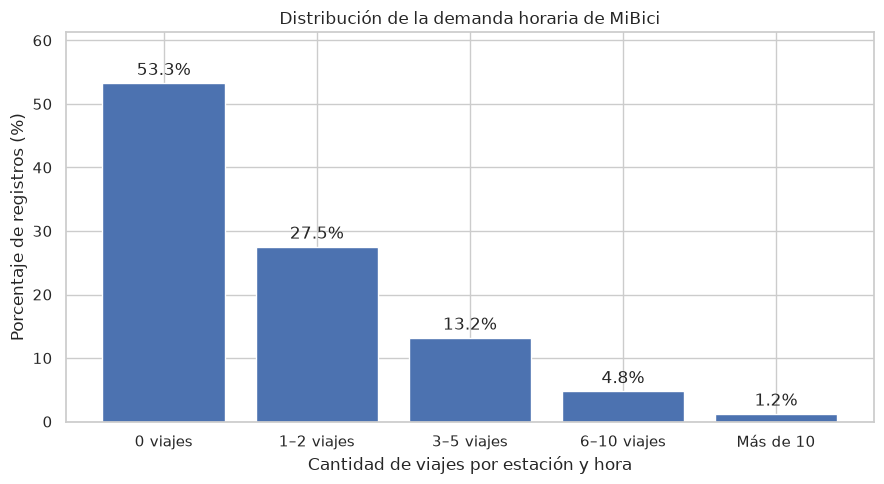

In [140]:
# Estadísticas calculadas a partir de las frecuencias de demanda.
all_values = np.arange(len(value_histogram))
total_trips = int(np.dot(all_values, value_histogram))
mean_demand = total_trips / complete_rows
variance = np.dot((all_values - mean_demand) ** 2, value_histogram) / (complete_rows - 1)
demand_stats = pd.Series({
    "count": complete_rows, "mean": mean_demand, "std": np.sqrt(variance),
    "min": histogram_percentile(value_histogram, 0),
    "25%": histogram_percentile(value_histogram, 25),
    "50%": histogram_percentile(value_histogram, 50),
    "75%": histogram_percentile(value_histogram, 75),
    "90%": histogram_percentile(value_histogram, 90),
    "95%": histogram_percentile(value_histogram, 95),
    "99%": histogram_percentile(value_histogram, 99),
    "max": histogram_percentile(value_histogram, 100)
}, name="Cantidad_viajes")
display(demand_stats.to_frame())

range_labels = ["0 viajes", "1–2 viajes", "3–5 viajes", "6–10 viajes", "Más de 10"]
range_counts = [
    value_histogram[0], value_histogram[1:3].sum(),
    value_histogram[3:6].sum(), value_histogram[6:11].sum(),
    value_histogram[11:].sum()
]
demand_distribution = pd.Series(
    np.array(range_counts) / complete_rows * 100, index=range_labels
)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(demand_distribution.index, demand_distribution.values)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Cantidad de viajes por estación y hora")
ax.set_ylabel("Porcentaje de registros (%)")
ax.set_title("Distribución de la demanda horaria de MiBici")
ax.set_ylim(0, demand_distribution.max() * 1.15)
plt.tight_layout()
plt.show()


### 8.4. Demanda por hora del día

Analizaremos cómo cambia la demanda de MiBici a lo largo del día para identificar los horarios con mayor y menor actividad.

Para ello calcularemos el promedio de viajes por estación y hora del día, utilizando los registros de la estrategia B e incluyendo las horas sin viajes que incorporamos anteriormente.

Esto nos permitirá observar si existen patrones horarios que puedan ser útiles para la predicción de demanda.

**Cómo se calcula.** Sumamos los viajes registrados a las 8:00 en todas las estaciones y fechas, y dividimos entre el número de registros de estación-hora correspondientes a las 8:00. Por ejemplo, si tres registros tienen 2, 4 y 0 viajes, el promedio es `(2 + 4 + 0) / 3 = 2` viajes por estación-hora.


,Hora_del_dia,Promedio_viajes,Registros
0,0,0.181171,804936
1,1,0.000173,804936
2,2,0.000011,804936
3,3,0.000001,804936
4,4,0.000055,804936
5,5,0.194637,804938
6,6,0.858147,804977
7,7,1.722452,805043
8,8,2.553380,805101
9,9,1.921435,805141


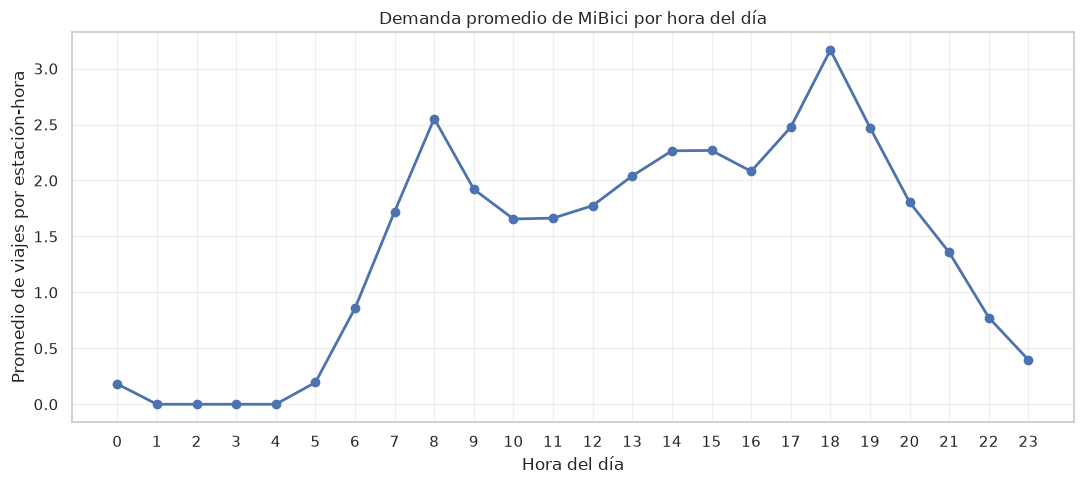

In [141]:
# Sumar las siete jornadas para cada hora del día.
hourly_pattern = pd.DataFrame({
    "Hora_del_dia": np.arange(24),
    "Promedio_viajes": hourly_totals.sum(axis=0) / hourly_counts.sum(axis=0),
    "Registros": hourly_counts.sum(axis=0)
})
display(hourly_pattern)
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hourly_pattern["Hora_del_dia"], hourly_pattern["Promedio_viajes"], marker="o", linewidth=2)
ax.set_xticks(range(24))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Promedio de viajes por estación-hora")
ax.set_title("Demanda promedio de MiBici por hora del día")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de resultados**

Observamos dos aumentos importantes en la demanda. El primero ocurre entre las 6:00 y las 8:00 de la mañana, mientras que el segundo se presenta entre las 16:00 y las 18:00, siendo esta última la hora con mayor actividad, con un promedio de 3.17 viajes por estación-hora.

Este comportamiento podría estar relacionado con los horarios de entrada y salida del trabajo o de la escuela. Para investigar esta posibilidad, sería interesante comparar las estaciones de origen y destino durante ambos periodos y revisar si algunas rutas se realizan en sentido contrario por la tarde.

Por ahora, la gráfica nos permite identificar los horarios de mayor demanda, pero no confirmar el motivo de los desplazamientos.

### 8.5. Demanda por día de la semana

Analizaremos cómo cambia la demanda de MiBici entre los distintos días de la semana.

Primero calcularemos el promedio de viajes por estación-hora para cada día. Después utilizaremos un boxplot para comparar la distribución de la demanda e identificar posibles valores atípicos.

Esto nos ayudará a revisar si existen diferencias entre los días laborales y los fines de semana.

**Ejemplo.** Para calcular el promedio de los martes, sumamos las salidas registradas en todas las estaciones durante las horas correspondientes a martes y dividimos entre la cantidad de registros de estación-hora de ese día. No es el total de viajes de un martes concreto.


,Dia_semana,Promedio_viajes,Mediana_viajes,Registros,Nombre_dia
0,0,1.489262,0.0,2760462,Lunes
1,1,1.614049,1.0,2761173,Martes
2,2,1.606041,1.0,2764739,Miércoles
3,3,1.581942,0.0,2758055,Jueves
4,4,1.521629,0.0,2759109,Viernes
5,5,1.084891,0.0,2759866,Sábado
6,6,0.912324,0.0,2760265,Domingo


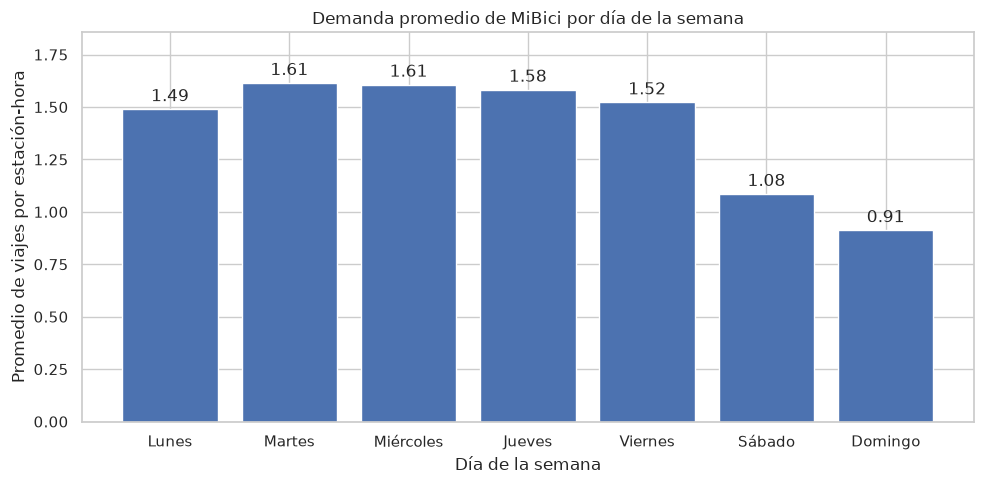

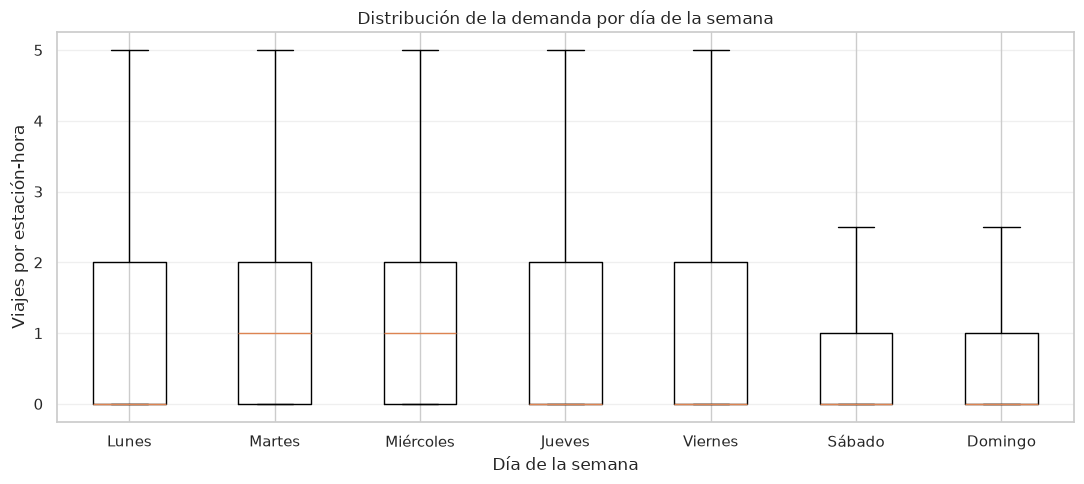

In [142]:
weekday_names = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
weekday_pattern = pd.DataFrame({
    "Dia_semana": np.arange(7),
    "Promedio_viajes": hourly_totals.sum(axis=1) / hourly_counts.sum(axis=1),
    "Mediana_viajes": [histogram_percentile(hist, 50) for hist in weekday_histograms],
    "Registros": hourly_counts.sum(axis=1),
    "Nombre_dia": weekday_names
})
display(weekday_pattern)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(weekday_pattern["Nombre_dia"], weekday_pattern["Promedio_viajes"])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_title("Demanda promedio de MiBici por día de la semana")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Promedio de viajes por estación-hora")
ax.set_ylim(0, weekday_pattern["Promedio_viajes"].max() * 1.15)
plt.tight_layout()
plt.show()

# Representar los cuartiles sin crear siete arreglos de millones de valores.
weekday_box_stats = [
    {"label": weekday_names[day],
     "whislo": histogram_percentile(hist, 0),
     "q1": histogram_percentile(hist, 25),
     "med": histogram_percentile(hist, 50),
     "q3": histogram_percentile(hist, 75),
     "whishi": min(histogram_percentile(hist, 100),
                    histogram_percentile(hist, 75) + 1.5 * (
                        histogram_percentile(hist, 75) - histogram_percentile(hist, 25))),
     "fliers": []}
    for day, hist in enumerate(weekday_histograms)
]
fig, ax = plt.subplots(figsize=(11, 5))
ax.bxp(weekday_box_stats, showfliers=False)
ax.set_title("Distribución de la demanda por día de la semana")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Viajes por estación-hora")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de resultados**

Observamos que la demanda es mayor entre semana, especialmente los martes y miércoles, con un promedio de 1.61 viajes por estación-hora. Durante los fines de semana disminuye, principalmente los domingos, cuando el promedio es de 0.91 viajes.

Los boxplots muestran un comportamiento similar. Los martes y miércoles tienen una mediana de 1 viaje, mientras que en los demás días es de 0.

También notamos que los lunes y viernes presentan una demanda ligeramente menor que los días centrales de la semana. Esto podría estar relacionado con cambios en los hábitos de transporte al inicio y al final de la semana laboral.

En conjunto, estos resultados podrían indicar una relación entre la demanda y los traslados al trabajo o a la escuela, aunque necesitaríamos más información para confirmarlo.

### 8.6. Demanda por estación

Analizaremos las diferencias de demanda entre estaciones para identificar cuáles presentan mayor y menor actividad.

Calcularemos el promedio de viajes por hora de cada estación y compararemos los resultados mediante gráficas de barras. También revisaremos la distribución de estos promedios para identificar estaciones con valores inusualmente altos.

Utilizaremos los registros de la estrategia B, incluyendo las horas sin viajes que incorporamos anteriormente.

**Ejemplo.** Si una estación registra 10 viajes en cuatro horas observadas, su promedio es `10 / 4 = 2.5` viajes por hora. Así podemos comparar estaciones con distintas cantidades de horas registradas, aunque hay que tener cuidado si no estuvieron disponibles durante el mismo periodo.


,Origen_Id,Promedio_viajes,Mediana_viajes,Total_viajes,Horas_observadas,Maximo_viajes
0,51,9.599158,8.0,567819,59153,91
1,271,7.023921,6.0,415479,59152,41
2,35,6.897468,5.0,407999,59152,53
3,11,6.826588,6.0,403820,59154,39
4,52,6.169104,5.0,364921,59153,40
5,50,6.027623,5.0,356558,59154,104
6,54,5.672460,5.0,335543,59153,78
7,194,4.435826,2.0,262388,59152,207
8,260,4.190357,3.0,247868,59152,33
9,75,4.054150,3.0,239807,59151,34


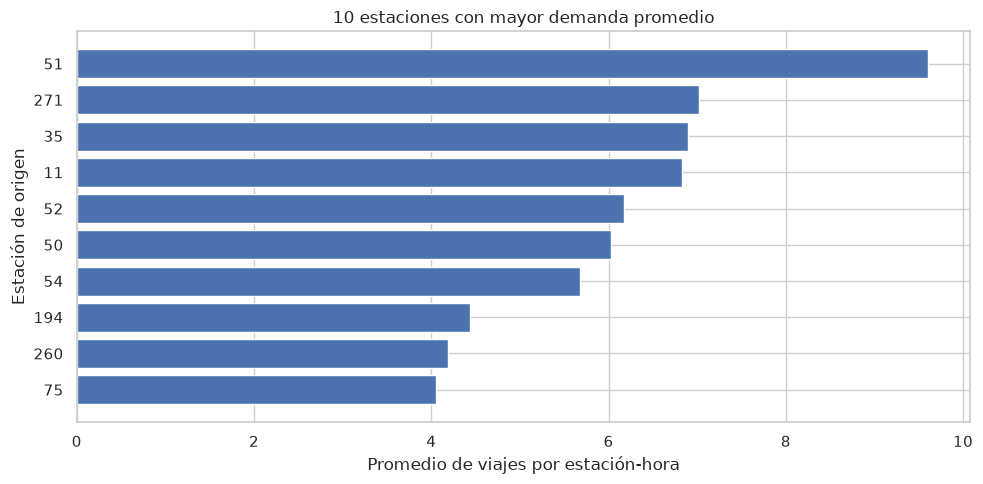

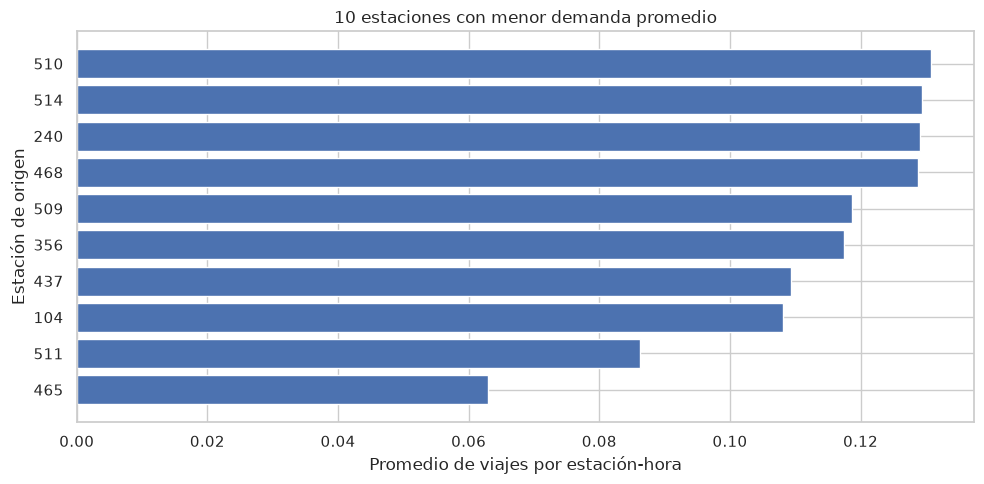

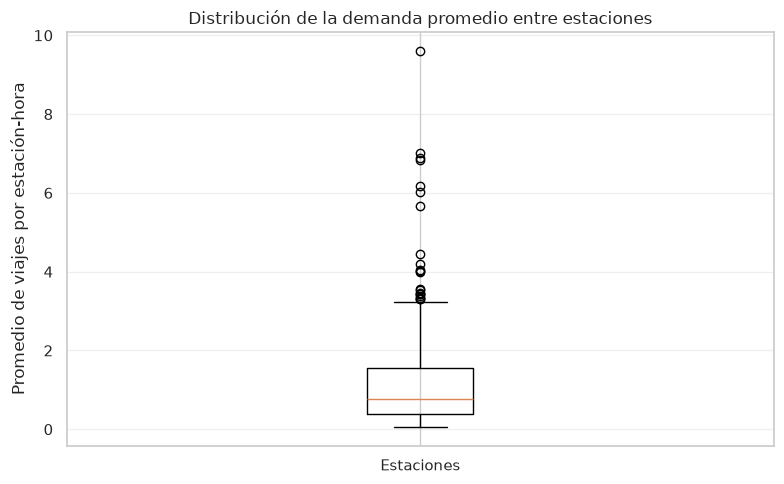

In [143]:
# Calcular las estadísticas de cada estación desde los resúmenes.
station_demand = pd.DataFrame([
    {"Origen_Id": station_id,
     "Promedio_viajes": station_totals[station_id] / station_counts[station_id],
     "Mediana_viajes": histogram_percentile(station_histograms[station_id], 50),
     "Total_viajes": station_totals[station_id],
     "Horas_observadas": station_counts[station_id],
     "Maximo_viajes": station_maximums[station_id]}
    for station_id in station_totals
]).sort_values("Promedio_viajes", ascending=False).reset_index(drop=True)
display(station_demand.head(10))

top_stations = station_demand.head(10).sort_values("Promedio_viajes")
bottom_stations = station_demand.tail(10).sort_values("Promedio_viajes")
for title, selected in [
    ("10 estaciones con mayor demanda promedio", top_stations),
    ("10 estaciones con menor demanda promedio", bottom_stations)
]:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(selected["Origen_Id"].astype(str), selected["Promedio_viajes"])
    ax.set_title(title)
    ax.set_xlabel("Promedio de viajes por estación-hora")
    ax.set_ylabel("Estación de origen")
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(station_demand["Promedio_viajes"], tick_labels=["Estaciones"], showfliers=True)
ax.set_title("Distribución de la demanda promedio entre estaciones")
ax.set_ylabel("Promedio de viajes por estación-hora")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de resultados**

Encontramos diferencias importantes en la demanda entre estaciones. La estación 51 presenta el promedio más alto, con 9.60 viajes por hora, mientras que las estaciones con menor actividad registran promedios inferiores a 0.13 viajes.

En el boxplot observamos que la mayoría de las estaciones tiene promedios relativamente bajos, pero existen algunas que destacan por tener una demanda mucho mayor. Estas estaciones aparecen como valores atípicos, aunque esto no significa que sus registros sean incorrectos.

Sería interesante investigar si estas diferencias están relacionadas con la ubicación de las estaciones, los lugares cercanos o la infraestructura vial disponible, como ciclovías y calles adecuadas para circular en bicicleta.

También será bueno considerar encuestas para conocer los motivos de uso y entender por qué las personas prefieren determinadas estaciones. Esta información, junto con los datos de disponibilidad de bicicletas, ayudaría a evaluar si conviene ampliar la capacidad de algunos puntos, instalar nuevas estaciones o revisar la ubicación de las que tienen menor actividad.

Por ahora, los resultados muestran que la estación de origen es una variable importante para analizar y predecir la demanda, pero necesitamos información adicional para explicar las diferencias encontradas.

### 8.7. Evolución mensual de la demanda

Analizaremos cómo ha cambiado la cantidad de viajes a lo largo del periodo disponible, desde enero de 2020 hasta septiembre de 2026.

Revisaremos los viajes registrados por mes y su variación porcentual respecto al mes anterior. Esto nos permitirá identificar periodos de crecimiento, disminuciones importantes y posibles cambios en el comportamiento de la demanda.

**Ejemplo de variación mensual.** Si un mes tuvo 100,000 viajes y el siguiente 110,000, el cambio es `(110,000 - 100,000) / 100,000 × 100 = 10%`. Un porcentaje negativo indica que hubo menos viajes que el mes anterior.


Estrategia,Cantidad_viajes,Variacion_pct
count,81.00,80.00
mean,334343.68,1.23
std,67787.51,12.09
min,129276.00,-56.44
25%,299005.00,-6.06
50%,356611.00,1.56
75%,380328.00,8.48
max,489298.00,24.65


Meses con mayor cantidad de viajes:


Estrategia,Cantidad_viajes,Variacion_pct
Mes,,
2026-09,489298,24.337525
2025-10,420064,11.485208
2024-10,418690,7.336594
2024-05,410806,1.356499
2024-04,405308,3.788606


Meses con menor cantidad de viajes:


Estrategia,Cantidad_viajes,Variacion_pct
Mes,,
2020-04,129276,-56.436938
2020-05,160437,24.104242
2020-06,196071,22.210587
2021-01,197195,-7.648681
2021-02,202781,2.832729


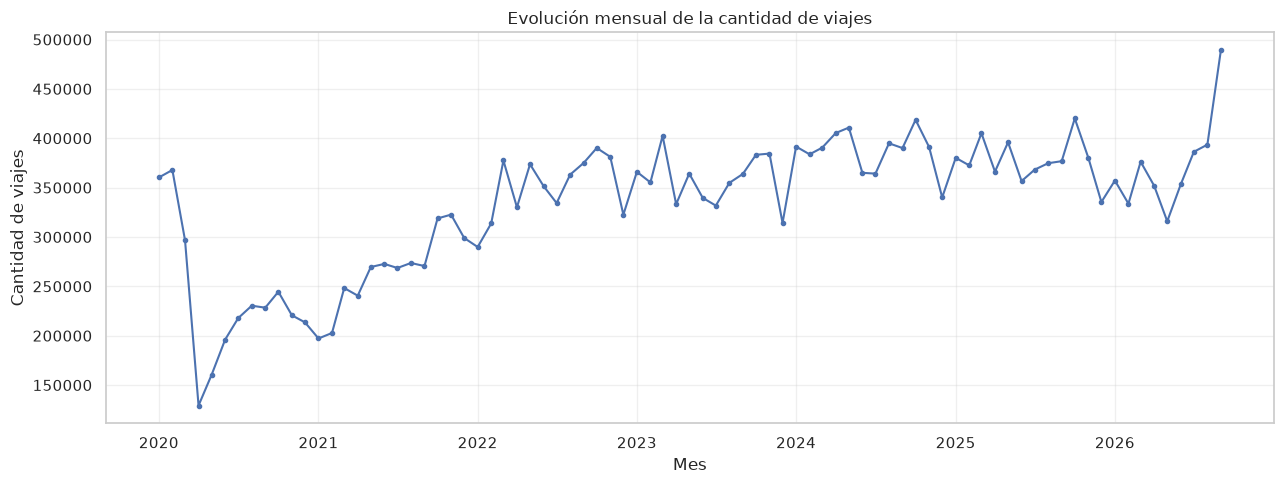

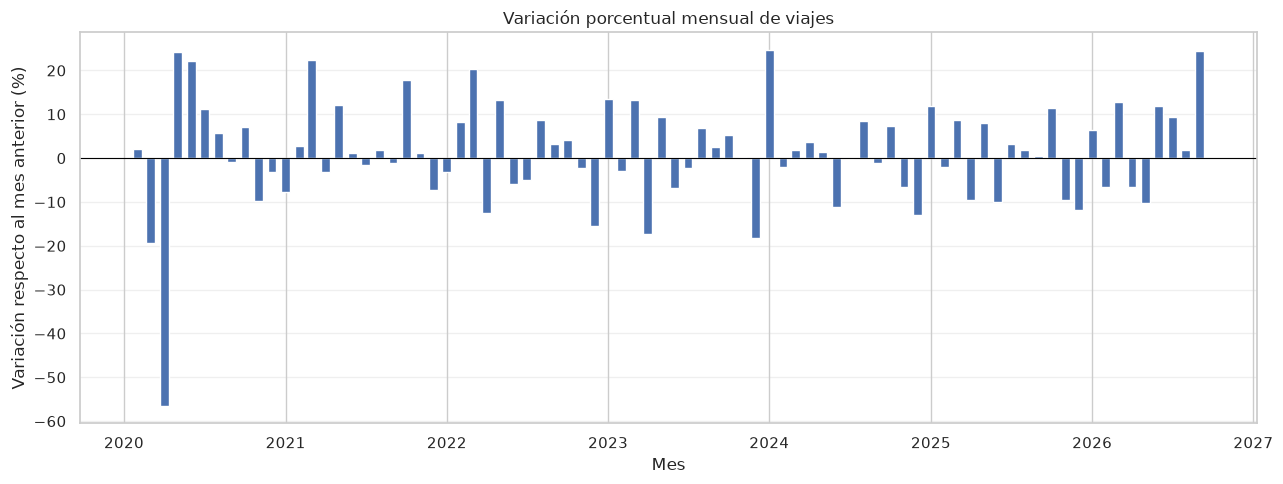

In [144]:
# Recuperar los viajes mensuales de la estrategia B.
monthly_demand = (
    monthly_comparison_table[["B"]]
    .rename(columns={"B": "Cantidad_viajes"})
    .copy()
)

# Calcular el cambio porcentual respecto al mes anterior.
monthly_demand["Variacion_pct"] = (
    monthly_demand["Cantidad_viajes"]
    .pct_change()
    * 100
)

# Mostrar las estadísticas descriptivas.
display(monthly_demand.describe().round(2))

# Mostrar los meses con mayor y menor cantidad de viajes.
print("Meses con mayor cantidad de viajes:")
display(
    monthly_demand.nlargest(5, "Cantidad_viajes")
)

print("Meses con menor cantidad de viajes:")
display(
    monthly_demand.nsmallest(5, "Cantidad_viajes")
)

# Graficar la evolución mensual de viajes.
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_demand.index.to_timestamp(),
    monthly_demand["Cantidad_viajes"],
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.set_title("Evolución mensual de la cantidad de viajes")
ax.set_xlabel("Mes")
ax.set_ylabel("Cantidad de viajes")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Graficar la variación porcentual mensual.
fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    monthly_demand.index.to_timestamp(),
    monthly_demand["Variacion_pct"],
    width=20
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Variación porcentual mensual de viajes")
ax.set_xlabel("Mes")
ax.set_ylabel("Variación respecto al mes anterior (%)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación de resultados**

Observamos una caída muy marcada en abril de 2020, cuando se registraron 129,276 viajes, un 56.44 % menos que en marzo. Esto podría estar relacionado con las restricciones de movilidad durante la pandemia de COVID-19.

A partir de 2021 comienza a notarse una recuperación y una tendencia de crecimiento. Entre 2022 y 2025, la cantidad de viajes se mantiene relativamente estable, aunque presenta aumentos y disminuciones de un mes a otro.

También identificamos posibles patrones que se repiten durante el año. En algunos periodos observamos caídas alrededor de marzo y abril, seguidas de una recuperación. Esto no significa que abril sea uno de los meses con mayor demanda, sino que en ciertos años comienza a aumentar nuevamente la cantidad de viajes después de una disminución.

Por otro lado, octubre presenta varios picos de demanda, especialmente en 2024 y 2025, lo que podría indicar que es una época de mayor actividad. Sería interesante investigar si estas variaciones están relacionadas con el clima, las vacaciones, los periodos escolares u otros factores. Para comprobarlo, compararemos los mismos meses entre diferentes años en el análisis de estacionalidad.

Finalmente, en septiembre de 2026 se registra el valor más alto de todo el periodo, con 489,298 viajes y un aumento del 24.34 % respecto a agosto. Este incremento llama la atención y sería conveniente revisar si está relacionado con cambios en el número de estaciones, eventos o una mayor utilización del servicio.

También debemos considerar que los meses tienen distinta cantidad de días y que el número de estaciones disponibles puede haber cambiado a lo largo de los años, por lo que estas diferencias no necesariamente representan cambios en el uso promedio de cada estación.

### 8.8. Comparación entre días laborales y fines de semana

Compararemos cómo cambia la demanda durante las 24 horas del día entre lunes y viernes y durante los fines de semana.

Queremos revisar si los aumentos que identificamos por la mañana y por la tarde se presentan principalmente en días laborales o si también ocurren los sábados y domingos.

Para ello calcularemos el promedio de viajes por estación-hora y utilizaremos una gráfica de líneas y un mapa de calor.

**Ejemplo.** No comparamos únicamente el total de viajes de lunes a viernes contra el de sábado y domingo, porque los periodos tienen distinta cantidad de días. Comparamos los promedios por estación-hora para ver cómo cambia un horario típico entre ambos grupos.


,Lunes a viernes,Fin de semana
Hora_del_dia,,
0,0.14,0.27
1,0.00,0.00
2,0.00,0.00
3,0.00,0.00
4,0.00,0.00
5,0.23,0.10
6,1.06,0.36
7,2.13,0.70
8,3.10,1.18


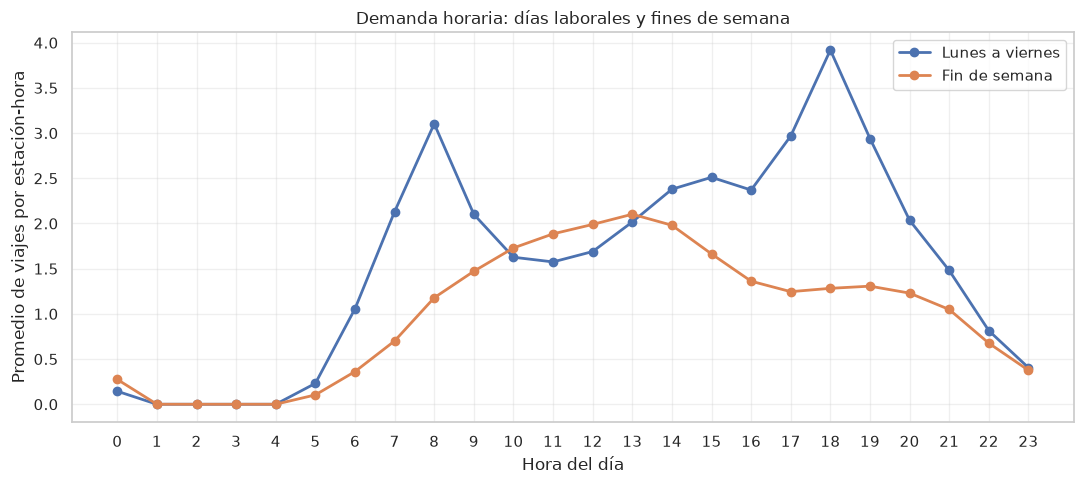

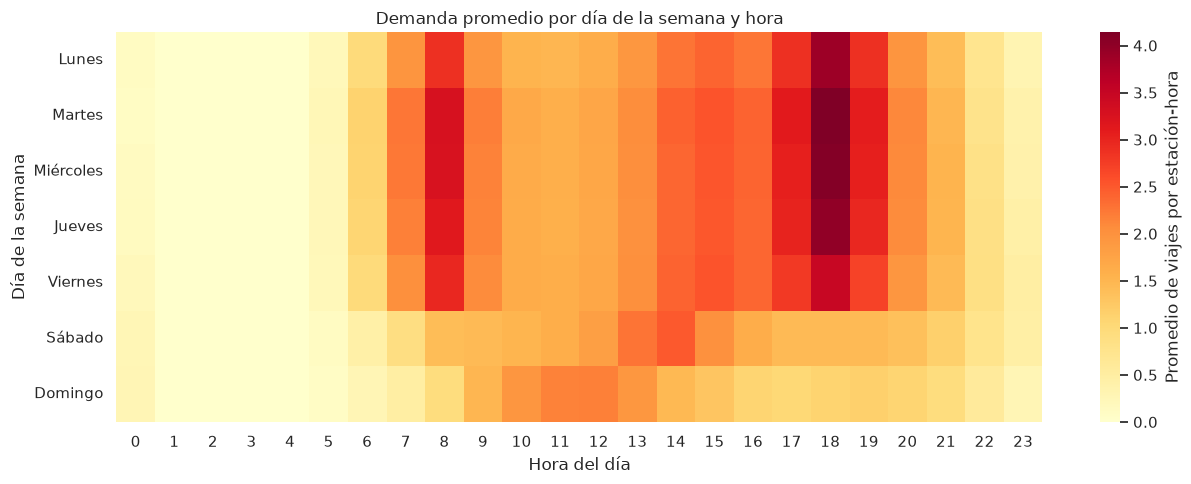

In [145]:
# Usar los resúmenes de día y hora, sin cargar la tabla completa.
workday_totals = hourly_totals[:5].sum(axis=0)
workday_counts = hourly_counts[:5].sum(axis=0)
weekend_totals = hourly_totals[5:].sum(axis=0)
weekend_counts = hourly_counts[5:].sum(axis=0)

day_type_table = pd.DataFrame({
    "Lunes a viernes": workday_totals / workday_counts,
    "Fin de semana": weekend_totals / weekend_counts
}, index=pd.Index(range(24), name="Hora_del_dia"))
display(day_type_table.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
for category in day_type_table.columns:
    ax.plot(day_type_table.index, day_type_table[category], marker="o", linewidth=2, label=category)
ax.set_xticks(range(24))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Promedio de viajes por estación-hora")
ax.set_title("Demanda horaria: días laborales y fines de semana")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

weekday_hour_pattern = pd.DataFrame(
    hourly_totals / hourly_counts,
    index=["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"],
    columns=range(24)
)
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(weekday_hour_pattern, cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "Promedio de viajes por estación-hora"})
ax.set_title("Demanda promedio por día de la semana y hora")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Día de la semana")
plt.tight_layout()
plt.show()


**Interpretación de resultados**

Al separar los días laborales de los fines de semana encontramos comportamientos distintos. De lunes a viernes la demanda aumenta principalmente alrededor de las 8:00 y las 18:00, mientras que los sábados y domingos el periodo de mayor actividad se desplaza hacia el mediodía.

Esto podría estar relacionado con diferentes motivos de viaje, pero los horarios por sí solos no permiten confirmarlo. Para comprobarlo necesitaríamos analizar también las estaciones de destino y las rutas recorridas.


### 8.9. Análisis de estacionalidad por mes del año

Analizaremos cómo cambia la demanda entre los meses del año para identificar posibles patrones que se repiten.

En la evolución mensual observamos algunas disminuciones y recuperaciones alrededor de marzo y abril, así como valores elevados en octubre. Ahora compararemos estos meses entre distintos años para revisar si existe un comportamiento similar.

Como los meses tienen diferente cantidad de días, calcularemos el promedio diario de viajes. También utilizaremos un mapa de calor para comparar la demanda mensual entre años.

**Ejemplo del promedio diario.** Septiembre de 2026 registró 489,298 viajes; como tiene 30 días, su promedio fue `489,298 / 30 ≈ 16,310` viajes diarios en todo el sistema. Para comparar los meses de septiembre de distintos años, promediamos sus valores diarios. Esto evita que febrero parezca tener menos demanda solo por tener menos días.


,Promedio_diario,Mediana_diaria,Años_observados
Mes,,,
Enero,10794.05,11621.81,7
Febrero,11754.01,12684.93,7
Marzo,11506.36,12177.58,7
Abril,10269.00,11107.03,7
Mayo,10555.34,11747.87,7
Junio,10642.61,11719.83,7
Julio,10466.60,10785.68,7
Agosto,10991.63,11714.87,7
Septiembre,11876.04,12500.47,7


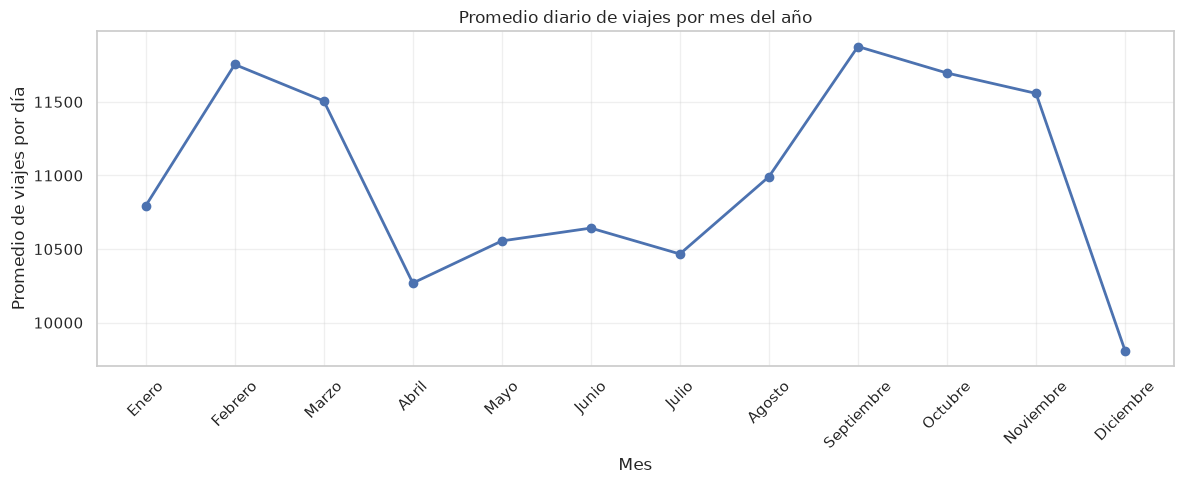

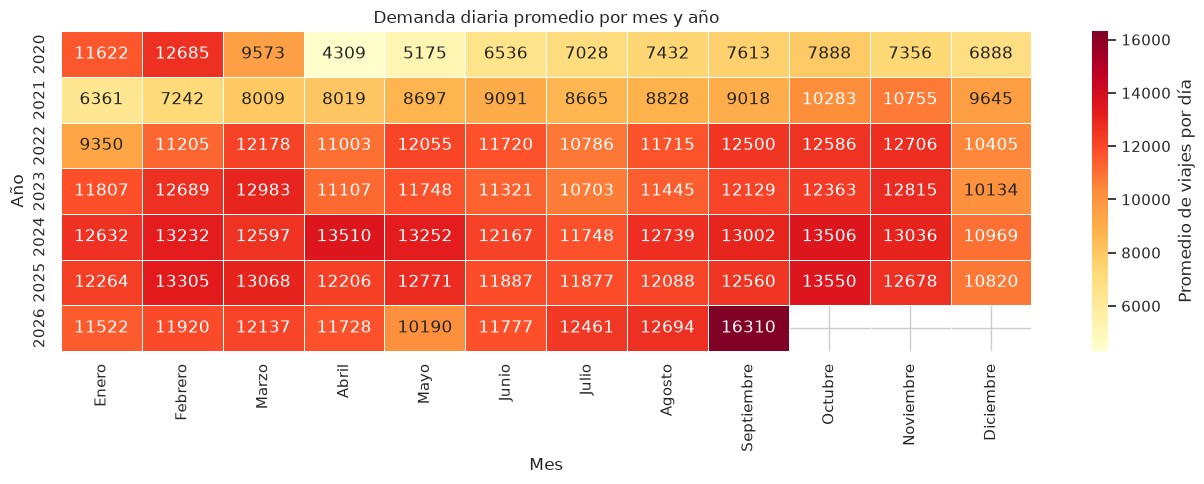

In [146]:

# Preparar los datos mensuales para analizar la estacionalidad.
seasonal_demand = monthly_demand[["Cantidad_viajes"]].copy()

# Extraer el año y el mes del índice temporal.
seasonal_demand["Año"] = seasonal_demand.index.year
seasonal_demand["Mes_numero"] = seasonal_demand.index.month
seasonal_demand["Dias_mes"] = seasonal_demand.index.days_in_month

# Calcular el promedio diario de viajes.
seasonal_demand["Promedio_diario"] = (
    seasonal_demand["Cantidad_viajes"]
    / seasonal_demand["Dias_mes"]
)

month_names = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

# Resumir la demanda diaria promedio para cada mes del año.
seasonal_summary = (
    seasonal_demand
    .groupby("Mes_numero")["Promedio_diario"]
    .agg(["mean", "median", "count"])
    .rename(columns={
        "mean": "Promedio_diario",
        "median": "Mediana_diaria",
        "count": "Años_observados"
    })
    .reindex(range(1, 13))
)

seasonal_summary.index = month_names
seasonal_summary.index.name = "Mes"

display(seasonal_summary.round(2))

# Comparar los meses entre diferentes años.
seasonal_table = seasonal_demand.pivot(
    index="Año",
    columns="Mes_numero",
    values="Promedio_diario"
)

seasonal_table = seasonal_table.reindex(columns=range(1, 13))
seasonal_table.columns = month_names

# Gráfica del promedio diario por mes del año.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    seasonal_summary.index,
    seasonal_summary["Promedio_diario"],
    marker="o",
    linewidth=2
)

ax.set_title("Promedio diario de viajes por mes del año")
ax.set_xlabel("Mes")
ax.set_ylabel("Promedio de viajes por día")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Mapa de calor de la demanda mensual por año.
fig, ax = plt.subplots(figsize=(13, 5))

sns.heatmap(
    seasonal_table,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Promedio de viajes por día"},
    ax=ax
)

ax.set_title("Demanda diaria promedio por mes y año")
ax.set_xlabel("Mes")
ax.set_ylabel("Año")

plt.tight_layout()
plt.show()


**Interpretación de resultados**

Observamos que abril tiene uno de los promedios diarios más bajos, con 10,269 viajes, aunque la caída respecto a marzo no se presenta todos los años. Por otro lado, septiembre y octubre destacan por tener una demanda elevada, especialmente entre 2022 y 2025.

También podemos ver claramente la caída de abril de 2020, posiblemente relacionada con la pandemia. A partir de 2021 comienza una recuperación y, entre 2022 y 2025, la demanda muestra un comportamiento relativamente estable.

En septiembre de 2026 encontramos el valor más alto, con 16,310 viajes diarios. Sería interesante investigar qué provocó este aumento.

Estos resultados sugieren que podría existir cierta estacionalidad en la demanda, aunque también debemos considerar los cambios en el número de estaciones disponibles a lo largo de los años.

### 8.9.1. Análisis de valores atípicos

Revisaremos los valores más altos de `Cantidad_viajes` para identificar estaciones y horarios con una demanda poco habitual.

Anteriormente encontramos un máximo de 207 viajes en una estación durante una hora. Ahora analizaremos qué tan frecuentes son estos casos y en qué estaciones ocurren.

Utilizaremos percentiles y el rango intercuartílico (IQR) para identificar valores atípicos. No eliminaremos registros, ya que una demanda elevada no necesariamente representa un error.

**¿Qué significa el IQR?** Ordenamos los valores de viajes por estación-hora. `Q1` deja por debajo aproximadamente al 25% de los registros y `Q3` al 75%. Aquí `Q1 = 0` y `Q3 = 2`, así que `IQR = 2 - 0 = 2` y el límite es `2 + 1.5 × 2 = 5`. Superarlo indica que el valor es poco habitual según esta regla, no que sea un error.


Q1: 0.00
Q3: 2.00
IQR: 2.00
Límite superior: 5.00
Registros analizados: 19,323,669
Valores atípicos: 1,162,090
Porcentaje: 6.01%


,Origen_Id,Hora,Cantidad_viajes
0,194,2025-09-20 21:00:00,207
1,194,2025-09-20 20:00:00,178
2,194,2026-04-04 20:00:00,149
3,194,2026-09-05 21:00:00,141
4,194,2026-04-04 21:00:00,132
5,194,2026-02-07 20:00:00,124
6,194,2026-02-07 21:00:00,121
7,194,2026-09-05 20:00:00,111
8,194,2025-11-01 21:00:00,109
9,194,2026-03-07 20:00:00,109


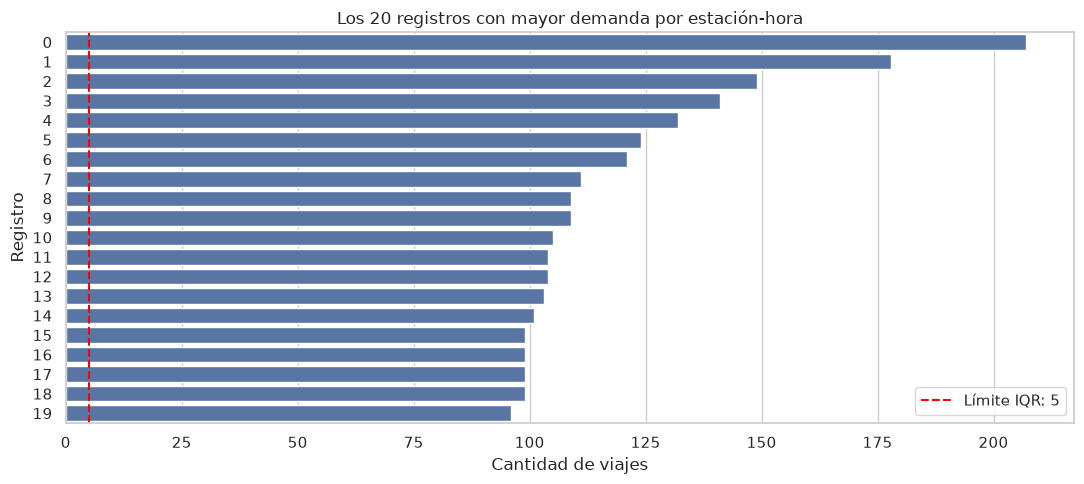

In [147]:
# Analizar valores atípicos sin cargar toda la demanda en memoria.
hourly_parquet_path = (
    PROJECT_DIR / "data" / "processed"
    / "mibici_hourly_complete.parquet"
)

# Utilizar los cuartiles calculados previamente.
q1 = demand_stats["25%"]
q3 = demand_stats["75%"]

iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

# Acumular estadísticas y conservar únicamente los valores extremos.
total_records = 0
outlier_records = 0
extreme_records = []

parquet_file = pq.ParquetFile(hourly_parquet_path)

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["Origen_Id", "Hora", "Cantidad_viajes"]
):
    chunk = batch.to_pandas()

    outliers = chunk[
        chunk["Cantidad_viajes"] > upper_limit
    ]

    total_records += len(chunk)
    outlier_records += len(outliers)

    # Conservar los 20 valores más altos de cada bloque.
    if not outliers.empty:
        extreme_records.append(
            outliers.nlargest(20, "Cantidad_viajes")
        )

# Unir únicamente los candidatos a valores extremos.
extreme_demand = (
    pd.concat(extreme_records, ignore_index=True)
    .nlargest(20, "Cantidad_viajes")
    .reset_index(drop=True)
)

outlier_percentage = outlier_records / total_records * 100

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Límite superior: {upper_limit:.2f}")
print(f"Registros analizados: {total_records:,}")
print(f"Valores atípicos: {outlier_records:,}")
print(f"Porcentaje: {outlier_percentage:.2f}%")

display(extreme_demand)

# Gráfica de los valores más altos encontrados.
fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=extreme_demand,
    x="Cantidad_viajes",
    y=extreme_demand.index.astype(str),
    ax=ax
)

ax.axvline(
    upper_limit,
    linestyle="--",
    color="red",
    label=f"Límite IQR: {upper_limit:.0f}"
)

ax.set_title("Los 20 registros con mayor demanda por estación-hora")
ax.set_xlabel("Cantidad de viajes")
ax.set_ylabel("Registro")
ax.legend()

plt.tight_layout()
plt.show()

**Interpretación de resultados**

De los 19,323,669 registros analizados, encontramos que el 6.01% supera el límite de 5 viajes por estación-hora establecido mediante el IQR.

El valor más alto fue de 207 viajes, registrado en la estación 194 el 20 de septiembre de 2025 a las 21:00. También observamos que esta estación aparece varias veces entre los registros con mayor demanda, principalmente durante horarios nocturnos.

Aunque estos valores se consideran atípicos estadísticamente, no necesariamente representan errores. El límite de 5 viajes es relativamente bajo y no considera que algunas estaciones tienen una demanda mayor que otras.

Por ahora, conservaremos estos registros. Sería conveniente revisar el comportamiento habitual de la estación 194 y determinar si estos incrementos corresponden a situaciones particulares.

### 8.9.2. Análisis de valores extremos por estación

En el análisis anterior identificamos valores atípicos utilizando un límite general de 5 viajes por estación-hora. Sin embargo, este criterio no considera que cada estación puede tener un comportamiento diferente.

Para complementar el análisis, calcularemos los valores habituales y máximos de cada estación, utilizando el rango intercuartílico (IQR) para establecer límites individuales.

Esto nos permitirá identificar estaciones con incrementos poco habituales respecto a su propia demanda, sin considerar automáticamente que los registros elevados son errores.

**Ejemplo de por qué usamos límites por estación.** Cinco salidas pueden ser muchas para una estación tranquila, pero pocas para otra situada en una zona muy concurrida. Por eso calculamos los cuartiles de cada estación por separado. También comparamos `Máximo / Promedio`: si el máximo es 20 y el promedio 2, la relación es 10; es decir, el máximo fue diez veces el promedio, no diez veces el número habitual de usuarios.


,Registros,Total_viajes,Maximo_viajes,Promedio_viajes,Q1,Q3,Limite_superior,Valores_atipicos,Porcentaje_atipicos,Relacion_maximo_promedio
Origen_Id,,,,,,,,,,
194,59152,262388,207,4.44,0.0,5.0,12.5,4741,8.01,46.67
50,59154,356558,104,6.03,1.0,9.0,21.0,1411,2.39,17.25
46,59153,98552,99,1.67,0.0,2.0,5.0,4288,7.25,59.42
196,59144,169167,93,2.86,0.0,4.0,10.0,2608,4.41,32.51
51,59153,567819,91,9.60,1.0,14.0,33.5,1572,2.66,9.48
54,59153,335543,78,5.67,0.0,9.0,22.5,725,1.23,13.75
79,59149,115633,72,1.95,0.0,3.0,7.5,1176,1.99,36.83
197,59151,114277,69,1.93,0.0,3.0,7.5,2539,4.29,35.72
396,15663,23051,64,1.47,0.0,2.0,5.0,806,5.15,43.49


Estaciones analizadas: 472
Total de valores atípicos: 1176701


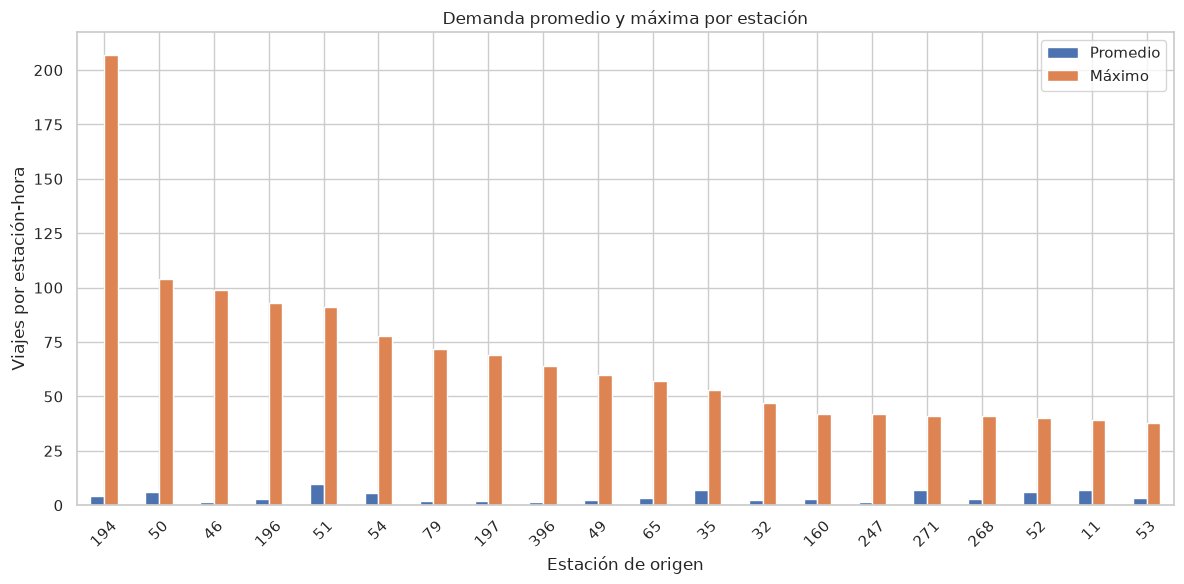

In [148]:
# Analizar valores extremos de todas las estaciones.
station_data = []

parquet_file = pq.ParquetFile(hourly_parquet_path)

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["Origen_Id", "Cantidad_viajes"]
):
    chunk = batch.to_pandas()

    station_data.append(
        chunk.groupby("Origen_Id")["Cantidad_viajes"].agg(
            Registros="count",
            Total_viajes="sum",
            Maximo_viajes="max"
        )
    )

# Consolidar los resultados de todos los bloques.
station_totals = (
    pd.concat(station_data)
    .groupby(level=0)
    .agg({
        "Registros": "sum",
        "Total_viajes": "sum",
        "Maximo_viajes": "max"
    })
)

station_totals["Promedio_viajes"] = (
    station_totals["Total_viajes"] /
    station_totals["Registros"]
)

# Calcular cuartiles y valores atípicos por estación.
station_values = {}

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["Origen_Id", "Cantidad_viajes"]
):
    chunk = batch.to_pandas()

    for station_id, group in chunk.groupby("Origen_Id"):
        station_values.setdefault(station_id, []).append(
            group["Cantidad_viajes"].to_numpy()
        )

station_outliers = []

for station_id, values in station_values.items():
    demand = np.concatenate(values)

    q1, q3 = np.percentile(demand, [25, 75])
    iqr = q3 - q1
    upper_limit = q3 + 1.5 * iqr

    outlier_count = np.count_nonzero(demand > upper_limit)

    station_outliers.append({
        "Origen_Id": station_id,
        "Q1": q1,
        "Q3": q3,
        "Limite_superior": upper_limit,
        "Valores_atipicos": outlier_count,
        "Porcentaje_atipicos": (
            outlier_count / len(demand) * 100
        )
    })

station_outlier_table = pd.DataFrame(
    station_outliers
).set_index("Origen_Id")

station_analysis = station_totals.join(
    station_outlier_table
)

station_analysis["Relacion_maximo_promedio"] = (
    station_analysis["Maximo_viajes"] /
    station_analysis["Promedio_viajes"].replace(0, np.nan)
)

# Mostrar las 20 estaciones con máximos más altos.
top_extreme_stations = (
    station_analysis
    .sort_values("Maximo_viajes", ascending=False)
    .head(20)
)

display(top_extreme_stations.round(2))

print("Estaciones analizadas:", len(station_analysis))
print(
    "Total de valores atípicos:",
    station_analysis["Valores_atipicos"].sum()
)

# Comparar el promedio y máximo de las 20 estaciones.
fig, ax = plt.subplots(figsize=(12, 6))

top_extreme_stations[
    ["Promedio_viajes", "Maximo_viajes"]
].plot.bar(ax=ax)

ax.set_title(
    "Demanda promedio y máxima por estación"
)
ax.set_xlabel("Estación de origen")
ax.set_ylabel("Viajes por estación-hora")
ax.legend(["Promedio", "Máximo"])
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Interpretación de resultados**

Analizamos las 472 estaciones y encontramos diferencias importantes entre su demanda promedio y sus valores máximos.

La estación 194 presentó el valor más alto, con 207 viajes en una hora, aunque su promedio es de 4.44. También encontramos casos como la estación 46, que tiene un promedio de 1.67 viajes y alcanzó un máximo de 99.

Por otro lado, la estación 51 registra una demanda promedio más elevada, de 9.60 viajes por hora, pero presenta una menor proporción de valores atípicos.

En total identificamos 1,176,701 registros atípicos utilizando límites individuales por estación. Esto nos muestra que no todas las estaciones tienen el mismo comportamiento y que utilizar un único límite para todo el sistema puede resultar poco representativo.

Por ahora conservaremos estos registros, ya que no tenemos evidencia suficiente para considerarlos errores.

### 8.9.3. Patrones horarios de demanda por estación

Anteriormente observamos que la demanda general presenta incrementos durante la mañana y la tarde. Sin embargo, esto no significa que todas las estaciones tengan los mismos horarios de mayor actividad.

En este análisis calcularemos la demanda promedio de cada estación para las 24 horas del día. Después identificaremos su hora de mayor demanda y compararemos los resultados entre estaciones.

También revisaremos qué tan concentrada está la demanda en los horarios de mayor actividad. Esto nos permitirá conocer mejor las diferencias entre estaciones y evaluar la importancia de las variables temporales para el futuro modelo predictivo.

**Ejemplo.** Para una estación calculamos el promedio de todas sus observaciones de las 8:00, después el de las 9:00 y así hasta las 23:00. La hora con el promedio más alto es su `Hora_pico`. No significa que todos los días tenga el máximo a esa hora.


Estaciones analizadas: 472


,Origen_Id,Hora_pico,Promedio_hora_pico,Promedio_general,Relacion_pico_promedio
0,2,8,4.90,1.96,2.51
1,3,18,4.67,1.74,2.68
2,4,18,5.91,2.37,2.49
3,5,8,4.45,1.78,2.50
4,6,8,2.63,1.16,2.26
...,...,...,...,...,...
467,515,18,1.82,0.53,3.46
468,516,8,1.34,0.33,4.07
469,517,15,1.04,0.33,3.18
470,518,9,1.59,0.49,3.27


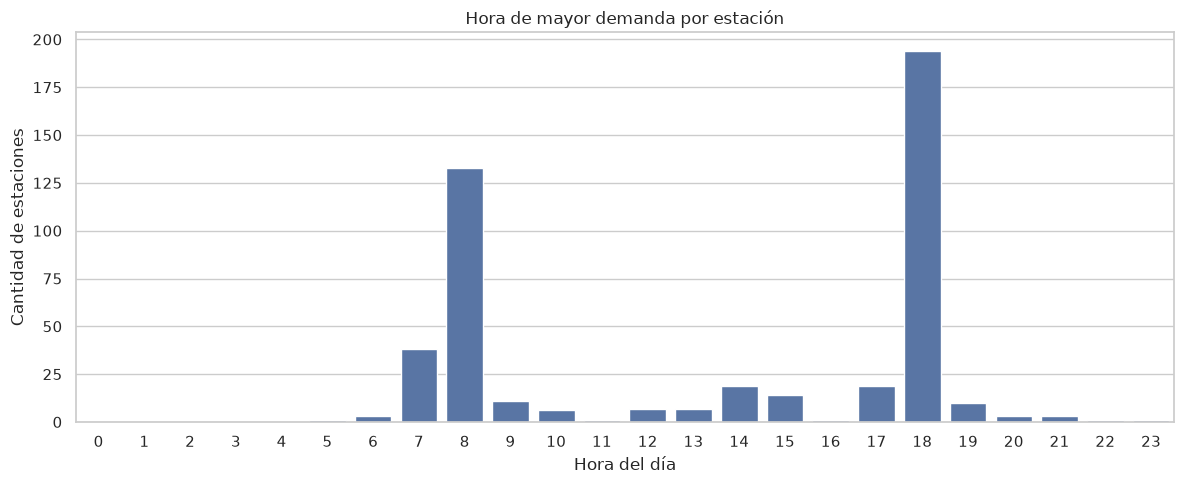

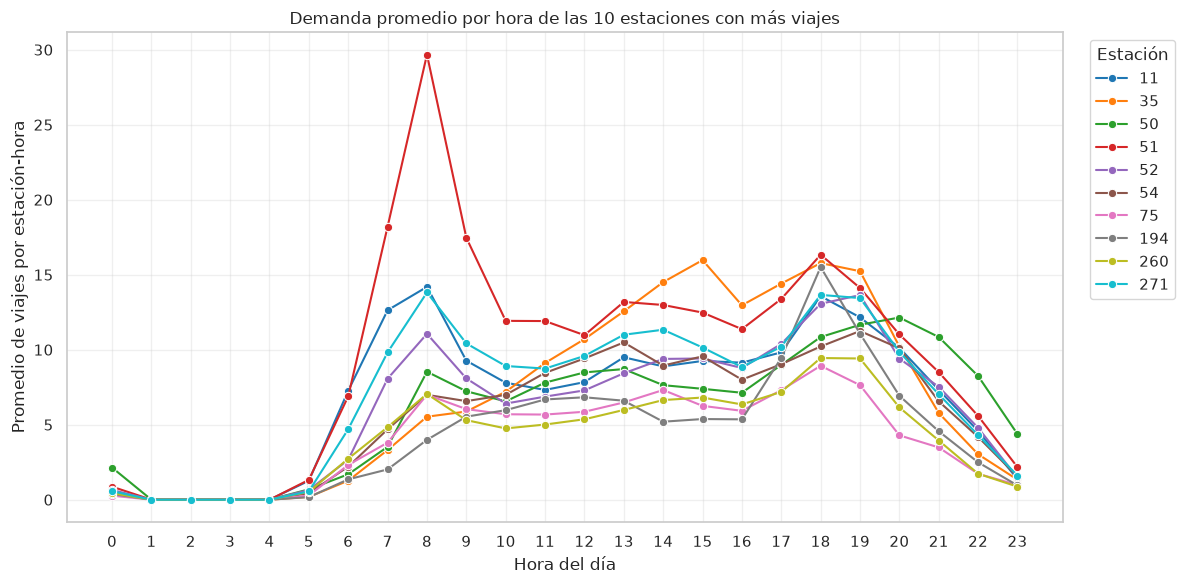

In [149]:
# Analizar los patrones horarios de todas las estaciones.
hourly_parquet_path = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "mibici_hourly_complete.parquet"
)

hourly_summaries = []

parquet_file = pq.ParquetFile(hourly_parquet_path)

for batch in parquet_file.iter_batches(
    batch_size=100_000,
    columns=["Origen_Id", "Hora", "Cantidad_viajes"]
):
    chunk = batch.to_pandas()

    chunk["Hora_dia"] = chunk["Hora"].dt.hour

    summary = (
        chunk.groupby(["Origen_Id", "Hora_dia"])["Cantidad_viajes"]
        .agg(["sum", "count"])
    )

    hourly_summaries.append(summary)

# Consolidar los resultados de todos los bloques.
station_hourly_totals = (
    pd.concat(hourly_summaries)
    .groupby(level=[0, 1])
    .sum()
)

station_hourly_totals["Promedio_viajes"] = (
    station_hourly_totals["sum"]
    / station_hourly_totals["count"]
)

# Identificar la hora con mayor promedio para cada estación.
station_peak_hours = (
    station_hourly_totals["Promedio_viajes"]
    .reset_index()
    .sort_values(
        ["Origen_Id", "Promedio_viajes", "Hora_dia"],
        ascending=[True, False, True]
    )
    .drop_duplicates("Origen_Id")
    .rename(columns={
        "Hora_dia": "Hora_pico",
        "Promedio_viajes": "Promedio_hora_pico"
    })
)

# Calcular el promedio general de cada estación.
station_average = (
    station_hourly_totals
    .groupby(level=0)[["sum", "count"]]
    .sum()
)

station_average["Promedio_general"] = (
    station_average["sum"]
    / station_average["count"]
)

# Comparar la hora pico con el promedio general.
station_peak_analysis = station_peak_hours.merge(
    station_average[["Promedio_general"]],
    left_on="Origen_Id",
    right_index=True
)

station_peak_analysis["Relacion_pico_promedio"] = (
    station_peak_analysis["Promedio_hora_pico"]
    / station_peak_analysis["Promedio_general"].replace(0, np.nan)
)

station_peak_analysis = station_peak_analysis.sort_values(
    "Origen_Id"
).reset_index(drop=True)

print("Estaciones analizadas:", len(station_peak_analysis))

display(station_peak_analysis.round(2))

# Contar cuántas estaciones tienen su pico en cada hora.
peak_distribution = (
    station_peak_analysis["Hora_pico"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

# Gráfica 1: distribución de las horas pico.
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    x=peak_distribution.index,
    y=peak_distribution.values,
    ax=ax
)

ax.set_title("Hora de mayor demanda por estación")
ax.set_xlabel("Hora del día")
ax.set_ylabel("Cantidad de estaciones")

plt.tight_layout()
plt.show()

# Gráfica 2: perfiles horarios de las 10 estaciones
# con mayor cantidad total de viajes.
top_station_ids = (
    station_hourly_totals
    .groupby(level=0)["sum"]
    .sum()
    .nlargest(10)
    .index
)

top_station_profiles = (
    station_hourly_totals["Promedio_viajes"]
    .reset_index()
)

top_station_profiles = top_station_profiles[
    top_station_profiles["Origen_Id"].isin(top_station_ids)
]

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=top_station_profiles,
    x="Hora_dia",
    y="Promedio_viajes",
    hue="Origen_Id",
    estimator=None,
    marker="o",
    palette="tab10",
    ax=ax
)

ax.set_title(
    "Demanda promedio por hora de las 10 estaciones con más viajes"
)
ax.set_xlabel("Hora del día")
ax.set_ylabel("Promedio de viajes por estación-hora")
ax.set_xticks(range(24))
ax.legend(title="Estación", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación de resultados**

Analizamos los patrones horarios de las 472 estaciones y observamos que la mayoría concentra su demanda máxima alrededor de las 8:00 y las 18:00. Esto coincide con los horarios de mayor actividad que habíamos identificado anteriormente.

Sin embargo, también encontramos diferencias entre estaciones. Por ejemplo, la estación 51 presenta un pico muy marcado durante la mañana, mientras que otras, como la 35 y la 50, registran mayor actividad durante la tarde o la noche.

Estos resultados muestran que no todas las estaciones tienen el mismo comportamiento. Por lo tanto, consideramos importante utilizar tanto la estación de origen como la hora del día cuando posteriormente desarrollemos el modelo predictivo.

### 8.10. Principales hallazgos del análisis exploratorio

Después de analizar los registros de viajes de enero de 2020 a septiembre de 2026, identificamos los siguientes hallazgos:

1. **La mayoría de las estaciones registra pocos viajes por hora (sección 8.3).** Encontramos que el 53.3% de los registros tiene cero salidas y el 27.5% presenta entre uno y dos viajes. Esto significa que, durante muchas horas, las estaciones tienen poca actividad. Es importante recordar que algunos de estos ceros fueron agregados para completar los horarios sin viajes registrados.

2. **La demanda aumenta principalmente por la mañana y por la tarde (sección 8.4).** Observamos dos horarios con mayor actividad: las 8:00 y las 18:00. Esto podría estar relacionado con los traslados hacia el trabajo o la escuela y el regreso a casa, aunque necesitaríamos revisar las rutas para comprobarlo.

3. **Entre semana se utilizan más las bicicletas (secciones 8.5 y 8.8).** Los martes y miércoles presentan los promedios más altos, mientras que los domingos tienen la menor actividad. Además, los fines de semana la demanda se concentra más durante el mediodía, a diferencia de los días laborales.

4. **No todas las estaciones tienen la misma demanda (sección 8.6).** Encontramos estaciones con una actividad considerablemente mayor que otras. Por ejemplo, la estación 51 registra un promedio de 9.60 salidas por hora, mientras que algunas estaciones tienen promedios inferiores a un viaje. Esto nos muestra que la ubicación de la estación podría ser importante para explicar la demanda.

5. **La cantidad de viajes ha cambiado a lo largo de los años (sección 8.7).** Encontramos una caída importante en abril de 2020, posiblemente relacionada con la pandemia. Posteriormente, la demanda comenzó a recuperarse. También observamos un incremento destacado en septiembre de 2026, cuando se registraron 489,298 viajes.

6. **Existen diferencias entre los meses del año (sección 8.9).** Septiembre y octubre presentan una demanda relativamente elevada, mientras que diciembre tiene uno de los promedios diarios más bajos. Sin embargo, este comportamiento no se repite exactamente todos los años, por lo que no podemos atribuirlo únicamente a la temporada.

7. **Algunas estaciones presentan aumentos de demanda poco habituales (secciones 8.9.1 y 8.9.2).** La estación 194 alcanzó 207 salidas en una sola hora, aunque su promedio es de 4.44. También encontramos diferencias importantes en otras estaciones. Por ahora decidimos conservar estos registros, ya que una cantidad elevada de viajes no necesariamente significa que exista un error.

8. **Cada estación puede tener horarios de mayor actividad diferentes (sección 8.9.3).** Aunque las 8:00 y las 18:00 son los horarios más frecuentes de mayor demanda, encontramos estaciones con picos en otros momentos del día. Por ejemplo, la estación 51 presenta un incremento muy marcado durante la mañana, mientras que otras tienen mayor actividad por la tarde o la noche.

### Conclusión general

Los resultados muestran que la demanda de bicicletas no es igual en todas las estaciones ni se mantiene constante durante el día. La hora, el día de la semana, la estación de origen y los cambios a lo largo del año parecen ser factores importantes.

Por esta razón, consideramos que estas variables podrían ser útiles para desarrollar posteriormente un modelo que permita estimar cuántos viajes saldrán de cada estación en un horario determinado.

También debemos considerar que los datos nos muestran los viajes realizados, pero no necesariamente toda la demanda existente, ya que desconocemos si en algún momento hubo usuarios que no pudieron retirar una bicicleta por falta de disponibilidad.

## 9. Medición de tiempos y cuellos de botella

Mediremos las principales operaciones de limpieza y análisis para identificar cuáles tardan más antes de refactorizar. Para la limpieza utilizaremos **una muestra de un archivo CSV original** y las mismas funciones de normalización, validación y estrategias A/B definidas anteriormente. Así evitamos repetir el procesamiento de los 81 archivos.

Separaremos los tiempos de lectura, normalización, validaciones, limpieza A, limpieza B y escritura de resultados. Después mediremos la lectura, conversión, agrupación y consolidación del Parquet horario ya generado.

**Alcance de la prueba:** los tiempos de la muestra son comparables dentro de esta ejecución, pero no equivalen a los tiempos históricos de procesar los 81 CSV. Los resultados dependen del equipo, el almacenamiento, el tamaño de la muestra y la carga del sistema. La escritura se realiza en una carpeta temporal y no modifica los archivos definitivos.


### 9.1. Medición de limpieza sobre una muestra

Usamos el primer archivo mensual y hasta `PROCESS_CHUNK_SIZE` registros. Se ejecutan las funciones reales de limpieza sobre copias independientes, para comparar A y B sin afectar el estado del notebook. La escritura se realiza en una carpeta temporal que se elimina al terminar.


Archivo de muestra: datos_abiertos_2020_01.csv
Registros de muestra: 50,000
Conservados A: 48,296
Conservados B: 50,000
Tiempo total de la muestra: 0.70 s


,Etapa,Segundos,Porcentaje_del_total
0,Escritura CSV y Parquet (A y B),0.395,56.716
1,Lectura CSV,0.107,15.392
2,Normalización,0.091,13.070
3,Limpieza A,0.052,7.451
4,Limpieza B,0.046,6.624
5,Validaciones de calidad,0.005,0.747


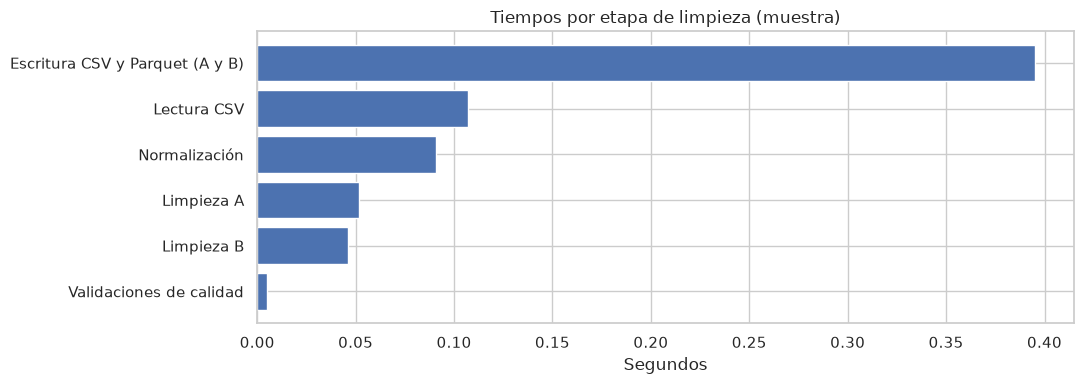

In [150]:
# Medir las etapas de limpieza usando una muestra real, sin procesar los 81 CSV.
# Reutiliza normalize_chunk, validate_domain, clean_strategy_a y clean_strategy_b.
from tempfile import TemporaryDirectory

BENCHMARK_CLEANING_ROWS = PROCESS_CHUNK_SIZE
BENCHMARK_CLEANING_FILE = monthly_files[0]

if BENCHMARK_CLEANING_ROWS <= 0:
    raise ValueError("El tamaño de muestra debe ser positivo.")

cleaning_times = {}

start = perf_counter()
raw_sample = pd.read_csv(
    BENCHMARK_CLEANING_FILE,
    encoding=file_encodings[BENCHMARK_CLEANING_FILE.name],
    dtype="string",
    nrows=BENCHMARK_CLEANING_ROWS
)
cleaning_times["Lectura CSV"] = perf_counter() - start

start = perf_counter()
normalized_sample = normalize_chunk(raw_sample)
cleaning_times["Normalización"] = perf_counter() - start

start = perf_counter()
missing_summary = count_missing_values(normalized_sample)
domain_summary = validate_domain(normalized_sample)
cleaning_times["Validaciones de calidad"] = perf_counter() - start

start = perf_counter()
cleaned_sample_a, summary_sample_a, _ = clean_strategy_a(
    normalized_sample, seen_ids=set()
)
cleaning_times["Limpieza A"] = perf_counter() - start

start = perf_counter()
cleaned_sample_b, summary_sample_b, _ = clean_strategy_b(
    normalized_sample, seen_ids=set()
)
cleaning_times["Limpieza B"] = perf_counter() - start

# Escribir una muestra temporal, sin tocar los archivos definitivos.
with TemporaryDirectory(prefix="mibici_benchmark_") as temp_dir:
    temp_dir = Path(temp_dir)
    start = perf_counter()
    for strategy, cleaned in (("A", cleaned_sample_a), ("B", cleaned_sample_b)):
        cleaned.to_csv(temp_dir / f"sample_{strategy}.csv", index=False)
        cleaned.to_parquet(temp_dir / f"sample_{strategy}.parquet", index=False)
    cleaning_times["Escritura CSV y Parquet (A y B)"] = perf_counter() - start

cleaning_benchmark = pd.DataFrame({
    "Etapa": list(cleaning_times),
    "Segundos": list(cleaning_times.values())
}).sort_values("Segundos", ascending=False, ignore_index=True)

cleaning_benchmark["Porcentaje_del_total"] = (
    cleaning_benchmark["Segundos"] / cleaning_benchmark["Segundos"].sum() * 100
)

assert summary_sample_a["original_rows"] == len(raw_sample)
assert summary_sample_b["original_rows"] == len(raw_sample)

print("Archivo de muestra:", BENCHMARK_CLEANING_FILE.name)
print(f"Registros de muestra: {len(raw_sample):,}")
print(f"Conservados A: {len(cleaned_sample_a):,}")
print(f"Conservados B: {len(cleaned_sample_b):,}")
print(f"Tiempo total de la muestra: {sum(cleaning_times.values()):.2f} s")
display(cleaning_benchmark.round(3))

fig, ax = plt.subplots(figsize=(11, 4))
ax.barh(cleaning_benchmark["Etapa"], cleaning_benchmark["Segundos"])
ax.invert_yaxis()
ax.set_xlabel("Segundos")
ax.set_title("Tiempos por etapa de limpieza (muestra)")
plt.tight_layout()
plt.show()


### 9.2. Medición del análisis horario

Ahora medimos las operaciones del Parquet horario completo, que ya existe. Estos tiempos se muestran por separado porque procesan una cantidad de datos diferente a la muestra de limpieza.


Registros recorridos: 19,323,669
Tiempo total medido: 1.80 segundos
Tamaño del Parquet: 166.2 MB
Etapa con mayor tiempo: Agrupación por estación y hora


,Etapa,Segundos,Porcentaje_del_total
0,Agrupación por estación y hora,0.95,52.79
1,Lectura de bloques Parquet,0.65,36.17
2,Conversión de bloques a pandas,0.18,10.26
3,Consolidación de resultados,0.01,0.70


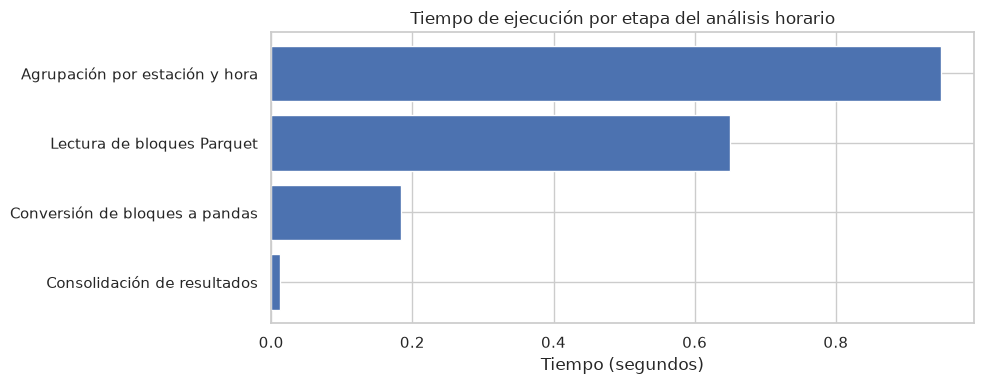

In [151]:
# Medir etapas representativas del EDA sin repetir la limpieza de los CSV.
# perf_counter, Path, pandas y pyarrow.parquet ya se importaron al inicio.

benchmark_path = PROJECT_DIR / "data" / "processed" / "mibici_hourly_complete.parquet"

if not benchmark_path.is_file():
    raise FileNotFoundError(f"No se encontró el archivo: {benchmark_path}")

benchmark_file = pq.ParquetFile(benchmark_path)
benchmark_records = 0
benchmark_groups = []
read_seconds = 0.0
convert_seconds = 0.0
group_seconds = 0.0

benchmark_start = perf_counter()
batch_iterator = benchmark_file.iter_batches(
    batch_size=100_000,
    columns=["Origen_Id", "Hora", "Cantidad_viajes"]
)

while True:
    read_start = perf_counter()
    try:
        batch = next(batch_iterator)
    except StopIteration:
        break
    read_seconds += perf_counter() - read_start

    convert_start = perf_counter()
    chunk = batch.to_pandas()
    convert_seconds += perf_counter() - convert_start

    group_start = perf_counter()
    chunk["Hora_dia"] = chunk["Hora"].dt.hour
    partial_summary = chunk.groupby(["Origen_Id", "Hora_dia"])["Cantidad_viajes"].agg(
        ["sum", "count"]
    )
    benchmark_groups.append(partial_summary)
    group_seconds += perf_counter() - group_start
    benchmark_records += len(chunk)

consolidation_start = perf_counter()
benchmark_summary = (
    pd.concat(benchmark_groups)
    .groupby(level=[0, 1])
    .sum()
)
consolidation_seconds = perf_counter() - consolidation_start
benchmark_total_seconds = perf_counter() - benchmark_start

benchmark_timings = pd.DataFrame({
    "Etapa": [
        "Lectura de bloques Parquet",
        "Conversión de bloques a pandas",
        "Agrupación por estación y hora",
        "Consolidación de resultados",
    ],
    "Segundos": [
        read_seconds,
        convert_seconds,
        group_seconds,
        consolidation_seconds,
    ],
}).sort_values("Segundos", ascending=False, ignore_index=True)

benchmark_timings["Porcentaje_del_total"] = (
    benchmark_timings["Segundos"] / benchmark_total_seconds * 100
)

print(f"Registros recorridos: {benchmark_records:,}")
print(f"Tiempo total medido: {benchmark_total_seconds:.2f} segundos")
print(f"Tamaño del Parquet: {benchmark_path.stat().st_size / (1024 ** 2):.1f} MB")
print("Etapa con mayor tiempo:", benchmark_timings.loc[0, "Etapa"])
display(benchmark_timings.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(benchmark_timings["Etapa"], benchmark_timings["Segundos"])
ax.invert_yaxis()
ax.set_xlabel("Tiempo (segundos)")
ax.set_title("Tiempo de ejecución por etapa del análisis horario")
plt.tight_layout()
plt.show()


### Interpretación de resultados

Medimos los tiempos de ejecución para identificar qué partes del código podríamos mejorar durante la refactorización.

En la limpieza de 50,000 registros, el proceso tardó 0.70 segundos. La escritura de archivos CSV y Parquet fue la operación más lenta, con el 56.72% del tiempo.

En el análisis horario procesamos más de 19 millones de registros en 1.80 segundos. Aquí, la agrupación por estación y hora consumió el 52.79% del tiempo.

Con estos resultados identificamos dos puntos importantes para revisar: **la escritura de archivos durante la limpieza y las agrupaciones durante el análisis**.

Por ahora, estas mediciones nos sirven como referencia. Tendremos que repetirlas para comprobar si los cambios de la refactorización realmente mejoran los tiempos sin alterar los resultados.

## 10. Preparación para la refactorización

El notebook conserva el orden de exploración, diagnóstico, limpieza y EDA. La siguiente etapa será trasladar la lógica reutilizable a módulos `.py`, sin cambiar los criterios de limpieza ni los resultados.

**Decisiones que debemos conservar**

- **Variable objetivo:** `Cantidad_viajes`, definida como el número de salidas por estación (`Origen_Id`) y hora (`Hora`). El análisis actual no calcula entradas ni disponibilidad real de bicicletas.
- **Periodo:** enero de 2020 a septiembre de 2026, con `STUDY_END` exclusivo.
- **Calidad:** conservar las reglas del Data Contract, las pruebas P01–P09 y la comparación de estrategias A y B.
- **Estrategia elegida:** B. Mantener los archivos originales sin cambios y conservar la trazabilidad de registros excluidos y corregidos.
- **Horas sin viajes:** completar solo desde la primera hasta la última hora observada de cada estación. Estos ceros son inferidos, no evidencia de operación.
- **Procesamiento:** utilizar bloques y Parquet; evitar cargar simultáneamente todos los viajes o todas las horas completas en pandas.

**Aspectos pendientes antes de considerar el código refactorizado**

1. Centralizar los tamaños de bloque y las rutas de salida en una configuración. En distintas etapas se usan valores como `10_000`, `50_000`, `100_000`, `200_000` y `250_000`, con propósitos diferentes; no deben unificarse sin comprobar su efecto.
2. Separar la lógica de lectura, validación, limpieza, construcción de la variable objetivo y análisis en funciones pequeñas. Las celdas del notebook deberían llamar esas funciones y mostrar resultados, no contener toda la implementación.
3. Eliminar dependencias ocultas entre celdas. Cada función debe recibir explícitamente sus entradas y devolver sus resultados; no depender de variables creadas en otra sección.
4. Convertir las pruebas de ejemplo en pruebas automatizadas, especialmente duplicados entre bloques, conservación de registros, tipos de datos y conteos por estación-hora.
5. Mejorar la construcción inicial del Parquet horario (8.1), que todavía acumula resúmenes parciales en memoria, y la detección de valores atípicos por estación (8.9.2), que acumula los valores de las estaciones para calcular percentiles.
6. Registrar tiempos de cada etapa durante futuras ejecuciones completas. La sección 9 ya compara lectura, normalización, validación, limpieza A/B y escritura sobre una muestra, además del EDA, pero no reconstruye los tiempos históricos de los 81 archivos.
7. Ejecutar desde un entorno limpio las pruebas y el flujo completo antes de declarar que la refactorización está terminada. Los resultados guardados permiten reanudar el trabajo sin reprocesar los 81 CSV, pero eso no sustituye una prueba de ejecución integral.

### Uso de IA

- OpenAI. (2026). *ChatGPT*. Utilizado como apoyo para el desarrollo y revisión de código, depuración, organización del notebook y comparación de las implementaciones mediante funciones y programación orientada a objetos (OOP). https://chatgpt.com/